In [ ]:
# same as ./zzzz/superpixel_validation_sample_stage2_GMM.ipynb

In [ ]:
# ★config
from glob import glob
import os
import numpy as np
from glob import glob
import os
import re

def natural_sort_key(path):
    filename = os.path.basename(path)
    return [
        int(text) if text.isdigit() else text
        for text in re.split(r'(\d+)', filename)
    ]


image_paths = sorted(
    # glob(os.path.join("./sample6", "*.jpg")),
    # glob(os.path.join("/home/kmanabe2403/document/dune/superpixel/validation3/training3_low/data2/low_confidence_image", "*.jpg")),
    # glob(os.path.join("/home/kmanabe2403/document/dune/superpixel/validation3/training3_low/data2/image", "*.jpg")),
    # glob(os.path.join("/home/kmanabe2403/document/dune/superpixel/validation3/training3_low/stage1_GMM/data3/image", "*.jpg")),
    glob(os.path.join("/home/kmanabe2403/document/dune/superpixel/validation3/training3_low/stage1_GMM/data3/image", "*.jpg")),
    key=natural_sort_key
)

print("loaded", len(image_paths), "files")
# for i, path in enumerate(image_paths):
#     print(f"Image {i}: {os.path.basename(path)}")

# model_paths = "random_forest_model2.pkl"
model_paths_stage1 = "validation3/training3_low/RFmodel5/rf_vali3_stage1_C3T5.pkl"
path_for_data = "validation3/training3_low/stage1_GMM/data3"
# path_for_data = "validation3/training3_low/stage1_GMM/data21"


param_n_segments = 300
param_compactness = 10.0

loaded 166 files


In [ ]:
# ★load result
save_dir = os.path.join(path_for_data, "superpixel_data")
n_images = len(image_paths)

images = [np.load(os.path.join(save_dir, "images", f"image_{i:03d}.npy")) for i in range(n_images)]
segments_list = [np.load(os.path.join(save_dir, "segments", f"segments_{i:03d}.npy")) for i in range(n_images)]

all_sp_lab_means = np.load(os.path.join(save_dir, "all_sp_lab_means.npy"))
lab_corrections = np.load(os.path.join(path_for_data, "superpixel_data", "lab_corrections.npy"))
all_image_ids = np.load(os.path.join(path_for_data, "RF_features", "all_image_ids.npy"))
all_labels = np.load(os.path.join(path_for_data, "RF_features", "all_labels.npy"))
# rf_labels = np.load(os.path.join(path_for_data, "rf_labels.npy"))
# rf_probabilities = np.load(os.path.join(path_for_data, "rf_probabilities.npy"))

feature_names = [
    "Variance", "Gradient", "Entropy", "Edge density", "Coherence",
    "L", "a", "b", "Brightness range", "LBP",
    "Coherence std", "Coherence p90",
    "GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation",
    "Edge dominant angle", "Edge angle entropy"
]
features = {name: np.load(os.path.join(path_for_data, "RF_features", f"features_{name}.npy")) for name in feature_names}

print("Loaded:")
print("Images:", len(images))
print("Segments:", len(segments_list))
print("Superpixels:", len(all_image_ids))
# print("RF labels:", rf_labels.shape)
# print("RF probabilities:", rf_probabilities.shape)

In [ ]:
# 0crop
import matplotlib.pyplot as plt
from skimage import io
from skimage.color import rgb2lab
from skimage.segmentation import slic, mark_boundaries
import numpy as np
from skimage.color import label2rgb
from sklearn.cluster import KMeans
from skimage import img_as_ubyte
from skimage.color import lab2rgb

lab_stats = []

for i, path in enumerate(image_paths):
    img = io.imread(path)

    top = 60
    bottom = 100
    left = 60
    right = 100
    img = img[top:img.shape[0]-bottom, left:img.shape[1]-right]
    lab = rgb2lab(img)

    lab_stats.append([np.mean(lab[:,:,0]), np.mean(lab[:,:,1]), np.mean(lab[:,:,2])])

lab_stats = np.array(lab_stats)
# plt.figure(figsize=(8,5))
# plt.plot(range(1,len(image_paths)+1),lab_stats[:,0],"o-",label="L")
# plt.plot(range(1,len(image_paths)+1),lab_stats[:,1],"o-",label="a")
# plt.plot(range(1,len(image_paths)+1), lab_stats[:,2], "o-", label="b")
# plt.xlabel("Image")
# plt.ylabel("Mean Lab value")
# plt.title("Color variation between images")
# plt.legend()
# plt.grid()
# plt.show()

In [ ]:
# 0superpixel
import matplotlib.pyplot as plt
import numpy as np
from skimage import io
from skimage.color import rgb2lab, lab2rgb
from skimage.segmentation import slic, mark_boundaries
from skimage.color import label2rgb

all_sp_lab_means = []
all_image_ids = []
images = []
segments_list = []

for image_id, path in enumerate(image_paths):
    image = io.imread(path)
    image = image[top:image.shape[0]-bottom,left:image.shape[1]-right]
    image_lab = rgb2lab(image)

    segments = slic(image_lab, n_segments=param_n_segments, compactness=param_compactness, sigma=1, start_label=1)

    unique_labels = np.unique(segments)
    sp_lab_means = []

    for label in unique_labels:
        mask = segments == label
        sp_lab_means.append(image_lab[mask].mean(axis=0))

    sp_lab_means = np.array(sp_lab_means)

    all_sp_lab_means.append(sp_lab_means)
    all_image_ids.extend([image_id]*len(sp_lab_means))

    images.append(image)
    segments_list.append(segments)

all_sp_lab_means = np.vstack(all_sp_lab_means)
all_image_ids = np.array(all_image_ids)

print("Total superpixels:", len(all_sp_lab_means))

Total superpixels: 41216


In [ ]:
# 0color correction
import joblib

model_package = joblib.load(model_paths_stage1)
reference_mean = model_package["reference_mean"]
np.save(os.path.join(path_for_data, "reference_mean.npy"), reference_mean)
print("Saved reference_mean.npy:", reference_mean)

print("Training reference mean:")
print(reference_mean)


corrected_sp_lab_means = []
lab_corrections = []

for i in range(len(image_paths)):
    mask = all_image_ids == i

    current_mean = all_sp_lab_means[mask].mean(axis=0)
    correction = reference_mean - current_mean
    lab_corrections.append(correction)

    corrected = all_sp_lab_means[mask] + correction
    corrected_sp_lab_means.append(corrected)


corrected_sp_lab_means = np.vstack(corrected_sp_lab_means)
lab_corrections = np.array(lab_corrections)

# print("New image Lab corrections:")
# print(lab_corrections)

Saved reference_mean.npy: [ 55.53511175 -31.4483002   32.61843659]
Training reference mean:
[ 55.53511175 -31.4483002   32.61843659]


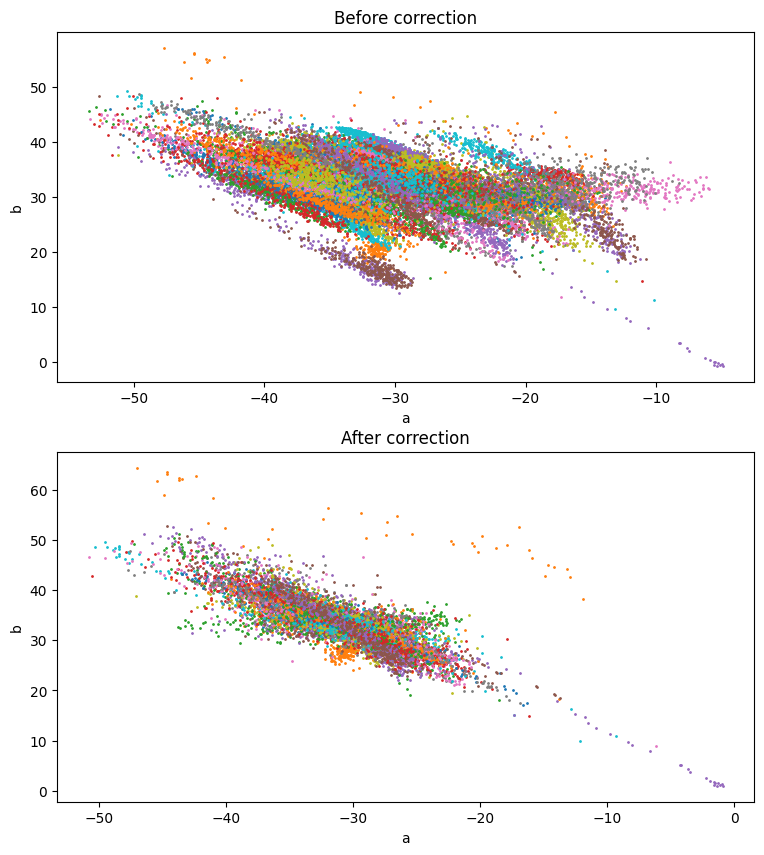

In [ ]:
# 0pic：color correction
reference_mean = np.mean(all_sp_lab_means, axis=0)
corrected_sp_lab_means = []

for i in range(len(image_paths)):
    mask = all_image_ids == i
    current_mean = all_sp_lab_means[mask].mean(axis=0)
    correction = reference_mean - current_mean
    corrected = all_sp_lab_means[mask] + correction
    corrected_sp_lab_means.append(corrected)

corrected_sp_lab_means = np.vstack(corrected_sp_lab_means)



fig, axes = plt.subplots(2,1,figsize=(9,10))

axes[0].set_title("Before correction")
for i in range(len(image_paths)):
    mask = all_image_ids==i
    axes[0].scatter(all_sp_lab_means[mask,1], all_sp_lab_means[mask,2], s=1, label=f"Image {i+1}")
axes[0].set_xlabel("a")
axes[0].set_ylabel("b")
# axes[0].legend()
# axes[0].grid()

axes[1].set_title("After correction")
for i in range(len(image_paths)):
    mask = all_image_ids==i
    axes[1].scatter(corrected_sp_lab_means[mask,1], corrected_sp_lab_means[mask,2], s=1, label=f"Image {i+1}")
axes[1].set_xlabel("a")
axes[1].set_ylabel("b")
# axes[1].legend()
# axes[1].grid()

plt.show()

In [ ]:
# ★save result
import os
import numpy as np
save_dir = os.path.join(path_for_data, "superpixel_data")
os.makedirs(save_dir, exist_ok=True)
os.makedirs(os.path.join(save_dir, "images"), exist_ok=True)
os.makedirs(os.path.join(save_dir, "segments"), exist_ok=True)

# 画像ごとの image / segments
for image_id, (image, segments) in enumerate(zip(images, segments_list)):
    np.save(os.path.join(save_dir, "images", f"image_{image_id:03d}.npy"), image)
    np.save(os.path.join(save_dir, "segments", f"segments_{image_id:03d}.npy"), segments)

# 全画像共通の情報
np.save(os.path.join(save_dir, "all_sp_lab_means.npy"), all_sp_lab_means)
np.save(os.path.join(save_dir, "lab_corrections.npy"), np.asarray(lab_corrections, dtype=np.float32))
# np.save(os.path.join(path_for_data, "RF_features", "all_image_ids.npy"), np.asarray(all_image_ids, dtype=np.int32))
# np.save(os.path.join(path_for_data, "RF_features", "all_labels.npy"), np.asarray(all_labels, dtype=np.int32))
# for name in features:
#     np.save(os.path.join(path_for_data, f"features_{name}.npy"), np.asarray(features[name], dtype=np.float32))
# print("SLIC, feature, RF results saved:", save_dir)

In [ ]:
# 0calculate features
import os, gc
import numpy as np
from skimage.color import rgb2gray, rgb2lab
from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage.feature import structure_tensor, structure_tensor_eigenvalues, local_binary_pattern, graycomatrix, graycoprops

def calculate_rf_features(image_paths, path_for_data, lab_corrections):
    save_dir = os.path.join(path_for_data, "superpixel_data")
    image_dir = os.path.join(save_dir, "images")
    segment_dir = os.path.join(save_dir, "segments")
    output_dir = os.path.join(path_for_data, "RF_features")
    os.makedirs(output_dir, exist_ok=True)

    edge_threshold = 0.05
    feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b", "Brightness range", "LBP", "Coherence std", "Coherence p90", "GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation", "Edge dominant angle", "Edge angle entropy"]

    all_features = {name: [] for name in feature_names}
    all_image_ids = []
    all_labels = []
    total_images = len(image_paths)

    for image_id in range(total_images):
        if (image_id + 1) % 10 == 0 or image_id == 0:
            print(f"Processing image {image_id+1}/{total_images}...", flush=True)

        image = np.load(os.path.join(image_dir, f"image_{image_id:03d}.npy"))
        segments = np.load(os.path.join(segment_dir, f"segments_{image_id:03d}.npy"))

        image_lab = rgb2lab(image).astype(np.float32)
        image_lab[:, :, 0] += lab_corrections[image_id, 0]
        image_lab[:, :, 1] += lab_corrections[image_id, 1]
        image_lab[:, :, 2] += lab_corrections[image_id, 2]

        gray = rgb2gray(image).astype(np.float32)
        gray_uint = np.clip(gray * 255, 0, 255).astype(np.uint8)

        entropy_img = entropy(gray_uint, disk(3)).astype(np.float32)
        gy, gx = np.gradient(gray)
        gradient_img = np.sqrt(gx**2 + gy**2).astype(np.float32)
        edge_angle_img = np.arctan2(gy, gx).astype(np.float32)

        A = structure_tensor(gray, sigma=2)
        l1, l2 = structure_tensor_eigenvalues(A)
        coherence_img = ((l1-l2)/(l1+l2+1e-10)).astype(np.float32)

        lbp_img = local_binary_pattern(gray_uint, P=8, R=1, method="uniform").astype(np.float32)

        unique_labels = np.unique(segments)

        for label in unique_labels:
            mask = segments == label
            n_pixels = np.sum(mask)

            if n_pixels < 2:
                feat = {name: 0.0 for name in feature_names}
            else:
                values = gray[mask]
                coherence_values = coherence_img[mask]
                angles = edge_angle_img[mask]

                hist, bins = np.histogram(angles, bins=18, range=(-np.pi, np.pi))
                p = hist / (np.sum(hist) + 1e-10)

                ys, xs = np.where(mask)
                crop = gray_uint[ys.min():ys.max()+1, xs.min():xs.max()+1]

                if crop.size > 4:
                    glcm = graycomatrix(crop, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
                    glcm_contrast = graycoprops(glcm, "contrast")[0, 0]
                    glcm_homogeneity = graycoprops(glcm, "homogeneity")[0, 0]
                    glcm_energy = graycoprops(glcm, "energy")[0, 0]
                    glcm_correlation = graycoprops(glcm, "correlation")[0, 0]
                    del glcm
                else:
                    glcm_contrast = glcm_homogeneity = glcm_energy = glcm_correlation = 0.0

                feat = {
                    "L": np.mean(image_lab[:, :, 0][mask]),
                    "a": np.mean(image_lab[:, :, 1][mask]),
                    "b": np.mean(image_lab[:, :, 2][mask]),
                    "Brightness range": np.max(values) - np.min(values),
                    "Variance": np.var(values),
                    "Gradient": np.mean(gradient_img[mask]),
                    "Entropy": np.mean(entropy_img[mask]),
                    "Edge density": np.sum(gradient_img[mask] > edge_threshold) / n_pixels,
                    "LBP": np.mean(lbp_img[mask]),
                    "Coherence": np.mean(coherence_values),
                    "Coherence std": np.std(coherence_values),
                    "Coherence p90": np.percentile(coherence_values, 90),
                    "GLCM contrast": glcm_contrast,
                    "GLCM homogeneity": glcm_homogeneity,
                    "GLCM energy": glcm_energy,
                    "GLCM correlation": glcm_correlation,
                    "Edge dominant angle": bins[np.argmax(hist)],
                    "Edge angle entropy": -np.sum(p * np.log(p + 1e-10))
                }

            for name in feature_names:
                all_features[name].append(feat[name])
            all_image_ids.append(image_id)
            all_labels.append(label)

        del image, segments, image_lab, gray, gray_uint, entropy_img, gy, gx, gradient_img, edge_angle_img, A, l1, l2, coherence_img, lbp_img
        gc.collect()

    all_image_ids = np.asarray(all_image_ids, dtype=np.int32)
    all_labels = np.asarray(all_labels, dtype=np.int32)

    for name in feature_names:
        all_features[name] = np.asarray(all_features[name], dtype=np.float32)
        np.save(os.path.join(output_dir, f"features_{name}.npy"), all_features[name])

    np.save(os.path.join(output_dir, "all_image_ids.npy"), all_image_ids)
    np.save(os.path.join(output_dir, "all_labels.npy"), all_labels)

    print("\nFinished!")
    print("Number of superpixels:", len(all_image_ids))
    print("Number of features:", len(feature_names))
    print("Saved to:", output_dir)

    return all_features, all_image_ids, all_labels

features, all_image_ids, all_labels = calculate_rf_features(
    image_paths=image_paths,
    path_for_data=path_for_data,
    lab_corrections=lab_corrections
)

np.save(os.path.join(path_for_data, "RF_features", "all_image_ids.npy"), np.asarray(all_image_ids, dtype=np.int32))
np.save(os.path.join(path_for_data, "RF_features", "all_labels.npy"), np.asarray(all_labels, dtype=np.int32))

Processing image 1/166...
Processing image 10/166...
Processing image 20/166...
Processing image 30/166...
Processing image 40/166...
Processing image 50/166...
Processing image 60/166...
Processing image 70/166...
Processing image 80/166...
Processing image 90/166...
Processing image 100/166...
Processing image 110/166...
Processing image 120/166...
Processing image 130/166...
Processing image 140/166...
Processing image 150/166...
Processing image 160/166...

Finished!
Number of superpixels: 41216
Number of features: 18
Saved to: validation3/training3_low/stage1_GMM/data3/RF_features


In [ ]:
# GMM clustering 1
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from matplotlib.backends.backend_pdf import PdfPages
import numpy as np
import matplotlib.pyplot as plt
import os
import gc

# gmm_feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b"]
gmm_feature_names = [
    "Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b",
    "Brightness range", "LBP", "Coherence std", "Coherence p90",
    "GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation",
    "Edge dominant angle", "Edge angle entropy"
]

# # 画像ごとのGMM cluster数
# gmm_n_components = [
#     3, 3, 1, 1, 1, 1, 1, 1, 1, 1,
#     1, 2, 1, 1, 1, 2, 2, 2, 2, 2,
#     1, 1, 2, 2, 1, 1, 1, 1, 1, 1,
#     2, 2, 1, 1, 1, 1, 1, 1, 1, 1,
#     3, 3, 2, 2, 1, 1, 2, 2, 2, 2,
#     1, 2, 1, 1, 3, 2, 1, 1, 1, 2,
#     3, 3, 1, 2, 2, 2, 2, 2, 3, 2,
#     2, 2, 3, 2
# ]

gmm_n_components = [
    2, 2, 2, 2, 3, 2, 2, 2, 3, 3,
    3, 2, 3, 3, 3, 3, 3, 3, 1, 2,
    2, 2, 1, 1, 1, 1, 1, 2, 2, 2,
    2, 2, 2, 2, 1, 1, 1, 1, 1, 2,
    1, 1, 1, 2, 1, 2, 2, 2, 2, 2,
    2, 2, 2, 2, 2, 2, 1, 1, 2, 2,
    1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 
    1, 1, 1, 1, 1, 1, 2, 2, 2, 2,
    1, 1, 2, 2, 2, 2, 2, 2, 2, 2,
    1, 1,
    3, 3, 1, 1, 1, 1, 1, 1, 1, 1,
    1, 2, 1, 1, 1, 2, 2, 2, 2, 2,
    1, 1, 2, 2, 1, 1, 1, 1, 1, 1,
    2, 2, 1, 1, 1, 1, 1, 1, 1, 1,
    3, 3, 2, 2, 1, 1, 2, 2, 2, 2,
    1, 2, 1, 1, 3, 2, 1, 1, 1, 2,
    3, 3, 1, 2, 2, 2, 2, 2, 3, 2,
    2, 2, 3, 2
]

probability_cut = 0.90
save_dir = os.path.join(path_for_data, "superpixel_data")
output_dir = os.path.join(path_for_data, "pdf_GMM_before_RF")
os.makedirs(output_dir, exist_ok=True)
pages_per_pdf = 10
total_images = len(image_paths)

if len(gmm_n_components) != total_images:
    raise ValueError(f"gmm_n_componentsの数 ({len(gmm_n_components)}) と画像数 ({total_images}) が一致していません。")

n_pdfs = int(np.ceil(total_images / pages_per_pdf))
print(f"Total images: {total_images}")
print(f"Output PDFs: {n_pdfs}")
print(f"Probability cut: {probability_cut}")

for pdf_number in range(n_pdfs):
    start_image = pdf_number * pages_per_pdf
    end_image = min(start_image + pages_per_pdf, total_images)
    pdf_path = os.path.join(output_dir, f"GMM_before_RF_{start_image+1:03d}-{end_image:03d}.pdf")

    if os.path.exists(pdf_path) and os.path.getsize(pdf_path) > 0:
        print(f"\nAlready exists, skip: {pdf_path}")
        continue
    print(f"\nCreating: {pdf_path}")

    with PdfPages(pdf_path) as pdf:
        for image_id in range(start_image, end_image):
            # print(f"  Processing Image {image_id+1}/{total_images} ...", flush=True)
            # 画像とsuperpixelを1枚だけロード
            image = np.load(os.path.join(save_dir, "images", f"image_{image_id:03d}.npy"))
            segments = np.load(os.path.join(save_dir, "segments", f"segments_{image_id:03d}.npy"))
            n_components = gmm_n_components[image_id]
            mask_image = all_image_ids == image_id
            feature_indices = np.where(mask_image)[0]
            # print(f"    N superpixels = {len(feature_indices)}, GMM components = {n_components}", flush=True)

            # GMMが成立しない場合
            if n_components < 1 or len(feature_indices) < max(n_components, 2):
                print("    → GMM skipped")
                fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
                ax.imshow(image, interpolation="none")
                ax.set_title(f"Image {image_id+1}: GMM skipped")
                ax.axis("off")
                pdf.savefig(fig, dpi=300)
                plt.close(fig)
                del image, segments, mask_image, feature_indices
                gc.collect()
                continue

            # feature matrix
            X = np.column_stack([features[name][feature_indices] for name in gmm_feature_names]).astype(np.float64)
            # NaN / inf除去
            valid_mask = np.all(np.isfinite(X), axis=1)
            X = X[valid_mask]
            valid_indices = feature_indices[valid_mask]

            if len(X) < max(n_components, 2):
                print("    → Not enough valid samples for GMM")
                del image, segments, mask_image, feature_indices, X, valid_mask, valid_indices
                gc.collect()
                continue

            # Standardize → PCA
            scaler = StandardScaler()
            X_scaled = scaler.fit_transform(X)
            pca = PCA(n_components=2, random_state=0)
            X_pca = pca.fit_transform(X_scaled)

            # GMM
            gmm = GaussianMixture(n_components=n_components, covariance_type="full", random_state=0, n_init=5, reg_covar=1e-5)
            gmm.fit(X_pca)
            probabilities = gmm.predict_proba(X_pca)
            cluster_labels = np.argmax(probabilities, axis=1)
            max_probability = np.max(probabilities, axis=1)

            # 第1段階GMM結果を保存
            gmm_result_dir = os.path.join(path_for_data, "GMM_results")
            os.makedirs(gmm_result_dir, exist_ok=True)
            np.savez_compressed(
                os.path.join(gmm_result_dir, f"gmm_stage1_{image_id:03d}.npz"),
                valid_indices=valid_indices,
                cluster_labels=cluster_labels,
                probabilities=probabilities,
                max_probability=max_probability,
                n_components=n_components
            )

            # 各superpixelが各clusterに属するprobability
            probabilities = gmm.predict_proba(X_pca)
            # 最大probabilityのcluster
            cluster_labels = np.argmax(probabilities, axis=1)
            # 各superpixelの最大probability
            max_probability = np.max(probabilities, axis=1)
            # high confidence cut
            high_mask = max_probability >= probability_cut
            # print(f"    High probability SPs: {np.sum(high_mask)}/{len(high_mask)} "
            #       f"({100*np.mean(high_mask):.1f}%)", flush=True)

            # # 2行 × cluster数
            # fig, axes = plt.subplots(2, n_components, figsize=(5*n_components, 10), squeeze=False, dpi=150)
            # for cluster_id in range(n_components):
            #     selected = high_mask & (cluster_labels == cluster_id)
            #     selected_indices = valid_indices[selected]
            #     high_image = np.full_like(image, 255)
            #     for global_idx in selected_indices:
            #         label = all_labels[global_idx]
            #         pixel_mask = segments == label
            #         high_image[pixel_mask] = image[pixel_mask]
            #     high_count = np.sum(selected)

            #     ax = axes[0, cluster_id]
            #     ax.imshow(high_image, interpolation="none")
            #     ax.set_title(
            #         f"GMM Cluster {cluster_id+1}\n"
            #         f"High probability ≥ {probability_cut}\n"
            #         f"N = {high_count}",
            #         fontsize=11
            #     )
            #     ax.axis("off")

            #     selected = cluster_labels == cluster_id
            #     selected_indices = valid_indices[selected]
            #     all_image_cluster = np.full_like(image, 255)
            #     for global_idx in selected_indices:
            #         label = all_labels[global_idx]
            #         pixel_mask = segments == label
            #         all_image_cluster[pixel_mask] = image[pixel_mask]
            #     all_count = np.sum(selected)

            #     ax = axes[1, cluster_id]
            #     ax.imshow(all_image_cluster, interpolation="none")
            #     ax.set_title(
            #         f"GMM Cluster {cluster_id+1}\n"
            #         f"No probability cut\n"
            #         f"N = {all_count}",
            #         fontsize=11
            #     )
            #     ax.axis("off")
            #     del high_image, all_image_cluster, selected_indices, selected

            # plt.suptitle(f"Image {image_id+1}: GMM before RF " f"(N = {n_components}, cut = {probability_cut})", fontsize=16)
            # plt.tight_layout(rect=[0, 0, 1, 0.95])
            # pdf.savefig(fig, dpi=300)
            # plt.close(fig)

            # メモリ解放
            # del fig, axes
            del image, segments
            del mask_image, feature_indices, valid_mask, valid_indices
            del X, X_scaled, X_pca
            del scaler, pca, gmm
            del probabilities, cluster_labels, max_probability, high_mask
            gc.collect()
            print(f"  Finished Image {image_id+1}", flush=True)

    print(f"Saved: {pdf_path}", flush=True)
    gc.collect()

print("\nAll GMM PDFs saved.")

Total images: 166
Output PDFs: 17
Probability cut: 0.9

Already exists, skip: validation3/training3_low/stage1_GMM/data3/pdf_GMM_before_RF/GMM_before_RF_001-010.pdf

Creating: validation3/training3_low/stage1_GMM/data3/pdf_GMM_before_RF/GMM_before_RF_011-020.pdf
  Finished Image 11
  Finished Image 12
  Finished Image 13
  Finished Image 14
  Finished Image 15
  Finished Image 16
  Finished Image 17
  Finished Image 18
  Finished Image 19
  Finished Image 20
Saved: validation3/training3_low/stage1_GMM/data3/pdf_GMM_before_RF/GMM_before_RF_011-020.pdf

Creating: validation3/training3_low/stage1_GMM/data3/pdf_GMM_before_RF/GMM_before_RF_021-030.pdf
  Finished Image 21
  Finished Image 22
  Finished Image 23
  Finished Image 24
  Finished Image 25
  Finished Image 26
  Finished Image 27
  Finished Image 28
  Finished Image 29
  Finished Image 30
Saved: validation3/training3_low/stage1_GMM/data3/pdf_GMM_before_RF/GMM_before_RF_021-030.pdf

Creating: validation3/training3_low/stage1_GMM/dat

In [ ]:
# GMM clustering 2
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from matplotlib.backends.backend_pdf import PdfPages
import numpy as np
import matplotlib.pyplot as plt
import os
import gc
# second_gmm_targets = {
#     1:[1,3], 2:[2,3], 18:[1], 20:[1], 32:[1,2], 41:[1], 42:[1,3], 43:[2], 44:[2], 48:[2], 
#     55:[1,3], 56:[1], 60:[2], 61:[1], 62:[2], 70:[1], 71:[1], 73:[1],
# }

second_gmm_targets = {
    4:[1],5:[2],14:[3],31:[1],40:[1,2],85:[1],86:[1],89:[2],
    93:[1,3], 94:[2,3], 110:[1], 112:[1], 124:[1,2], 133:[1], 134:[1,3], 135:[2], 136:[2], 140:[2], 
    147:[1,3], 148:[1], 152:[2], 153:[1], 154:[2], 162:[1], 163:[1], 165:[1],
}


gmm_feature_names = [
    "Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b",
    "Brightness range", "LBP", "Coherence std", "Coherence p90",
    "GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation",
    "Edge dominant angle", "Edge angle entropy"
]

second_gmm_n_components = 2
total_images = len(image_paths)

for image_number, target_clusters in second_gmm_targets.items():
    image_id = image_number - 1

    if image_number < 1 or image_number > total_images:
        print(f"Image {image_number}: invalid image number → skip")
        continue

    # print(f"\nImage {image_number}: Stage2 GMM targets = {target_clusters}")

    gmm_result_dir = os.path.join(path_for_data, "GMM_results")
    result_path = os.path.join(
        gmm_result_dir,
        f"gmm_stage1_{image_id:03d}.npz"
    )

    if not os.path.exists(result_path):
        print(f"  Stage1 result not found → skip")
        continue

    data = np.load(result_path)

    valid_indices = data["valid_indices"]
    cluster_labels = data["cluster_labels"]
    stage1_probabilities = data["probabilities"]
    stage1_max_probability = data["max_probability"]

    for target_cluster in target_clusters:
        target_mask = cluster_labels == (target_cluster - 1)
        target_indices = valid_indices[target_mask]

        if len(target_indices) < second_gmm_n_components:
            print(
                f"  Cluster {target_cluster}: "
                f"N={len(target_indices)} → Stage2 skipped"
            )
            continue

        X_target = np.column_stack(
            [features[name][target_indices] for name in gmm_feature_names]
        ).astype(np.float64)

        valid2 = np.all(np.isfinite(X_target), axis=1)
        X_target = X_target[valid2]
        target_indices = target_indices[valid2]

        if len(target_indices) < second_gmm_n_components:
            print(
                f"  Cluster {target_cluster}: "
                f"valid N={len(target_indices)} → Stage2 skipped"
            )
            continue

        scaler2 = StandardScaler()
        X_scaled2 = scaler2.fit_transform(X_target)

        pca2 = PCA(n_components=2, random_state=0)
        X_pca2 = pca2.fit_transform(X_scaled2)

        gmm2 = GaussianMixture(
            n_components=second_gmm_n_components,
            covariance_type="full",
            random_state=0,
            n_init=5,
            reg_covar=1e-5
        )

        gmm2.fit(X_pca2)

        probabilities2 = gmm2.predict_proba(X_pca2)
        labels2 = np.argmax(probabilities2, axis=1)
        max_probability2 = np.max(probabilities2, axis=1)

        np.savez_compressed(
            os.path.join(
                gmm_result_dir,
                f"gmm_stage2_{image_id:03d}_cluster{target_cluster}.npz"
            ),
            target_indices=target_indices,
            labels=labels2,
            probabilities=probabilities2,
            max_probability=max_probability2,
            parent_cluster=target_cluster
        )

        # print(
        #     f"  Cluster {target_cluster}: "
        #     f"N={len(target_indices)} → "
        #     f"Stage2 {second_gmm_n_components} clusters"
        # )

        del X_target, X_scaled2, X_pca2
        del scaler2, pca2, gmm2
        del probabilities2, labels2, max_probability2
        gc.collect()

    del data
    del valid_indices, cluster_labels
    del stage1_probabilities, stage1_max_probability
    gc.collect()

print("\nAll Stage2 GMM calculations finished.")


All Stage2 GMM calculations finished.


In [ ]:
# # pdf：GMM 1 vs 2
# from matplotlib.backends.backend_pdf import PdfPages
# import numpy as np
# import matplotlib.pyplot as plt
# import os
# import gc

# probability_cut = 0.90
# output_dir = os.path.join(path_for_data, "pdf_GMM_stage2_comparison")
# os.makedirs(output_dir, exist_ok=True)
# save_dir = os.path.join(path_for_data, "superpixel_data")
# pdf_path = os.path.join(output_dir, "GMM_stage2_comparison_all.pdf")

# with PdfPages(pdf_path) as pdf:
#     for image_number, target_clusters in second_gmm_targets.items():
#         image_id = image_number - 1
#         image = np.load(os.path.join(save_dir, "images", f"image_{image_id:03d}.npy"))
#         segments = np.load(os.path.join(save_dir, "segments", f"segments_{image_id:03d}.npy"))

#         for target_cluster in target_clusters:
#             stage1_path = os.path.join(gmm_result_dir, f"gmm_stage1_{image_id:03d}.npz")
#             stage2_path = os.path.join(gmm_result_dir, f"gmm_stage2_{image_id:03d}_cluster{target_cluster}.npz")

#             if not os.path.exists(stage1_path) or not os.path.exists(stage2_path):
#                 print(f"Image {image_number} Cluster {target_cluster}: result not found → skip")
#                 continue

#             data1 = np.load(stage1_path)
#             stage1_indices = data1["valid_indices"]
#             stage1_labels = data1["cluster_labels"]
#             stage1_prob = data1["max_probability"]

#             data2 = np.load(stage2_path)
#             stage2_indices = data2["target_indices"]
#             stage2_labels = data2["labels"]
#             stage2_prob = data2["max_probability"]

#             parent_mask = stage1_labels == (target_cluster - 1)
#             parent_indices = stage1_indices[parent_mask]
#             parent_prob = stage1_prob[parent_mask]

#             # print(f"Image {image_number}, Cluster {target_cluster}: Parent N = {len(parent_indices)}, Stage2 N = {len(stage2_indices)}")

#             # fig, axes = plt.subplots(2, 3, figsize=(15, 9), dpi=150)

#             # # 左：GMM前
#             # for row, use_cut in enumerate([True, False]):
#             #     if use_cut:
#             #         selected_indices = parent_indices[parent_prob >= probability_cut]
#             #         title_suffix = f"Probability ≥ {probability_cut}"
#             #     else:
#             #         selected_indices = parent_indices
#             #         title_suffix = "No probability cut"

#             #     parent_image = np.full_like(image, 255)

#             #     for global_idx in selected_indices:
#             #         label = all_labels[global_idx]
#             #         pixel_mask = segments == label
#             #         parent_image[pixel_mask] = image[pixel_mask]

#             #     axes[row, 0].imshow(parent_image, interpolation="none")
#             #     axes[row, 0].set_title(f"Before Stage2 GMM\nCluster {target_cluster}\n{title_suffix}\nN = {len(selected_indices)}", fontsize=11)
#             #     axes[row, 0].axis("off")

#             #     del parent_image, selected_indices

#             # # 中・右：GMM後
#             # for cluster_id in range(2):
#             #     cluster_mask = stage2_labels == cluster_id
#             #     cluster_indices = stage2_indices[cluster_mask]
#             #     cluster_prob = stage2_prob[cluster_mask]

#             #     # 上段：probability cutあり
#             #     selected_indices = cluster_indices[cluster_prob >= probability_cut]
#             #     cluster_image = np.full_like(image, 255)

#             #     for global_idx in selected_indices:
#             #         label = all_labels[global_idx]
#             #         pixel_mask = segments == label
#             #         cluster_image[pixel_mask] = image[pixel_mask]

#             #     axes[0, cluster_id + 1].imshow(cluster_image, interpolation="none")
#             #     axes[0, cluster_id + 1].set_title(f"After Stage2 GMM\nCluster {target_cluster}-{cluster_id+1}\nProbability ≥ {probability_cut}\nN = {len(selected_indices)}", fontsize=11)
#             #     axes[0, cluster_id + 1].axis("off")

#             #     del cluster_image, selected_indices

#             #     # 下段：probability cutなし
#             #     cluster_image = np.full_like(image, 255)

#             #     for global_idx in cluster_indices:
#             #         label = all_labels[global_idx]
#             #         pixel_mask = segments == label
#             #         cluster_image[pixel_mask] = image[pixel_mask]

#             #     axes[1, cluster_id + 1].imshow(cluster_image, interpolation="none")
#             #     axes[1, cluster_id + 1].set_title(f"After Stage2 GMM\nCluster {target_cluster}-{cluster_id+1}\nNo probability cut\nN = {len(cluster_indices)}", fontsize=11)
#             #     axes[1, cluster_id + 1].axis("off")

#             #     del cluster_image, cluster_indices, cluster_prob, cluster_mask

#             # axes[0, 0].set_ylabel("High probability", fontsize=12)
#             # axes[1, 0].set_ylabel("No probability cut", fontsize=12)

#             # plt.suptitle(f"Image {image_number}: Stage2 GMM — Parent Cluster {target_cluster}", fontsize=15)
#             # plt.tight_layout(rect=[0, 0, 1, 0.94])
#             # pdf.savefig(fig, dpi=300)
#             # plt.close(fig)

#             del data1, data2
#             del stage1_indices, stage1_labels, stage1_prob
#             del stage2_indices, stage2_labels, stage2_prob
#             del parent_indices, parent_prob
#             # del fig, axes
#             gc.collect()

#             print(f"  Finished Image {image_number}, Cluster {target_cluster}")

#         del image, segments
#         gc.collect()

# print(f"\nSaved: {pdf_path}")

  Finished Image 4, Cluster 1
  Finished Image 5, Cluster 2
  Finished Image 14, Cluster 3
  Finished Image 31, Cluster 1
  Finished Image 40, Cluster 1
  Finished Image 40, Cluster 2
  Finished Image 85, Cluster 1
  Finished Image 86, Cluster 1
  Finished Image 89, Cluster 2
  Finished Image 93, Cluster 1


: 

In [ ]:
# make CSV：GMM1 + GMM2 → RF training
import os
import gc
import numpy as np
import pandas as pd

# gmm_feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b"]
gmm_feature_names = [
    "Variance", "Gradient", "Entropy", "Edge density", "Coherence",
    "L", "a", "b", "Brightness range", "LBP",
    "Coherence std", "Coherence p90",
    "GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation",
    "Edge dominant angle", "Edge angle entropy"
]
gmm_result_dir = os.path.join(path_for_data, "GMM_results")
output_csv = os.path.join(path_for_data, "GMM_RF1_training.csv")



manual_cluster_labels = [
    [33,33],[33,33],[33,31],[[11,0],31],[41,51,[0,0]],[33,33],[33,33],[22,0],[22,11,41],[22,41,22],
    [31,31,12],[11,41],[22,11,11],[22,11,[11,22]],[11,22,11],[22,41,11],[41,32,32],[23,41,23],[23],[43,42],
    [43,42],[43,43],[33],[41],[41],[41],[41],[11,22],[11,11],[22,22],
    [[22,31],22],[22,22],[22,11],[11,22],[41],[41],[41],[44],[44],[[0,0],[44,41]],
    [44],[44],[44],[44,41],[44],[21,41],[22,22],[22,22],[22,42],[41,41],
    [42,42],[43,42],[42,43],[41,0],[42,42],[42,42],[41],[41],[41,41],[41,41],
    [41],[41],[42,43],[41],[43,42],[41],[42],[42],[42],[42],
    [33],[33],[21],[21],[21],[21],[21,21],[21,21],[0,21],[41,51],
    [41],[42],[42,42],[33,33],[[14,11],11],[[22,11],11],[14,11],[14,11],[11,[11,24]],[43,42],
    [44],[41],

    [[11,11],31,[12,31]],[31,[31,32],[32,11]],[41],[41],[41],[41],[21],[21],[33],[33],
    [41],[43,42],[41],[41],[42],[43,42],[42,43],[[43,42],42],[43,42],[[43,42],43],
    [33],[33],[31,11],[11,31],[42],[42],[44],[44],[42],[42],
    [11,22],[[22,11],[22,11]],[43],[43],[42],[42],[41],[41],[33],[33],
    [[32,11],11,31],[[12,11],31,[32,12]],[11,[11,14]],[11,[11,14]],[33],[33],[32,11],[11,[44,0]],[44,11],[44,11],
    [42],[43,42],[23],[23],[[31,22],11,[0,11]],[[22,11],31],[23],[23],[32],[32,[31,43]],
    [[23,33],31,11],[31,[0,23],32],[32],[32,11],[33,43],[33,43],[32,44],[11,32],[32,0,23],[[11,0],32],
    [[43,11],0],[11,43],[[0,0],11,32],[32,11]
]

# manual_cluster_labels = [
#     [34,34],[34,34],[34,31],[[11,0],31],[41,47,[0,0]],[32,32],[32,32],[27,0],[27,0,46],[31,46,27],
#     [31,36,14],[11,46],[25,15,15],[25,15,[11,25]],[15,25,15],[25,46,15],[46,18,18],[15,46,24],[24],[22,42],
#     [22,42],[27,27],[37],[41],[41],[41],[41],[17,23],[17,17],[22,23],
#     [[23,31],23],[23,23],[23,17],[17,23],[41],[41],[41],[44],[44],[[44,0],[44,46]],
#     [44],[44],[44],[44,46],[44],[21,46],[22,22],[22,22],[22,42],[46,46],
#     [42,42],[22,42],[22,42],[35,0],[42,42],[42,42],[41],[41],[41,46],[41,41],
#     [41],[41],[42,22],[41],[22,42],[41],[41],[41],[41],[41],
#     [37],[37],[21],[21],[21],[21],[21,21],[21,21],[0,21],[41,47],
#     [41],[42],[38,19],[38,38],[[26,11],11],[[23,17],17],[0,13],[31,13],[31,[13,26]],[22,42],
#     [44],[41]
# ]

# manual_cluster_labels = [
#     [[11,0],31,[14,31]],[31,[31,31],[0,11]],[42],[42],[41],[41],[21],[21],[37],[37],
#     [41],[43,42],[41],[41],[42],[43,42],[42,43],[[43,42],42],[43,42],[[43,42],43],
#     [37],[37],[31,13],[13,31],[42],[42],[44],[44],[41],[41],
#     [17,23],[[23,17],[23,17]],[22],[22],[42],[42],[41],[41],[37],[37],
#     [[0,31],12,31],[[0,0],31,[31,0]],[18,[18,33]],[18,[18,33]],[37],[37],[33,18],[18,[46,0]],[45,16],[45,16],
#     [42],[22,42],[35],[35],[[32,26],11,[0,11]],[[27,27],31],[24],[24],[34],[34,[31,31]],
#     [[24,24],31,47],[31,[24,24],31],[37],[37,11],[38,19],[38,0],[36,0],[0,36],[18,0,35],[[18,0],18],
#     [[25,16],46],[16,5],[[46,46],11,32],[32,11]
# ]

# manual_cluster_labels = [
#     [[1,1],3,[1,3]],[3,[3,1],[0,3]],[6],[6],[6],[5],[7],[7],[3],[3],
#     [6],[8,5],[6],[6],[5],[8,5],[5,8],[[8,8],5],[8,5],[[5,8],8],
#     [3],[3],[3,1],[1,3],[5],[5],[10],[10],[5],[5],
#     [11,1],[1,11],[8],[8],[5],[5],[6],[6],[3],[3],
#     [1,1,3],[[1,1],3,[1,1]],[1,3],[1,3],[3],[3],[3,1],[1,3],[1,10],[10,1],
#     [5],[8,5],[12],[12],[3,11,1],[11,3],[7],[7],[3],[[3,3],3],
#     [3,[3,7],1],[7,7,3],[3],[3,1],[3,1],[3,1],[3,7],[3,1],[7,3,0],[[1,0],3],
#     [10,1],[1,11],[[3,1],0,1],[1,3]
# ]

# manual_cluster_labels = [
#     [[1,1],3,[1,3]],[3,[3,1],[0,3]],[5],[5],[6],[6],[7],[7],[3],[3],
#     [5],[8,9],[5],[5],[9],[8,9],[9,8],[[9,9],8],[9,8],[[9,8],8],
#     [3],[3],[3,1],[1,3],[9],[9],[10],[10],[6],[6],
#     [11,1],[1,11],[8],[8],[9],[9],[6],[10],[3],[3],
#     [1,1,3],[[1,1],3,[1,1]],[1,3],[1,3],[3],[3],[3,1],[1,3],[1,10],[10,1],
#     [9],[8,9],[12],[12],[3,11,1],[11,3],[7],[7],[13],[[13,3],3],
#     [3,[3,7],1],[7,7,3],[13],[13,1],[3,1],[3,1],[13,7],[13,1],[7,13,0],[[1,0],13],
#     [10,1],[1,11],[[13,1],0,1],[1,13]
# ]

total_images = len(image_paths)
if len(manual_cluster_labels) != total_images:
    raise ValueError(f"manual_cluster_labels={len(manual_cluster_labels)}, total_images={total_images}")

results = []

for image_id in range(total_images):
    stage1_path = os.path.join(gmm_result_dir, f"gmm_stage1_{image_id:03d}.npz")
    if not os.path.exists(stage1_path):
        print(f"Image {image_id+1}: Stage1 result not found → skip")
        continue

    data1 = np.load(stage1_path)
    stage1_indices = data1["valid_indices"]
    stage1_labels = data1["cluster_labels"]
    stage1_prob = data1["max_probability"]
    n_stage1_clusters = data1["n_components"]

    # print(f"Image {image_id+1}/{total_images}: Stage1 clusters = {n_stage1_clusters}")

    for stage1_cluster in range(1, n_stage1_clusters + 1):
        target = manual_cluster_labels[image_id][stage1_cluster - 1]
        mask = stage1_labels == stage1_cluster - 1
        indices = stage1_indices[mask]
        prob1 = stage1_prob[mask]

        if len(indices) == 0:
            continue

        # Stage1のみ
        if not isinstance(target, list):
            final_indices = indices
            final_labels = np.full(len(indices), int(target), dtype=int)
            final_stage1_prob = prob1
            final_stage2_prob = np.ones(len(indices))
            final_stage2_cluster = np.zeros(len(indices), dtype=int)
            # print(f"  Cluster {stage1_cluster}: Label {target}, N={len(indices)}")

        # Stage2あり
        else:
            stage2_path = os.path.join(gmm_result_dir, f"gmm_stage2_{image_id:03d}_cluster{stage1_cluster}.npz")
            if not os.path.exists(stage2_path):
                # print(f"  Cluster {stage1_cluster}: Stage2 result not found → skip")
                continue

            data2 = np.load(stage2_path)
            indices2 = data2["target_indices"]
            labels2 = data2["labels"]
            prob2 = data2["max_probability"]

            prob1_dict = dict(zip(indices, prob1))
            final_indices, final_labels, final_stage1_prob, final_stage2_prob, final_stage2_cluster = [], [], [], [], []

            for idx, cluster2, p2 in zip(indices2, labels2, prob2):
                cluster2 = int(cluster2) + 1
                if cluster2 > len(target):
                    continue
                if idx not in prob1_dict:
                    continue
                final_indices.append(int(idx))
                final_labels.append(int(target[cluster2 - 1]))
                final_stage1_prob.append(float(prob1_dict[idx]))
                final_stage2_prob.append(float(p2))
                final_stage2_cluster.append(cluster2)

            final_indices = np.array(final_indices, dtype=int)
            final_labels = np.array(final_labels, dtype=int)
            final_stage1_prob = np.array(final_stage1_prob, dtype=float)
            final_stage2_prob = np.array(final_stage2_prob, dtype=float)
            final_stage2_cluster = np.array(final_stage2_cluster, dtype=int)

            # print(f"  Cluster {stage1_cluster}: Stage2 → {target}, N={len(final_indices)}")

        for i, idx in enumerate(final_indices):
            row = {
                "image_id": image_id,
                "image_number": image_id + 1,
                "superpixel_index": int(idx),
                "stage1_cluster": stage1_cluster,
                "stage2_cluster": int(final_stage2_cluster[i]),
                "manual_label": int(final_labels[i]),
                "stage1_probability": float(final_stage1_prob[i]),
                "stage2_probability": float(final_stage2_prob[i]),
                "gmm_probability": float(final_stage1_prob[i] * final_stage2_prob[i])
            }
            for name in gmm_feature_names:
                row[name] = features[name][idx]
            results.append(row)

    del data1
    gc.collect()

training_df = pd.DataFrame(results)
training_df = training_df.dropna(subset=gmm_feature_names + ["manual_label"]).reset_index(drop=True)

for col in ["image_id","image_number","superpixel_index","stage1_cluster","stage2_cluster","manual_label"]:
    training_df[col] = training_df[col].astype(int)

training_df.to_csv(output_csv, index=False)

print(f"\nSaved: {output_csv}")
print(f"Shape: {training_df.shape}")
print("\nLabel distribution:")
print(training_df["manual_label"].value_counts().sort_index())
print("\nConfidence:")
print(training_df[["stage1_probability","stage2_probability","gmm_probability"]].describe())
print("\nColumns:")
print(training_df.columns.tolist())

gc.collect()


print("training_df shape:", training_df.shape)
print("\nManual label counts:")
print(training_df["manual_label"].value_counts().sort_index())

print("\nImages:")
print(training_df["image_number"].nunique())

print("\nStage1 clusters:")
print(training_df["stage1_cluster"].value_counts().sort_index())

print("\nStage2 clusters:")
print(training_df["stage2_cluster"].value_counts().sort_index())

print("\nLabel 0 count:")
print((training_df["manual_label"] == 0).sum())


Saved: validation3/training3_low/stage1_GMM/data3/GMM_RF1_training.csv
Shape: (41162, 27)

Label distribution:
manual_label
0      508
11    4842
12     147
14     185
21    1964
22    2826
23    1435
24      92
31    1204
32    2235
33    4212
41    8535
42    6459
43    3450
44    3044
51      24
Name: count, dtype: int64

Confidence:
       stage1_probability  stage2_probability  gmm_probability
count        41162.000000        41162.000000     41162.000000
mean             0.946014            0.991436         0.938166
std              0.109084            0.048778         0.119152
min              0.370730            0.500107         0.277968
25%              0.953200            1.000000         0.939261
50%              0.999999            1.000000         0.999998
75%              1.000000            1.000000         1.000000
max              1.000000            1.000000         1.000000

Columns:
['image_id', 'image_number', 'superpixel_index', 'stage1_cluster', 'stage2_cluster'

In [ ]:
# combine csv
import pandas as pd
import os

# パスの設定
old_csv_path = "validation3/training3_low/stage1_GMM/data1/GMM_RF1_training_2.csv" # 以前作ったもの
new_csv_path = "validation3/training3_low/stage1_GMM/data21/GMM_RF1_training.csv" # 今回作ったもの
combined_csv_path = "validation3/training3_low/stage1_GMM/data2_all/GMM_RF1_training.csv"

# 両方のCSVを読み込む
df_old = pd.read_csv(old_csv_path)
df_new = pd.read_csv(new_csv_path)

# 注意：image_idが重複すると混乱するため、new側のimage_idをオフセットさせる（任意）
df_new['image_id'] = df_new['image_id'] + (df_old['image_id'].max() + 1)
df_new['image_number'] = df_new['image_number'] + df_old['image_number'].max()

# 合体！
df_combined = pd.concat([df_old, df_new], axis=0, ignore_index=True)

# 合体したものを保存（確認用）
df_combined.to_csv(combined_csv_path, index=False)

print(f"Combined CSV created: {len(df_old)} (old) + {len(df_new)} (new) = {len(df_combined)} samples")

# この後のRFトレーニングでは、この df_combined を使うように書き換える
df = df_combined

In [12]:
# RF training：stage1
import os, numpy as np, pandas as pd, joblib
from sklearn.ensemble import RandomForestClassifier

# Load training CSV
# csv_path = combined_csv_path
csv_path = os.path.join(path_for_data, "GMM_RF1_training.csv")
lab_corrections = np.load(os.path.join(path_for_data, "superpixel_data", "lab_corrections.npy"))
df = pd.read_csv(csv_path)
print("Loaded training CSV:", csv_path)
print("Original data shape:", df.shape)

# Label grouping
# groups = {
#     "11+12+13+14": [11, 12, 13, 14],
#     "21": [21],
#     "22": [22],
#     "23": [23],
#     "31+32+33": [31, 32, 33],
#     "41": [41],
#     "42": [42],
#     "43+44": [43, 44]
# }

# groups = {
#     "1": [11, 12, 13, 14],
#     "2": [21,22,23],
#     "3": [31, 32, 33],
#     "4": [41, 42, 43, 44],
#     "5": [51]
# }

# groups = {
#     "1": [21],
#     "2": [22],
#     "3": [23]
# }

# groups = {
#     "1": [31,32],
#     "2": [33],
# }

# groups = {
#     "1": [41,44],
#     "2": [42],
#     "3": [43]
# }

groups = {
    "1": [31],
    "2": [32],
}

# Feature sets
feature_sets = {
    "C3": ["L", "a", "b"],
    "T3": ["Variance", "Edge density", "Coherence"],
    "T5": ["Variance", "Gradient", "Entropy", "Edge density", "Coherence"],
    "C3T3": ["Variance", "Edge density", "Coherence", "L", "a", "b"],
    "C3T5": ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b"],
    "All": ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b","Brightness range", "LBP", "Coherence std", "Coherence p90","GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation","Edge dominant angle", "Edge angle entropy"]
}

probability_cut = 0.70

label_map = {}
for rf_label,(group_name,original_labels) in enumerate(groups.items()):
    for label in original_labels:
        label_map[label] = rf_label
name_map = {i:name for i,name in enumerate(groups.keys())}

reference_mean = np.load(os.path.join(path_for_data, "reference_mean.npy"))
print("Loaded reference_mean:", reference_mean)
all_features = sorted(set(f for features in feature_sets.values() for f in features))
df = df.dropna(subset=all_features + ["manual_label", "gmm_probability"]).reset_index(drop=True)
df["manual_label"] = df["manual_label"].astype(int)
print("After NaN removal:", df.shape)

# GMM probability cut
df_train = df[df["gmm_probability"] >= probability_cut].copy().reset_index(drop=True)
print(f"After GMM probability cut >= {probability_cut}: {len(df_train)} / {len(df)} ({100 * len(df_train) / len(df):.1f}%)")

# Remove manual_label == 0
n_label0 = (df_train["manual_label"] == 0).sum()
df_train = df_train[df_train["manual_label"] != 0].copy().reset_index(drop=True)
print(f"Removed manual_label == 0: {n_label0} superpixels")

# Keep only labels included in groups
before = len(df_train)
df_train = df_train[df_train["manual_label"].isin(label_map)].copy().reset_index(drop=True)
print(f"Removed labels not included in groups: {before - len(df_train)} superpixels")

# Create grouped label
df_train["rf_label"] = df_train["manual_label"].map(label_map).astype(int)

print("\n=== Final grouped classes ===")
for rf_label, group_name in name_map.items():
    print(f"{rf_label}: {group_name:15s} N = {(df_train['rf_label'] == rf_label).sum()}")

# RF training function
def train_rf_model(df_train, feature_names, feature_set, save_dir, save_name):
    X_train = df_train[feature_names].values
    y_train = df_train["rf_label"].values
    print("\n" + "=" * 70)
    print(f"Training model : {save_name}")
    print(f"Feature set    : {feature_set}")
    print(f"Features       : {feature_names}")
    print(f"Training data  : {X_train.shape}")
    print("Class distribution:")
    for c, n in pd.Series(y_train).value_counts().sort_index().items():
        print(f"  {c}: {name_map[c]:15s} N = {n}")

    rf = RandomForestClassifier(n_estimators=300, random_state=0, class_weight="balanced", n_jobs=-1)
    rf.fit(X_train, y_train)
    print(f"Training accuracy: {rf.score(X_train, y_train):.4f}")

    model_package = {
        "model": rf,
        "feature_set": feature_set,
        "feature_names": feature_names,
        "n_estimators": 300,
        "random_state": 0,
        "class_weight": "balanced",
        "gmm_probability_cut": probability_cut,
        "label_map": label_map,
        "name_map": name_map,
        "groups": groups,
        "edge_threshold": 0.05,
        "n_segments": param_n_segments,
        "compactness": param_compactness,
        "reference_mean": reference_mean,
        "lab_corrections": lab_corrections
    }

    os.makedirs(save_dir, exist_ok=True)
    model_path = os.path.join(save_dir, save_name)
    joblib.dump(model_package, model_path)
    print("Model saved:", model_path)
    return rf

# Train all feature sets
path_for_model = os.path.join(path_for_data, "RFmodel_step3_group31")
trained_models = {}

print("\n" + "=" * 70)
print("START TRAINING ALL FEATURE SETS")
print("=" * 70)

for feature_set, feature_names in feature_sets.items():
    model_name = f"rf_stage1_{feature_set}_grouped_GMM{probability_cut:.2f}.pkl"
    trained_models[feature_set] = train_rf_model(df_train, feature_names, feature_set, path_for_model, model_name)

print("\n" + "=" * 70)
print("ALL STAGE1 MODELS TRAINED")
print("=" * 70)
for feature_set in feature_sets:
    print(f"{feature_set}: rf_stage1_{feature_set}_grouped_GMM{probability_cut:.2f}.pkl")

Loaded training CSV: validation3/training3_low/stage1_GMM/data3/GMM_RF1_training.csv
Original data shape: (41162, 27)
Loaded reference_mean: [ 55.53511175 -31.4483002   32.61843659]
After NaN removal: (41162, 27)
After GMM probability cut >= 0.7: 37989 / 41162 (92.3%)
Removed manual_label == 0: 387 superpixels
Removed labels not included in groups: 34539 superpixels

=== Final grouped classes ===
0: 1               N = 1053
1: 2               N = 2010

START TRAINING ALL FEATURE SETS

Training model : rf_stage1_C3_grouped_GMM0.70.pkl
Feature set    : C3
Features       : ['L', 'a', 'b']
Training data  : (3063, 3)
Class distribution:
  0: 1               N = 1053
  1: 2               N = 2010
Training accuracy: 1.0000
Model saved: validation3/training3_low/stage1_GMM/data3/RFmodel_step3_group31/rf_stage1_C3_grouped_GMM0.70.pkl

Training model : rf_stage1_T3_grouped_GMM0.70.pkl
Feature set    : T3
Features       : ['Variance', 'Edge density', 'Coherence']
Training data  : (3063, 3)
Class 

In [ ]:
# 

In [ ]:
# 

In [ ]:
# RF model test #

In [ ]:
# RF model confirmation
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

csv_path = os.path.join(path_for_data, "GMM_RF1_training.csv")
probability_cut = 0.90
feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b"]

df = pd.read_csv(csv_path)
print("Original shape:", df.shape)
df = df.dropna(subset=feature_names + ["manual_label", "gmm_probability"]).reset_index(drop=True)
df["manual_label"] = df["manual_label"].astype(int)
df = df[(df["gmm_probability"] >= probability_cut) & (df["manual_label"] != 0)].reset_index(drop=True)

# クラスをマージ
merge_map = {1: "1+2+4", 2: "1+2+4", 4: "1+2+4", 3: "3+12+13", 12: "3+12+13", 13: "3+12+13", 5: "5+6+9+8+10", 6: "5+6+9+8+10", 9: "5+6+9+8+10", 7: "11+7", 8: "5+6+9+8+10", 10: "5+6+9+8+10", 11: "11+7"}
df["rf_label"] = df["manual_label"].map(merge_map)

print("\nTraining data:", df.shape)
print("Merged class distribution:")
print(df["rf_label"].value_counts().sort_index())

X = df[feature_names].values
y = df["rf_label"].values
classes = np.sort(df["rf_label"].unique())

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
rf = RandomForestClassifier(n_estimators=100, random_state=0, class_weight="balanced")

# 5-fold CV
print("\n=== 5-fold Cross Validation ===")
cv_scores = cross_val_score(rf, X, y, cv=cv, scoring="balanced_accuracy", n_jobs=-1)
print("CV balanced accuracy:", cv_scores)
print(f"Mean CV balanced accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

# CV prediction
print("\n=== Classification Report ===")
y_pred_cv = cross_val_predict(rf, X, y, cv=cv, n_jobs=-1)
print(classification_report(y, y_pred_cv, labels=classes, digits=3))

# Confusion matrix
cm = confusion_matrix(y, y_pred_cv, labels=classes)
print("Confusion matrix:")
print(pd.DataFrame(cm, index=[f"True {c}" for c in classes], columns=[f"Pred {c}" for c in classes]))

fig, ax = plt.subplots(figsize=(8, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title(f"RF confusion matrix (5-fold CV)\nGMM probability ≥ {probability_cut}")
plt.tight_layout()
plt.show()

# CV confidence
print("\n=== CV Confidence ===")
cv_confidence = np.zeros(len(y))
cv_prediction = np.empty(len(y), dtype=object)

for train_idx, test_idx in cv.split(X, y):
    rf_cv = RandomForestClassifier(n_estimators=100, random_state=0, class_weight="balanced")
    rf_cv.fit(X[train_idx], y[train_idx])
    probabilities = rf_cv.predict_proba(X[test_idx])
    cv_prediction[test_idx] = rf_cv.predict(X[test_idx])
    cv_confidence[test_idx] = np.max(probabilities, axis=1)

print(f"Mean CV confidence: {np.mean(cv_confidence):.3f}")
print(f"Median CV confidence: {np.median(cv_confidence):.3f}")

plt.figure(figsize=(8, 5))
plt.hist(cv_confidence, bins=30, range=(0, 1), alpha=0.8)
plt.xlabel("Random Forest confidence")
plt.ylabel("Number of superpixels")
plt.title(f"RF confidence distribution (5-fold CV)\nGMM probability ≥ {probability_cut}")
plt.xlim(0, 1)
plt.grid()
plt.tight_layout()
plt.show()

# Confidence by class
plt.figure(figsize=(8, 5))
for c in classes:
    mask = y == c
    plt.hist(cv_confidence[mask], bins=30, range=(0, 1), alpha=0.45, label=f"Class {c}")
plt.xlabel("Random Forest confidence")
plt.ylabel("Number of superpixels")
plt.title(f"RF confidence by true class (5-fold CV)\nGMM probability ≥ {probability_cut}")
plt.xlim(0, 1)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# Final RF
print("\n=== Final RF ===")
rf.fit(X, y)
print("Training accuracy:", rf.score(X, y))

importance_df = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
print("\nFeature importance:")
print(importance_df)

plt.figure(figsize=(8, 7))
importance_df.sort_values().plot(kind="barh")
plt.xlabel("RF feature importance")
plt.title("Feature importance")
plt.tight_layout()
plt.show()

In [ ]:
# Final 10-class RF
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# csv_path = os.path.join(path_for_data, "GMM_RF1_training.csv")
csv_path = "/home/kmanabe2403/document/dune/superpixel/validation3/training3_low/stage1_GMM/data2_all/GMM_RF1_training.csv"
probability_cut = 0.80
feature_names = [
    "Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b",
    "Brightness range", "LBP", "Coherence std", "Coherence p90",
    "GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation",
    "Edge dominant angle", "Edge angle entropy"
]

df = pd.read_csv(csv_path)
df = df.dropna(subset=feature_names + ["manual_label", "gmm_probability"]).reset_index(drop=True)
df["manual_label"] = df["manual_label"].astype(int)
# print("=== Before GMM probability cut ===")
# print(df["manual_label"].value_counts().sort_index())

df = df[(df["gmm_probability"] >= probability_cut) & (df["manual_label"] != 0)].reset_index(drop=True)
# print("\n=== After GMM probability cut ===")
# print(df["manual_label"].value_counts().sort_index())

# 1 / 7 / 11 / 3 / 12 / 13 / 5 / (6+9) / 8 / 10

# label_map = {1: 0, 7: 1, 11: 2, 3: 3, 12: 4, 13: 5, 5: 6, 6: 7, 9: 7, 8: 8, 10: 9}
# name_map = {0: "1", 1: "7", 2: "11", 3: "3", 4: "12", 5: "13", 6: "5", 7: "6+9", 8: "8", 9: "10"}

# label_map = {1:0, 7:1, 11:2, 3:2, 12:3, 13:4, 5:5, 6:6, 9:6, 8:7, 10:7}
# name_map = {0: "1", 1: "7", 2: "3+11", 3: "12", 4: "13", 5: "5", 6: "6+9", 7: "8+10"}

# step1
# label_map = {1:0, 7:1, 11:1, 3:1, 12:1, 13:1, 5:2, 6:2, 8:2, 10:2}
# name_map = {0:"1", 1:"7+3+11+12+13", 2:"5+6+8+10"}

# label_map = {5:0, 6:0, 9:0, 8:1, 10:1}
# name_map = {0:"5+6+9", 1:"8+10"}

# # step2-1
# label_map = {5:0, 6:1, 8:2, 10:1}
# name_map = {0:"5", 1:"6+10", 2:"8"}

# # step3-1
# label_map = {6:0, 10:1}
# name_map = {0:"6", 1:"10"}

# step2-2
label_map = {7:0, 3:1, 11:1, 12:2, 13:1}
name_map = {0:"7", 1:"3+11+13", 2:"12"}

# step3-2
label_map = {3:0, 11:1, 13:2}
name_map = {0:"3", 1:"11", 2:"13"}



label_map = {
    11:0, 12:1, 13:2, 14:0, 15:0, 16:0, 17:0, 18:0, 19:0,
    21:1, 22:1, 23:1, 24:1, 25:1, 26:1, 27:1,
    31:2, 32:2, 33:2, 34:2, 35:2, 36:2, 37:2, 38:2, 39:3,
    41:3, 42:3, 43:3, 44:3, 45:3, 46:3, 47:3
}
name_map = {
    # 0:"group1", 1:"group2", 2:"group3", 3:"group4",
    0:"1", 1:"2", 2:"3", 3:"4"
}

classes = np.arange(4)  # 10

df = df[df["manual_label"].isin(label_map)].copy()
df["rf_label"] = df["manual_label"].map(label_map).astype(int)
print("\n=== Final classes ===")
print("Training data:", len(df))
print(df["rf_label"].map(name_map).value_counts().reindex(name_map.values()))

X = df[feature_names].values
y = df["rf_label"].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

rf = RandomForestClassifier(n_estimators=200, random_state=0, class_weight="balanced", n_jobs=-1)

print("\n=== 5-fold Cross Validation ===")
cv_scores = cross_val_score(rf, X, y, cv=cv, scoring="balanced_accuracy", n_jobs=-1)
print("CV balanced accuracy:", cv_scores)
print(f"Mean CV balanced accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

y_pred = cross_val_predict(rf, X, y, cv=cv, n_jobs=-1)
print("\n=== Classification Report ===")
print(classification_report(y, y_pred, labels=classes, target_names=[name_map[c] for c in classes], digits=3, zero_division=0))

cm = confusion_matrix(y, y_pred, labels=classes)
print("\n=== Confusion Matrix ===")
print(pd.DataFrame(cm, index=[f"True {name_map[c]}" for c in classes], columns=[f"Pred {name_map[c]}" for c in classes]))

# fig, ax = plt.subplots(figsize=(9, 8))
# ConfusionMatrixDisplay(cm, display_labels=[name_map[c] for c in classes]).plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=45)
# ax.set_title("RF confusion matrix: 1 / 7 / 11 / 3 / 12 / 13 / 5 / (6+9) / 8 / 10")
# plt.tight_layout()
# plt.show()

# normalized confusion matrix
cm_norm = confusion_matrix(y, y_pred, labels=classes, normalize="true")
print("\n=== Normalized Confusion Matrix ===")
print(pd.DataFrame(cm_norm, index=[f"True {name_map[c]}" for c in classes], columns=[f"Pred {name_map[c]}" for c in classes]).round(3))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm_norm, display_labels=[name_map[c] for c in classes]).plot(ax=ax, cmap="Blues", values_format=".2f", xticks_rotation=45)
ax.set_title("Normalized RF confusion matrix")
plt.tight_layout()
plt.show()

# CV confidence
cv_confidence = np.zeros(len(y))
for train_idx, test_idx in cv.split(X, y):
    rf_cv = RandomForestClassifier(n_estimators=200, random_state=0, class_weight="balanced", n_jobs=-1)
    rf_cv.fit(X[train_idx], y[train_idx])
    cv_confidence[test_idx] = np.max(rf_cv.predict_proba(X[test_idx]), axis=1)

print("\n=== CV Confidence ===")
print(f"Mean CV confidence: {cv_confidence.mean():.3f}")
print(f"Median CV confidence: {np.median(cv_confidence):.3f}")

print("\n=== Confidence by Class ===")
for c in classes:
    mask = y == c
    print(f"Class {name_map[c]}: N={mask.sum()}, mean={cv_confidence[mask].mean():.3f}, median={np.median(cv_confidence[mask]):.3f}")

# Confidence histogram
bins = np.linspace(0, 1, 31)

# --- 通常のヒストグラム ---
# plt.figure(figsize=(9, 6))
# for c in classes:
#     mask = y == c
#     plt.hist(cv_confidence[mask], bins=bins, histtype="step", linewidth=2.0, label=name_map[c])
# plt.xlabel("Random Forest confidence")
# plt.ylabel("Number of entries")
# plt.title("RF confidence by class")
# plt.xlim(0, 1)
# plt.legend(ncol=2)
# # plt.grid()
# plt.tight_layout()
# plt.show()

# --- エントリー数で規格化 ---
plt.figure(figsize=(9, 6))
for c in classes:
    mask = y == c
    n_entries = mask.sum()
    plt.hist(cv_confidence[mask], bins=bins, weights=np.ones(n_entries) / n_entries, histtype="step", linewidth=2.0, label=name_map[c])
plt.xlabel("Random Forest confidence")
plt.ylabel("Fraction of entries")
plt.title("RF confidence by class (normalized by entries)")
plt.xlim(0, 1)
plt.legend(ncol=2)
# plt.grid()
plt.tight_layout()
plt.show()

# # Feature importance
# rf.fit(X, y)
# importance_df = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
# print("\n=== Feature Importance ===")
# print(importance_df)

# plt.figure(figsize=(8, 7))
# importance_df.sort_values().plot(kind="barh")
# plt.xlabel("RF feature importance")
# plt.title("Feature importance")
# plt.tight_layout()
# plt.show()

In [ ]:
from itertools import product

group_labels = {
    0: [11, 12, 13, 14, 15, 16, 17, 18, 19],
    1: [21, 22, 23, 24, 25, 26, 27],
    2: [31, 32, 33, 34, 35, 36, 37, 38, 39],
    3: [41, 42, 43, 44, 45, 46, 47]
}
class3_subgroups = group_labels[1]
other_groups = [0, 2, 3]

X_all = df[feature_names].values
y_all = df["manual_label"].values
cv_pairwise = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
pairwise_results = []
print("\n=== Class 3 subgroup vs other groups ===")

for sub3 in class3_subgroups:
    for other_group in other_groups:
        other_labels = group_labels[other_group]
        mask = np.isin(y_all, [sub3] + other_labels)
        X_pair = X_all[mask]
        y_pair = y_all[mask] 
        y_binary = np.where(y_pair == sub3, 0, 1)

        rf_pair = RandomForestClassifier(n_estimators=200, random_state=0, class_weight="balanced", n_jobs=-1)
        scores = cross_val_score(rf_pair, X_pair, y_binary, cv=cv_pairwise, scoring="balanced_accuracy", n_jobs=-1)
        pairwise_results.append({
            "Class 3 subgroup": sub3,
            "Other group": other_group + 1,
            "Other labels": "+".join(map(str, other_labels)),
            "N_subgroup": np.sum(y_pair == sub3),
            "N_other": np.sum(y_pair != sub3),
            "Mean CV accuracy": scores.mean(),
            "Std": scores.std()
        })
        print(f"Class 3 subgroup {sub3} vs Group {other_group+1}: ", f"{scores.mean():.3f} ± {scores.std():.3f}")
pairwise_df = pd.DataFrame(pairwise_results)

In [ ]:
#

In [ ]:
#

In [ ]:
# クラスター単位でのRFの精度 #

Number of superpixels: 3439

Original manual labels:
manual_label
31    1204
32    2235
Name: count, dtype: int64

RF classes:
rf_label
31    1204
32    2235
Name: count, dtype: int64

Class summary:
31: N=1204, manual labels=[np.int64(31)]
32: N=2235, manual labels=[np.int64(32)]
Fold 1/5 finished
Fold 2/5 finished
Fold 3/5 finished
Fold 4/5 finished
Fold 5/5 finished

RF prediction classes:
rf_pred
31    1125
32    2314
Name: count, dtype: int64

RF confidence by class:
31: N=1204, mean=0.786, median=0.810
32: N=2235, mean=0.879, median=0.935

Number of GMM clusters: 36
Cluster accuracy: 0.972
Mean majority fraction: 0.895
Mean RF confidence: 0.825
Mean combined confidence: 0.748

Accuracy / confidence by class
31: N=18, accuracy=0.944, majority=0.866, RF confidence=0.790, combined=0.692
32: N=18, accuracy=1.000, majority=0.924, RF confidence=0.860, combined=0.804


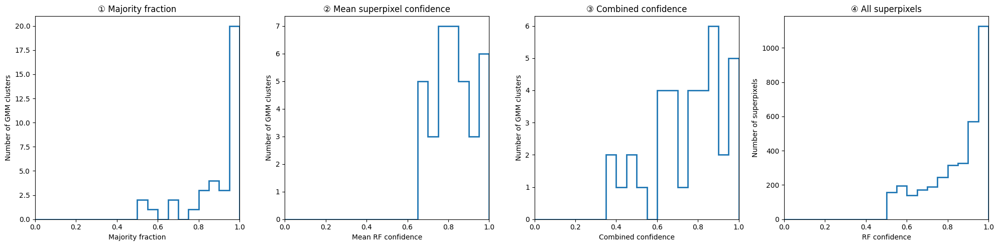

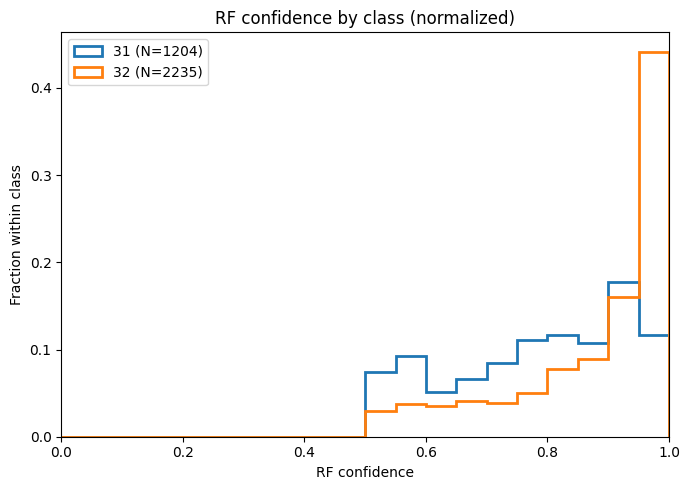

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold

csv_path = "/home/kmanabe2403/document/dune/superpixel/validation3/training3_low/stage1_GMM/data3/GMM_RF1_training.csv"

feature_names = [
    "Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b",
    "Brightness range", "LBP", "Coherence std", "Coherence p90",
    "GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation",
    "Edge dominant angle", "Edge angle entropy"
]

label_map = {
    11:0, 12:1, 13:2, 14:0, 15:0, 16:0, 17:1, 18:0, 19:0,
    21:1, 22:3, 23:1, 24:1, 25:1, 26:1, 27:1,
    31:2, 32:2, 33:2, 34:2, 35:2, 36:3, 37:2, 38:2, 39:2,
    41:3, 42:3, 43:3, 44:3, 45:3, 46:3, 47:3
}
name_map = {0:"1", 1:"2", 2:"3", 3:"4"}

label_map = {
    11:11, 12:11, 13:13, 14:14, 15:15, 16:16, 17:17, 18:18, 19:19, 
    21:21, 22:42, 23:17, 24:24, 25:25, 26:26, 27:27,
    31:31, 32:32, 33:33, 34:34, 35:35, 36:42, 37:37, 38:38, 39:39,
    41:41, 42:42, 43:42, 44:44, 45:45, 46:46, 47:47
}
name_map = {
    11:"11", 12:"12", 13:"13", 14:"14", 15:"15", 16:"16", 17:"17", 18:"18", 19:"19", 
    21:"21", 22:"22", 23:"23", 24:"24", 25:"25", 26:"26", 27:"27",
    31:"31", 32:"32", 33:"33", 34:"34", 35:"35", 36:"36", 37:"37", 38:"38", 39:"39",
    41:"41", 42:"42", 43:"43", 44:"44", 45:"45", 46:"46", 47:"47"
}

label_map = {
    # 11:11, 12:12, 13:13, 14:14, 
    # 21:21, 22:22, 23:23,
    # 31:31, 32:32, 33:33,
    31:31, 32:32, # 43:43, 44:41,
    # 51:51
}

name_map = {
    # 11:"11", 12:"12", 13:"13", 14:"14",
    # 21:"21", 22:"22", 23:"23",
    # 31:"31", 32:"32", 33:"33",
    31:"31", 32:"32", # 43:"43", # 44:"44",
    # 51:"5"
}

df = pd.read_csv(csv_path)
df = df.dropna(subset=feature_names+["manual_label"]).reset_index(drop=True)
df = df[df["manual_label"].isin(label_map)].copy()
df["rf_label"] = df["manual_label"].map(label_map).astype(int)

print("Number of superpixels:",len(df))
print("\nOriginal manual labels:")
print(df["manual_label"].value_counts().sort_index())

print("\nRF classes:")
print(df["rf_label"].value_counts().sort_index())

print("\nClass summary:")
for c in sorted(name_map):
    n = (df["rf_label"] == c).sum()
    manual_labels = sorted(df.loc[df["rf_label"] == c,"manual_label"].unique())
    print(f"{name_map[c]}: N={n}, manual labels={manual_labels}")

X = df[feature_names].values
y = df["rf_label"].values

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=0)
rf_pred = np.zeros(len(df),dtype=int)
rf_confidence = np.zeros(len(df))

for fold,(train_idx,test_idx) in enumerate(cv.split(X,y),1):
    rf = RandomForestClassifier(
        n_estimators=200,
        random_state=0,
        class_weight="balanced",
        n_jobs=-1
    )
    rf.fit(X[train_idx],y[train_idx])
    prob = rf.predict_proba(X[test_idx])
    rf_pred[test_idx] = rf.classes_[np.argmax(prob,axis=1)]
    rf_confidence[test_idx] = np.max(prob,axis=1)
    print(f"Fold {fold}/5 finished")

df["rf_pred"] = rf_pred
df["rf_confidence"] = rf_confidence

print("\nRF prediction classes:")
print(df["rf_pred"].value_counts().sort_index())

print("\nRF confidence by class:")
for c in sorted(name_map):
    sub = df[df["rf_label"] == c]
    if len(sub) == 0:
        print(f"{name_map[c]}: N=0")
        continue
    print(
        f"{name_map[c]}: N={len(sub)}, "
        f"mean={sub['rf_confidence'].mean():.3f}, "
        f"median={sub['rf_confidence'].median():.3f}"
    )

cluster_results = []

for (image_id,stage1_cluster,stage2_cluster),group in df.groupby(
    ["image_id","stage1_cluster","stage2_cluster"]
):
    n = len(group)
    true_label = group["manual_label"].value_counts().index[0]
    true_class = label_map[true_label]
    pred_counts = group["rf_pred"].value_counts()
    pred_class = pred_counts.index[0]
    majority_fraction = pred_counts.iloc[0]/n
    mean_rf_confidence = group["rf_confidence"].mean()
    combined_confidence = majority_fraction*mean_rf_confidence

    cluster_results.append({
        "image_id":image_id,
        "stage1_cluster":stage1_cluster,
        "stage2_cluster":stage2_cluster,
        "subgroup":true_label,
        "true_class":true_class,
        "pred_class":pred_class,
        "N":n,
        "majority_fraction":majority_fraction,
        "mean_rf_confidence":mean_rf_confidence,
        "combined_confidence":combined_confidence,
        "correct":int(true_class == pred_class)
    })

cluster_df = pd.DataFrame(cluster_results)

print(f"\nNumber of GMM clusters: {len(cluster_df)}")
print(f"Cluster accuracy: {cluster_df['correct'].mean():.3f}")
print(f"Mean majority fraction: {cluster_df['majority_fraction'].mean():.3f}")
print(f"Mean RF confidence: {cluster_df['mean_rf_confidence'].mean():.3f}")
print(f"Mean combined confidence: {cluster_df['combined_confidence'].mean():.3f}")

print("\nAccuracy / confidence by class")
for c in sorted(name_map):
    sub = cluster_df[cluster_df["true_class"] == c]
    if len(sub) == 0:
        print(f"{name_map[c]}: N=0 clusters")
        continue
    print(
        f"{name_map[c]}: "
        f"N={len(sub)}, "
        f"accuracy={sub['correct'].mean():.3f}, "
        f"majority={sub['majority_fraction'].mean():.3f}, "
        f"RF confidence={sub['mean_rf_confidence'].mean():.3f}, "
        f"combined={sub['combined_confidence'].mean():.3f}"
    )

bins = np.linspace(0,1,21)

fig,axes = plt.subplots(1,4,figsize=(20,5))

axes[0].hist(cluster_df["majority_fraction"],bins=bins,histtype="step",linewidth=2)
axes[0].set_xlabel("Majority fraction")
axes[0].set_ylabel("Number of GMM clusters")
axes[0].set_title("① Majority fraction")
axes[0].set_xlim(0,1)

axes[1].hist(cluster_df["mean_rf_confidence"],bins=bins,histtype="step",linewidth=2)
axes[1].set_xlabel("Mean RF confidence")
axes[1].set_ylabel("Number of GMM clusters")
axes[1].set_title("② Mean superpixel confidence")
axes[1].set_xlim(0,1)

axes[2].hist(cluster_df["combined_confidence"],bins=bins,histtype="step",linewidth=2)
axes[2].set_xlabel("Combined confidence")
axes[2].set_ylabel("Number of GMM clusters")
axes[2].set_title("③ Combined confidence")
axes[2].set_xlim(0,1)

axes[3].hist(df["rf_confidence"],bins=bins,histtype="step",linewidth=2)
axes[3].set_xlabel("RF confidence")
axes[3].set_ylabel("Number of superpixels")
axes[3].set_title("④ All superpixels")
axes[3].set_xlim(0,1)

plt.tight_layout()
plt.show()

fig,ax = plt.subplots(figsize=(7,5))

for c in sorted(name_map):
    values = df.loc[df["rf_label"] == c,"rf_confidence"].values
    if len(values) == 0:
        continue
    weights = np.ones(len(values))/len(values)
    ax.hist(
        values,
        bins=bins,
        weights=weights,
        histtype="step",
        linewidth=2,
        label=f"{name_map[c]} (N={len(values)})"
    )

ax.set_xlabel("RF confidence")
ax.set_ylabel("Fraction within class")
ax.set_title("RF confidence by class (normalized)")
ax.set_xlim(0,1)
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# import os
# import gc
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from matplotlib.backends.backend_pdf import PdfPages
# from sklearn.preprocessing import StandardScaler
# from sklearn.decomposition import PCA
# from sklearn.mixture import GaussianMixture

# csv_path = "/home/kmanabe2403/document/dune/superpixel/validation3/training3_low/stage1_GMM/data3/GMM_RF1_training.csv"
# data_path = path_for_data
# target_classes = [1,2,3,4]
# gmm_groups_list = [3,4,5,6]
# pca_components = 15
# random_state = 0
# n_random_images = 30
# min_superpixels_per_image = 10
# images_per_page = 6
# max_image_pages_per_gmm_class = 5
# max_display_size = 700

# feature_names = ["Variance","Gradient","Entropy","Edge density","Coherence","L","a","b","Brightness range","LBP","Coherence std","Coherence p90","GLCM contrast","GLCM homogeneity","GLCM energy","GLCM correlation","Edge dominant angle","Edge angle entropy"]

# label_map = {11:1,12:1,13:1,14:1,21:2,22:2,23:2,31:3,32:3,33:3,41:4,42:4,43:4,51:5}

# df = pd.read_csv(csv_path)
# df = df.dropna(subset=feature_names+["manual_label"]).reset_index(drop=True)
# df = df[df["manual_label"].isin(label_map)].copy()
# df["class"] = df["manual_label"].map(label_map).astype(int)

# print("Total superpixels:",len(df))
# print("Class counts:")
# print(df["class"].value_counts().sort_index())

# save_dir = os.path.join(data_path,"superpixel_data")
# images_dir = os.path.join(save_dir,"images")
# segments_dir = os.path.join(save_dir,"segments")
# all_image_ids = np.load(os.path.join(data_path,"RF_features","all_image_ids.npy"))

# image_global_indices = {}
# for image_id in np.unique(all_image_ids):
#     image_global_indices[int(image_id)] = np.where(all_image_ids == image_id)[0]

# def run_gmm(target_df,n_gmm):
#     print(f"\nRunning GMM={n_gmm}")
#     X = target_df[feature_names].to_numpy(dtype=np.float32)
#     scaler = StandardScaler()
#     X = scaler.fit_transform(X)
#     n_pca = min(pca_components,X.shape[0],X.shape[1])
#     pca = PCA(n_components=n_pca,random_state=random_state)
#     X_pca = pca.fit_transform(X)
#     explained = pca.explained_variance_ratio_.sum()
#     print(f"PCA explained variance = {explained:.4f}")
#     gmm = GaussianMixture(n_components=n_gmm,covariance_type="full",random_state=random_state,n_init=5)
#     gmm.fit(X_pca)
#     probabilities = gmm.predict_proba(X_pca)
#     labels = np.argmax(probabilities,axis=1)
#     confidence = probabilities[np.arange(len(labels)),labels]
#     result = target_df[["image_id","superpixel_index","manual_label"]].copy()
#     result["gmm_class"] = labels
#     result["gmm_confidence"] = confidence
#     for k in range(n_gmm):
#         mask = labels == k
#         n = int(mask.sum())
#         mean_conf = confidence[mask].mean() if n > 0 else 0
#         print(f"  GMM class {k}: N={n}, mean confidence={mean_conf:.4f}")
#     del X,X_pca,scaler,pca,gmm,probabilities,labels,confidence
#     gc.collect()
#     return result,explained

# def plot_confidence_page(pdf,result,n_gmm,target_class):
#     bins = np.linspace(0,1,31)
#     fig,axes = plt.subplots(1,2,figsize=(14,5))
#     axes[0].hist(result["gmm_confidence"].to_numpy(),bins=bins,histtype="step",linewidth=2)
#     axes[0].set_xlabel("GMM confidence")
#     axes[0].set_ylabel("Number of superpixels")
#     axes[0].set_title(f"Class {target_class} / GMM {n_gmm}: all")
#     axes[0].set_xlim(0,1)
#     for k in range(n_gmm):
#         values = result.loc[result["gmm_class"] == k,"gmm_confidence"].to_numpy()
#         if len(values) == 0:
#             continue
#         axes[1].hist(values,bins=bins,weights=np.ones(len(values))/len(values),histtype="step",linewidth=2,label=f"Class {k} (N={len(values)})")
#         del values
#     axes[1].set_xlabel("GMM confidence")
#     axes[1].set_ylabel("Fraction within GMM class")
#     axes[1].set_title(f"Class {target_class} / GMM {n_gmm}: normalized")
#     axes[1].set_xlim(0,1)
#     axes[1].legend()
#     plt.tight_layout()
#     pdf.savefig(fig,dpi=100)
#     plt.close(fig)
#     del fig,axes
#     gc.collect()

# def load_gmm_image(image_id,result,gmm_class):
#     image_path = os.path.join(images_dir,f"image_{int(image_id):03d}.npy")
#     segment_path = os.path.join(segments_dir,f"segments_{int(image_id):03d}.npy")
#     if not os.path.exists(image_path) or not os.path.exists(segment_path):
#         return None
#     image = np.load(image_path,mmap_mode="r")
#     segments = np.load(segment_path,mmap_mode="r")
#     image_df = result[result["image_id"] == image_id]
#     sp_indices = image_df["superpixel_index"].astype(int).to_numpy()
#     gmm_classes = image_df["gmm_class"].astype(int).to_numpy()
#     selected_sp = sp_indices[gmm_classes == gmm_class]
#     if len(selected_sp) < min_superpixels_per_image:
#         del image,segments,image_df,sp_indices,gmm_classes,selected_sp
#         gc.collect()
#         return None
#     global_indices = image_global_indices.get(int(image_id),np.array([],dtype=int))
#     if len(global_indices) == 0:
#         del image,segments,image_df,sp_indices,gmm_classes,selected_sp,global_indices
#         gc.collect()
#         return None
#     global_to_local = {int(g):i+1 for i,g in enumerate(global_indices)}
#     selected_local = [global_to_local[int(sp)] for sp in selected_sp if int(sp) in global_to_local]
#     del global_to_local,global_indices,image_df,sp_indices,gmm_classes,selected_sp
#     if len(selected_local) < min_superpixels_per_image:
#         del image,segments,selected_local
#         gc.collect()
#         return None
#     scale = max(1,int(max(image.shape[:2])/max_display_size))
#     image_small = np.asarray(image[::scale,::scale])
#     segments_small = np.asarray(segments[::scale,::scale])
#     del image,segments
#     if image_small.dtype.kind == "f":
#         if image_small.max() <= 1:
#             image_small = np.clip(image_small*255,0,255).astype(np.uint8)
#         else:
#             image_small = np.clip(image_small,0,255).astype(np.uint8)
#     else:
#         image_small = np.clip(image_small,0,255).astype(np.uint8)
#     if image_small.ndim == 2:
#         display_image = np.stack([image_small]*3,axis=-1)
#     else:
#         display_image = image_small[:,:,:3].copy()
#     del image_small
#     mask_small = np.isin(segments_small,np.asarray(selected_local,dtype=np.int32))
#     del segments_small,selected_local
#     display_image[~mask_small] = 255
#     del mask_small
#     gc.collect()
#     return display_image

# def plot_gmm_class_images(pdf,result,n_gmm,target_class,gmm_class):
#     image_counts = result[result["gmm_class"] == gmm_class].groupby("image_id").size()
#     valid_images = image_counts[image_counts >= min_superpixels_per_image].index.to_numpy()
#     del image_counts
#     if len(valid_images) == 0:
#         print(f"  GMM class {gmm_class}: no valid images")
#         del valid_images
#         gc.collect()
#         return
#     rng = np.random.default_rng(random_state + target_class*100 + n_gmm*10 + gmm_class)
#     selected_images = rng.choice(valid_images,size=min(n_random_images,len(valid_images)),replace=False)
#     del valid_images
#     max_images = images_per_page*max_image_pages_per_gmm_class
#     selected_images = selected_images[:max_images]
#     print(f"  GMM class {gmm_class}: {len(selected_images)} candidate images")
#     for page_start in range(0,len(selected_images),images_per_page):
#         page_images = selected_images[page_start:page_start+images_per_page]
#         loaded_images = []
#         for image_id in page_images:
#             display_image = load_gmm_image(int(image_id),result,gmm_class)
#             if display_image is not None:
#                 loaded_images.append((int(image_id),display_image))
#             gc.collect()
#         if len(loaded_images) == 0:
#             del page_images,loaded_images
#             gc.collect()
#             continue
#         fig,axes = plt.subplots(2,3,figsize=(12,8))
#         axes = axes.ravel()
#         for ax,(image_id,display_image) in zip(axes,loaded_images):
#             ax.imshow(display_image,interpolation="nearest")
#             n = int(((result["image_id"] == image_id) & (result["gmm_class"] == gmm_class)).sum())
#             ax.set_title(f"Image {image_id} / N={n}",fontsize=9)
#             ax.axis("off")
#             del display_image
#         for ax in axes[len(loaded_images):]:
#             ax.axis("off")
#         plt.tight_layout()
#         pdf.savefig(fig,dpi=100)
#         plt.close(fig)
#         del fig,axes,loaded_images,page_images
#         gc.collect()
#     del selected_images
#     gc.collect()

# for target_class in target_classes:
#     target_df = df[df["class"] == target_class][["image_id","superpixel_index","manual_label"]+feature_names].copy()
#     print(f"\nTarget class {target_class}: N={len(target_df)}")
#     print(target_df["manual_label"].value_counts().sort_index())
#     for n_gmm in gmm_groups_list:
#         output_pdf = os.path.join(data_path,f"class_GMM_analysis_class{target_class}_gmm{n_gmm}.pdf")
#         print(f"\nProcessing Class {target_class}, GMM={n_gmm}")
#         result,explained = run_gmm(target_df,n_gmm)
#         with PdfPages(output_pdf) as pdf:
#             plot_confidence_page(pdf,result,n_gmm,target_class)
#             for gmm_class in range(n_gmm):
#                 plot_gmm_class_images(pdf,result,n_gmm,target_class,gmm_class)
#                 gc.collect()
#         print(f"PDF saved: {output_pdf}")
#         del result
#         plt.close("all")
#         gc.collect()
#     del target_df
#     gc.collect()

# del df,all_image_ids,image_global_indices
# gc.collect()
# plt.close("all")
# print("\nFinished")

Total superpixels: 37518
Class counts:
class
1     5174
2     6225
3     7651
4    18444
5       24
Name: count, dtype: int64

Target class 1: N=5174
manual_label
11    4842
12     147
14     185
Name: count, dtype: int64

Processing Class 1, GMM=3

Running GMM=3
PCA explained variance = 0.9988
  GMM class 0: N=2889, mean confidence=0.9697
  GMM class 1: N=1054, mean confidence=0.9710
  GMM class 2: N=1231, mean confidence=0.9427
  GMM class 0: 30 candidate images
  GMM class 1: 9 candidate images
  GMM class 2: 28 candidate images
PDF saved: validation3/training3_low/stage1_GMM/data3/class_GMM_analysis_class1_gmm3.pdf

Processing Class 1, GMM=4

Running GMM=4
PCA explained variance = 0.9988
  GMM class 0: N=1098, mean confidence=0.9508
  GMM class 1: N=1344, mean confidence=0.9413
  GMM class 2: N=2163, mean confidence=0.9531
  GMM class 3: N=569, mean confidence=0.9691
  GMM class 0: 26 candidate images
  GMM class 1: 21 candidate images
  GMM class 2: 25 candidate images
  GMM class

KeyboardInterrupt: 

In [ ]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

csv_path = "/home/kmanabe2403/document/dune/superpixel/validation3/training3_low/stage1_GMM/data3/GMM_RF1_training.csv"
data_path = path_for_data
output_dir = os.path.join(data_path,"cluster_GMM")
os.makedirs(output_dir,exist_ok=True)

target_classes = [1,2,3,4]
gmm_groups_list = [3,4,5,6]
group_columns = ["image_id","stage1_cluster","stage2_cluster"]

pca_components = 3
random_state = 0
min_superpixels_per_cluster = 10
n_random_images = 30
images_per_page = 6

feature_names = ["Variance","Gradient","Entropy","Edge density","Coherence","L","a","b","Brightness range","LBP","Coherence std","Coherence p90","GLCM contrast","GLCM homogeneity","GLCM energy","GLCM correlation","Edge dominant angle","Edge angle entropy"]

label_map = {
    11:1,12:1,13:1,14:1,
    21:2,22:2,23:2,
    31:3,32:3,33:3,
    41:4,42:4,43:4,
    51:5
}

df = pd.read_csv(csv_path)
df = df.dropna(subset=feature_names+["manual_label"]+group_columns).copy()
df = df[df["manual_label"].isin(label_map)].copy()
df["class"] = df["manual_label"].map(label_map).astype(int)

print("Total superpixels:",len(df))
print("Class counts:")
print(df["class"].value_counts().sort_index())

save_dir = os.path.join(data_path,"superpixel_data")
images_dir = os.path.join(save_dir,"images")
segments_dir = os.path.join(save_dir,"segments")

all_image_ids = np.load(os.path.join(data_path,"RF_features","all_image_ids.npy"))

image_global_indices = {}
for image_id in np.unique(all_image_ids):
    image_global_indices[int(image_id)] = np.where(all_image_ids == image_id)[0]

def make_cluster_features(target_df):
    group_size = target_df.groupby(group_columns).size().reset_index(name="N")
    valid_groups = group_size[group_size["N"] >= min_superpixels_per_cluster][group_columns]

    target_df = target_df.merge(valid_groups,on=group_columns,how="inner")

    mean_df = target_df.groupby(group_columns)[feature_names].mean()
    std_df = target_df.groupby(group_columns)[feature_names].std().fillna(0)

    mean_df.columns = [f"{x}_mean" for x in mean_df.columns]
    std_df.columns = [f"{x}_std" for x in std_df.columns]

    cluster_features = pd.concat([mean_df,std_df],axis=1).reset_index()
    cluster_features = cluster_features.merge(group_size,on=group_columns)

    return target_df,cluster_features

def run_cluster_gmm(target_df,n_gmm):
    target_df,cluster_features = make_cluster_features(target_df)

    print(f"Valid clusters: {len(cluster_features)}")
    print(f"Superpixels in valid clusters: {len(target_df)}")

    feature_columns = [x for x in cluster_features.columns if x not in group_columns+["N"]]

    X = cluster_features[feature_columns].to_numpy(dtype=np.float64)

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    n_pca = min(pca_components,X_scaled.shape[0],X_scaled.shape[1])

    pca = PCA(n_components=n_pca,random_state=random_state)
    X_pca = pca.fit_transform(X_scaled)

    explained = pca.explained_variance_ratio_.sum()
    print(f"PCA explained variance: {explained:.4f}")

    gmm = GaussianMixture(n_components=n_gmm,covariance_type="full",random_state=random_state,n_init=10)
    gmm.fit(X_pca)

    probabilities = gmm.predict_proba(X_pca)
    labels = np.argmax(probabilities,axis=1)
    confidence = np.max(probabilities,axis=1)

    cluster_features["gmm_class"] = labels
    cluster_features["gmm_confidence"] = confidence

    print("\nGMM result:")
    for k in range(n_gmm):
        mask = labels == k
        if mask.sum() == 0:
            print(f"Class {k}: N=0")
            continue
        print(f"Class {k}: clusters={mask.sum()}, superpixels={cluster_features.loc[mask,'N'].sum()}, mean confidence={confidence[mask].mean():.4f}")

    del X,X_scaled,X_pca,probabilities,labels,confidence,gmm,pca,scaler
    del feature_columns
    gc.collect()

    return target_df,cluster_features,explained

def plot_confidence_page(pdf,cluster_features,n_gmm,target_class):
    bins = np.linspace(0,1,31)

    fig,axes = plt.subplots(1,2,figsize=(14,5))

    axes[0].hist(cluster_features["gmm_confidence"],bins=bins,histtype="step",linewidth=2)
    axes[0].set_xlabel("GMM confidence")
    axes[0].set_ylabel("Number of original clusters")
    axes[0].set_title(f"Class {target_class} / GMM {n_gmm}: all clusters")
    axes[0].set_xlim(0,1)

    for k in range(n_gmm):
        values = cluster_features.loc[cluster_features["gmm_class"] == k,"gmm_confidence"].to_numpy()
        if len(values) == 0:
            continue
        weights = np.ones(len(values))/len(values)
        axes[1].hist(values,bins=bins,weights=weights,histtype="step",linewidth=2,label=f"GMM {k} (N={len(values)})")

    axes[1].set_xlabel("GMM confidence")
    axes[1].set_ylabel("Fraction within GMM class")
    axes[1].set_title(f"Class {target_class} / GMM {n_gmm}: normalized")
    axes[1].set_xlim(0,1)
    axes[1].legend()

    plt.tight_layout()
    pdf.savefig(fig,dpi=120)
    plt.close(fig)
    del fig,axes
    gc.collect()

def plot_image_pages(pdf,target_df,cluster_features,n_gmm,target_class,target_gmm_class):
    target_clusters = cluster_features[cluster_features["gmm_class"] == target_gmm_class].copy()

    if len(target_clusters) == 0:
        print(f"No clusters for GMM class {target_gmm_class}")
        del target_clusters
        gc.collect()
        return

    target_cluster_keys = target_clusters[group_columns]

    target_sp = target_df.merge(target_cluster_keys,on=group_columns,how="inner")

    image_counts = target_sp.groupby("image_id").size()
    valid_images = image_counts[image_counts >= min_superpixels_per_cluster].index.to_numpy()

    if len(valid_images) == 0:
        print(f"No images for GMM class {target_gmm_class}")
        del target_clusters,target_sp,image_counts,valid_images
        gc.collect()
        return

    rng = np.random.default_rng(random_state + target_class*100 + target_gmm_class)
    selected_images = rng.choice(valid_images,size=min(n_random_images,len(valid_images)),replace=False)

    print(f"GMM class {target_gmm_class}: images available={len(valid_images)}, selected={len(selected_images)}")

    for page_start in range(0,len(selected_images),images_per_page):
        page_images = selected_images[page_start:page_start+images_per_page]
        fig,axes = plt.subplots(2,3,figsize=(15,9))
        axes = axes.ravel()
        plotted = 0

        for image_id in page_images:
            image_id = int(image_id)

            image_path = os.path.join(images_dir,f"image_{image_id:03d}.npy")
            segment_path = os.path.join(segments_dir,f"segments_{image_id:03d}.npy")

            if not os.path.exists(image_path) or not os.path.exists(segment_path):
                continue

            image_df = target_sp[target_sp["image_id"] == image_id]

            if len(image_df) < min_superpixels_per_cluster:
                del image_df
                continue

            ax = axes[plotted]

            image = np.load(image_path)
            segments = np.load(segment_path)

            global_indices = image_global_indices.get(image_id)

            if global_indices is None:
                del image,segments,image_df
                continue

            global_to_local = {int(g):i+1 for i,g in enumerate(global_indices)}

            keep_segments = []

            for _,row in image_df.iterrows():
                sp = int(row["superpixel_index"])
                if sp in global_to_local:
                    keep_segments.append(global_to_local[sp])

            keep_segments = np.asarray(keep_segments,dtype=np.int32)

            if image.dtype.kind == "f":
                image_max = image.max()
                if image_max <= 1:
                    image_disp = np.clip(image*255,0,255).astype(np.uint8)
                else:
                    image_disp = np.clip(image,0,255).astype(np.uint8)
            else:
                image_disp = np.clip(image,0,255).astype(np.uint8)

            if image_disp.ndim == 2:
                display_image = np.stack([image_disp]*3,axis=-1)
            else:
                display_image = image_disp[:,:,:3]

            keep_mask = np.isin(segments,keep_segments)

            white_image = np.full_like(display_image,255)
            result_image = np.where(keep_mask[...,None],display_image,white_image)

            ax.imshow(result_image)

            cluster_info = target_clusters[target_clusters["image_id"] == image_id]

            cluster_text = []
            for _,row in cluster_info.iterrows():
                cluster_text.append(f"{int(row['stage1_cluster'])}/{int(row['stage2_cluster'])}: N={int(row['N'])}, conf={row['gmm_confidence']:.2f}")

            ax.set_title(f"Image {image_id}\nGMM {target_gmm_class} | SP={len(image_df)}",fontsize=9)

            if len(cluster_text) > 0:
                ax.text(0.01,0.01,"\n".join(cluster_text[:4]),transform=ax.transAxes,fontsize=7,verticalalignment="bottom",bbox=dict(facecolor="white",alpha=0.8))

            ax.axis("off")

            plotted += 1

            del image,segments,image_df,global_indices,global_to_local
            del keep_segments,image_disp,display_image,keep_mask,white_image,cluster_info,cluster_text
            gc.collect()

            if plotted >= images_per_page:
                break

        for ax in axes[plotted:]:
            ax.axis("off")

        if plotted > 0:
            plt.tight_layout()
            pdf.savefig(fig,dpi=120)

        plt.close(fig)
        del fig,axes,page_images
        gc.collect()

    del target_clusters,target_sp,image_counts,valid_images,selected_images
    gc.collect()

for target_class in target_classes:
    print(f"\nTarget class {target_class}")

    target_df_original = df[df["class"] == target_class].copy()

    print(f"Superpixels: {len(target_df_original)}")
    print(target_df_original["manual_label"].value_counts().sort_index())

    for n_gmm in gmm_groups_list:
        print(f"\nProcessing Class {target_class}, GMM={n_gmm}")

        target_df,cluster_features,explained = run_cluster_gmm(target_df_original,n_gmm)

        for target_gmm_class in range(n_gmm):
            output_pdf = os.path.join(output_dir,f"class{target_class}_gmm{n_gmm}_class{target_gmm_class}.pdf")

            print(f"Creating PDF: {output_pdf}")

            with PdfPages(output_pdf) as pdf:
                plot_confidence_page(pdf,cluster_features,n_gmm,target_class)
                plot_image_pages(pdf,target_df,cluster_features,n_gmm,target_class,target_gmm_class)

            print(f"PDF saved: {output_pdf}")

            plt.close("all")
            gc.collect()

        del target_df,cluster_features
        gc.collect()

    del target_df_original
    gc.collect()

del df,all_image_ids,image_global_indices
gc.collect()

plt.close("all")
gc.collect()

print("\nFinished")

Total superpixels: 37518
Class counts:
class
1     5174
2     6225
3     7651
4    18444
5       24
Name: count, dtype: int64

Target class 1
Superpixels: 5174
manual_label
11    4842
12     147
14     185
Name: count, dtype: int64

Processing Class 1, GMM=3
Valid clusters: 60
Superpixels in valid clusters: 5163
PCA explained variance: 0.6731

GMM result:
Class 0: clusters=26, superpixels=2175, mean confidence=0.8836
Class 1: clusters=32, superpixels=2946, mean confidence=0.8257
Class 2: clusters=2, superpixels=42, mean confidence=1.0000
Creating PDF: validation3/training3_low/stage1_GMM/data3/cluster_GMM/class1_gmm3_class0.pdf
GMM class 0: images available=19, selected=19
PDF saved: validation3/training3_low/stage1_GMM/data3/cluster_GMM/class1_gmm3_class0.pdf
Creating PDF: validation3/training3_low/stage1_GMM/data3/cluster_GMM/class1_gmm3_class1.pdf
GMM class 1: images available=24, selected=24
PDF saved: validation3/training3_low/stage1_GMM/data3/cluster_GMM/class1_gmm3_class1.pdf
Cr

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7f92bc6b1fc0>>
Traceback (most recent call last):
  File "/home/kmanabe2403/.local/lib/python3.10/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


GMM class 0: images available=12, selected=12
PDF saved: validation3/training3_low/stage1_GMM/data3/cluster_GMM/class3_gmm3_class0.pdf
Creating PDF: validation3/training3_low/stage1_GMM/data3/cluster_GMM/class3_gmm3_class1.pdf
GMM class 1: images available=20, selected=20
PDF saved: validation3/training3_low/stage1_GMM/data3/cluster_GMM/class3_gmm3_class1.pdf
Creating PDF: validation3/training3_low/stage1_GMM/data3/cluster_GMM/class3_gmm3_class2.pdf
GMM class 2: images available=15, selected=15
PDF saved: validation3/training3_low/stage1_GMM/data3/cluster_GMM/class3_gmm3_class2.pdf

Processing Class 3, GMM=4
Valid clusters: 61
Superpixels in valid clusters: 7651
PCA explained variance: 0.6845

GMM result:
Class 0: clusters=18, superpixels=2818, mean confidence=0.9865
Class 1: clusters=24, superpixels=3152, mean confidence=0.9938
Class 2: clusters=5, superpixels=171, mean confidence=0.9755
Class 3: clusters=14, superpixels=1510, mean confidence=0.9994
Creating PDF: validation3/training3

: 

In [ ]:
print("\nClass 3 subgroup confusion")

class3_labels = [21,22,23]

for label in class3_labels:
    sub = df[df["manual_label"] == label].copy()
    if len(sub) == 0:
        print(f"\nmanual label {label}: N=0")
        continue

    true_class = label_map[label]
    pred_counts = sub["rf_pred"].value_counts().sort_index()
    correct = (sub["rf_pred"] == true_class).sum()

    print(f"\nmanual label {label}: N={len(sub)}")
    print(f"  Correct ({name_map[true_class]}): {correct}/{len(sub)} ({correct/len(sub):.3f})")

    print("  Predictions:")
    for pred_class,count in pred_counts.items():
        print(f"    {name_map.get(pred_class,str(pred_class))}: {count} ({count/len(sub):.3f})")


Class 3 subgroup confusion

manual label 21: N=360
  Correct (2): 339/360 (0.942)
  Predictions:
    1: 15 (0.042)
    2: 339 (0.942)
    3: 5 (0.014)
    4: 1 (0.003)

manual label 22: N=324
  Correct (2): 215/324 (0.664)
  Predictions:
    1: 26 (0.080)
    2: 215 (0.664)
    3: 83 (0.256)

manual label 23: N=1157
  Correct (2): 920/1157 (0.795)
  Predictions:
    1: 2 (0.002)
    2: 920 (0.795)
    3: 89 (0.077)
    4: 146 (0.126)


In [ ]:
for subgroup in sorted(cluster_df["subgroup"].dropna().unique()):
    sub = cluster_df[cluster_df["subgroup"] == subgroup]
    mis = sub[sub["correct"] == 0]

    if len(mis) == 0:
        continue

    subgroup = int(subgroup)
    true_class = int(sub["true_class"].iloc[0])

    print(
        f"\nSubgroup {subgroup} (Class {true_class + 1}): "
        f"N={len(sub)}, "
        f"accuracy={sub['correct'].mean():.3f}, "
        f"majority={sub['majority_fraction'].mean():.3f}, "
        f"RF confidence={sub['mean_rf_confidence'].mean():.3f}, "
        f"combined={sub['combined_confidence'].mean():.3f}"
    )

    for _, row in mis.iterrows():
        image_id = int(row["image_id"]) + 1
        stage1 = int(row["stage1_cluster"])
        stage2 = int(row["stage2_cluster"])
        pred_class = int(row["pred_class"])

        print(
            f"  Image {image_id:03d}, "
            f"GMM cluster (stage1={stage1}, stage2={stage2}): "
            f"Manual = subgroup {subgroup} (Class {true_class + 1}) "
            f"→ RF majority = Class {pred_class + 1}"
        )

In [ ]:
print("\nSubgroup-level misclassification")

for subgroup in sorted(df["manual_label"].unique()):
    true_class = label_map[subgroup]


    sub = df[df["manual_label"] == subgroup]
    mis = sub[sub["rf_pred"] != true_class]

    if len(mis) == 0:
        continue

    print(
        f"\nSubgroup {subgroup} "
        f"(Class {true_class + 1}), "
        f"N={len(sub)}"
    )

    counts = mis["rf_pred"].value_counts()

    for pred_class, count in counts.items():
        print(
            f"  → Class {pred_class + 1}: "
            f"{count} superpixels "
            f"({count / len(sub):.3f})"
        )

In [ ]:
# 誤判定superpixel数の多いクラスターを調べる
cluster_mis = []

for (image_id, stage1_cluster, stage2_cluster), group in df.groupby(
    ["image_id", "stage1_cluster", "stage2_cluster"]
):
    true_label = group["manual_label"].value_counts().index[0]
    true_class = label_map[true_label]

    mis = group[group["rf_pred"] != true_class]

    if len(mis) > 0:
        pred_counts = group["rf_pred"].value_counts()
        pred_class = pred_counts.index[0]
        if image_id >= 74:
            image_num = image_id - 74 + 1
            type = "new"
        else:
            image_num = image_id + 1
            type = "old"

        cluster_mis.append({
            "image_id": image_id,
            "type": type,
            "image_num": image_num,
            "stage1_cluster": stage1_cluster,
            "stage2_cluster": stage2_cluster,
            "true_label": true_label,
            "true_class": true_class,
            "pred_class": pred_class,
            "N": len(group),
            "misclassified_N": len(mis),
            "misclassified_fraction": len(mis) / len(group)
        })

mis_df = pd.DataFrame(cluster_mis)

# 誤判定superpixel数が多い順
mis_df = mis_df.sort_values(
    "misclassified_fraction",
    ascending=False
)

print("\nClusters with many misclassified superpixels")

print(
    mis_df.head(60).to_string(index=False)
)

In [ ]:
X = df[feature_names].values
y = df["manual_label"].values

# すでに同じrf_labelにマージされている組み合わせは除外
subgroups = sorted(df["manual_label"].unique())
pairs = []
for i, a in enumerate(subgroups):
    for b in subgroups[i+1:]:
        rf_a = df.loc[df["manual_label"] == a, "rf_label"].iloc[0]
        rf_b = df.loc[df["manual_label"] == b, "rf_label"].iloc[0]
        if rf_a == rf_b: continue
        da, db = df[df.manual_label == a], df[df.manual_label == b]
        f_ab = (da.rf_pred == rf_b).mean()
        f_ba = (db.rf_pred == rf_a).mean()
        pairs.append([a, b, f_ab, f_ba, (f_ab + f_ba) / 2])

pairs = pd.DataFrame(pairs, columns=["A","B","A→B","B→A","mix"])
candidates = pairs.sort_values("mix", ascending=False).head(20)
print("Candidate pairs:")
print(candidates.to_string(index=False))

cv = StratifiedKFold(3, shuffle=True, random_state=0)
pred = np.zeros(len(y), dtype=int)
for train, test in cv.split(X, y):
    rf = RandomForestClassifier(n_estimators=50, class_weight="balanced", random_state=0, n_jobs=-1)
    rf.fit(X[train], y[train])
    pred[test] = rf.predict(X[test])
original_acc = np.mean(y == pred)
print(f"\nCurrent accuracy: {original_acc:.4f}")

results = []
for _, r in candidates.iterrows():
    a, b = int(r.A), int(r.B)
    rf_a = df.loc[df.manual_label == a, "rf_label"].iloc[0]
    rf_b = df.loc[df.manual_label == b, "rf_label"].iloc[0]
    ym = y.copy()
    ym[ym == rf_b] = rf_a
    pred = np.zeros(len(y), dtype=int)
    for train, test in cv.split(X, ym):
        rf = RandomForestClassifier(n_estimators=50, class_weight="balanced", random_state=0, n_jobs=-1)
        rf.fit(X[train], ym[train])
        pred[test] = rf.predict(X[test])
    acc = np.mean(ym == pred)
    results.append([a, b, acc, acc - original_acc])

results = pd.DataFrame(results, columns=["A","B","accuracy","improvement"])
print("\nMerge results:")
print(results.sort_values("improvement", ascending=False).to_string(index=False))

In [ ]:
X = df[feature_names].values

# マージ後のRFクラスを使用
subgroups = sorted(df["rf_label"].unique())

# clusterごとの正解クラス → RF予測クラス
cluster_pred = []
for (image_id, s1, s2), g in df.groupby(["image_id", "stage1_cluster", "stage2_cluster"]):
    true_label = g["rf_label"].value_counts().index[0]
    pred_label = g["rf_pred"].value_counts().index[0]
    cluster_pred.append([image_id, s1, s2, true_label, pred_label])

cluster_pred = pd.DataFrame(cluster_pred, columns=["image_id","stage1_cluster","stage2_cluster","true_label","pred_label"])

pairs = []
for i, a in enumerate(subgroups):
    for b in subgroups[i+1:]:
        da, db = df[df["rf_label"] == a], df[df["rf_label"] == b]
        ca, cb = cluster_pred[cluster_pred["true_label"] == a], cluster_pred[cluster_pred["true_label"] == b]

        sp_ab = (da["rf_pred"] == b).mean()
        sp_ba = (db["rf_pred"] == a).mean()
        cl_ab = (ca["pred_label"] == b).mean() if len(ca) else 0
        cl_ba = (cb["pred_label"] == a).mean() if len(cb) else 0

        pairs.append([a, b, sp_ab, sp_ba, (sp_ab+sp_ba)/2, cl_ab, cl_ba, (cl_ab+cl_ba)/2])

pairs = pd.DataFrame(pairs, columns=["A","B","SP_A→B","SP_B→A","SP_mix","CL_A→B","CL_B→A","CL_mix"])

print("Candidate pairs:")
print(pairs.sort_values("CL_mix", ascending=False).head(30).to_string(index=False))

In [ ]:
# clusterごとの誤判定率を計算
cluster_mis = []

for (image_id, s1, s2), g in df.groupby(["image_id", "stage1_cluster", "stage2_cluster"]):
    true_label = g["rf_label"].value_counts().index[0]
    pred_counts = g["rf_pred"].value_counts()
    pred_label = pred_counts.index[0]
    mis_rate = (g["rf_pred"] != true_label).mean()

    if pred_label != true_label:
        cluster_mis.append([image_id, s1, s2, true_label, pred_label, len(g), mis_rate])

cluster_mis = pd.DataFrame(cluster_mis, columns=["image_id","stage1_cluster","stage2_cluster","true_label","pred_label","N","misclassification_rate"])

cluster_mis["type"] = np.where(cluster_mis["image_id"] < 74, "old", "new")
cluster_mis["image_num"] = np.where(cluster_mis["image_id"] < 74, cluster_mis["image_id"] + 1, cluster_mis["image_id"] - 73)

# cluster内の誤判定率が高い順
cluster_mis = cluster_mis.sort_values(["true_label", "misclassification_rate"], ascending=[True, False])
print(cluster_mis[["image_id","type","image_num","stage1_cluster","stage2_cluster","true_label","pred_label","N","misclassification_rate"]].to_string(index=False))

In [ ]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold

# ★ config
old_csv_path = "validation3/training3_low/stage1_GMM/data1/GMM_RF1_training_2.csv"
old_data_path = "validation3/training3_low/stage1_GMM/data1"
old_pdf_path = "validation3/training3_low/stage1_GMM/data2_all/old_cluster_misclassification.pdf"
new_csv_path = "validation3/training3_low/stage1_GMM/data21/GMM_RF1_training.csv"
new_data_path = "validation3/training3_low/stage1_GMM/data21"
new_pdf_path = "validation3/training3_low/stage1_GMM/data2_all/new_cluster_misclassification.pdf"
max_clusters = 100
n_estimators = 200
n_splits = 5
clusters_per_page = 4

feature_names = ["Variance","Gradient","Entropy","Edge density","Coherence","L","a","b","Brightness range","LBP","Coherence std","Coherence p90","GLCM contrast","GLCM homogeneity","GLCM energy","GLCM correlation","Edge dominant angle","Edge angle entropy"]
# label_map = {11:11,12:11,13:13,14:14,15:15,16:16,17:17,18:18,19:19,21:21,22:42,23:17,24:24,25:25,26:26,27:27,31:31,32:32,33:33,34:33,35:35,36:42,37:37,38:38,39:39,41:41,42:42,43:42,44:44,45:45,46:46,47:47}
label_map = {11:1, 12:1, 13:1, 14:1, 15:1, 16:1, 17:1, 18:1, 19:1, 21:2, 22:4, 23:1, 24:2, 25:2, 26:2, 27:4, 31:3, 32:3, 33:3, 34:3, 35:3, 36:4, 37:3, 38:4, 39:3, 41:4, 42:4, 43:4, 44:4, 45:4, 46:4, 47:4 }


def process_dataset(csv_path,data_path,pdf_path,dataset_name):
    print("\n"+"="*70); print(f"START: {dataset_name}"); print(f"CSV : {csv_path}"); print(f"DATA: {data_path}"); print("="*70)

    df = pd.read_csv(csv_path)
    print(f"[1] CSV rows: {len(df)}")
    print(f"[1] image_id range: {df['image_id'].min()} - {df['image_id'].max()}")
    print(f"[1] unique images: {df['image_id'].nunique()}")

    df = df.dropna(subset=feature_names+["manual_label"]).copy()
    df = df[df["manual_label"].isin(label_map)].copy()
    df["rf_label"] = df["manual_label"].map(label_map).astype(int)
    print(f"[2] Rows after filtering: {len(df)}")
    print(f"[2] manual labels: {sorted(df['manual_label'].unique())}")

    X = df[feature_names].values
    y = df["rf_label"].values
    cv = StratifiedKFold(n_splits=n_splits,shuffle=True,random_state=0)
    rf_pred = np.zeros(len(df),dtype=int)

    print(f"[3] Running RF {n_splits}-fold CV...")
    for fold,(train_idx,test_idx) in enumerate(cv.split(X,y),1):
        rf = RandomForestClassifier(n_estimators=n_estimators,random_state=0,class_weight="balanced",n_jobs=-1)
        rf.fit(X[train_idx],y[train_idx])
        rf_pred[test_idx] = rf.predict(X[test_idx])
        print(f"    fold {fold}/{n_splits} finished")

    df["rf_pred"] = rf_pred
    del X,y,rf_pred,rf,train_idx,test_idx
    gc.collect()

    # ★ clusterごとの誤判定率 + ミスラベル先上位2クラス
    cluster_mis = []

    for (image_id,s1,s2),g in df.groupby(["image_id","stage1_cluster","stage2_cluster"]):
        true_label = int(g["rf_label"].value_counts().index[0])
        pred_label = int(g["rf_pred"].value_counts().index[0])
        mis_rate = float((g["rf_pred"] != true_label).mean())

        # true_label以外への誤判定だけを集計
        mis = g.loc[g["rf_pred"] != true_label, "rf_pred"].value_counts()
        top2 = mis.head(2)

        if len(top2) >= 1:
            mis1_label = int(top2.index[0])
            mis1_count = int(top2.iloc[0])
            mis1_rate = mis1_count / len(g)
        else:
            mis1_label, mis1_count, mis1_rate = None, 0, 0.0

        if len(top2) >= 2:
            mis2_label = int(top2.index[1])
            mis2_count = int(top2.iloc[1])
            mis2_rate = mis2_count / len(g)
        else:
            mis2_label, mis2_count, mis2_rate = None, 0, 0.0

        cluster_mis.append([int(image_id),int(s1),int(s2),true_label,pred_label,len(g),mis_rate,mis1_label,mis1_count,mis1_rate,mis2_label,mis2_count,mis2_rate])

    cluster_mis = pd.DataFrame(cluster_mis,columns=["image_id","stage1_cluster","stage2_cluster","true_label","pred_label","N","misclassification_rate","mis1_label","mis1_count","mis1_rate","mis2_label","mis2_count","mis2_rate"])
    cluster_mis["type"] = np.where(cluster_mis["image_id"]<74,"old","new")
    cluster_mis["image_num"] = np.where(cluster_mis["image_id"]<74,cluster_mis["image_id"]+1,cluster_mis["image_id"]-73)
    cluster_mis = cluster_mis.sort_values("misclassification_rate",ascending=False).reset_index(drop=True)
    selected = cluster_mis if max_clusters is None else cluster_mis.head(max_clusters).copy()

    print(f"[4] Total clusters: {len(cluster_mis)}")
    print(f"[4] Clusters selected: {len(selected)}")

    save_dir = os.path.join(data_path,"superpixel_data")
    images_dir = os.path.join(save_dir,"images")
    segments_dir = os.path.join(save_dir,"segments")
    all_image_ids = np.load(os.path.join(data_path,"all_image_ids.npy"))

    print(f"[5] images_dir  : {images_dir}")
    print(f"[5] segments_dir: {segments_dir}")
    print(f"[5] all_image_ids: {all_image_ids.shape}")

    # global superpixel index → image内local segment番号
    image_global_indices = {}
    for image_id in np.unique(all_image_ids):
        image_global_indices[int(image_id)] = np.where(all_image_ids==image_id)[0]

    print(f"[5] Image/superpixel mappings: {len(image_global_indices)} images")

    txt_path = os.path.splitext(pdf_path)[0]+"_relabel.txt"
    os.makedirs(os.path.dirname(pdf_path),exist_ok=True)

    with PdfPages(pdf_path) as pdf, open(txt_path,"w") as f:
        f.write(f"# {dataset_name}\n")
        f.write("# image_id, image_num, type, stage1_cluster, stage2_cluster, true_label, pred_label, N, misclassification_rate, mis1_label, mis1_rate, mis2_label, mis2_rate\n")

        for _,r in selected.iterrows():
            f.write(f"# {int(r['image_id'])}, {int(r['image_num'])}, {r['type']}, {int(r['stage1_cluster'])}, {int(r['stage2_cluster'])}, {int(r['true_label'])}, {int(r['pred_label'])}, {int(r['N'])}, {r['misclassification_rate']:.3f}, {r['mis1_label']}, {r['mis1_rate']:.3f}, {r['mis2_label']}, {r['mis2_rate']:.3f}\n")

        for page_start in range(0,len(selected),clusters_per_page):
            page = selected.iloc[page_start:page_start+clusters_per_page]
            print(f"\n--- Page {page_start//clusters_per_page+1} ---")
            fig,axes = plt.subplots(2,2,figsize=(12,10)); axes = axes.ravel()

            for ax,(_,row) in zip(axes,page.iterrows()):
                image_id = int(row["image_id"]); s1 = int(row["stage1_cluster"]); s2 = int(row["stage2_cluster"])
                true_label = int(row["true_label"]); pred_label = int(row["pred_label"]); N = int(row["N"]); mis_rate = float(row["misclassification_rate"])

                print(f"  image_id={image_id}, image_num={int(row['image_num'])}, S1={s1}, S2={s2}, true={true_label}, pred={pred_label}, N={N}, mis={mis_rate:.3f}")

                image_path = os.path.join(images_dir,f"image_{image_id:03d}.npy")
                segment_path = os.path.join(segments_dir,f"segments_{image_id:03d}.npy")

                if not os.path.exists(image_path) or not os.path.exists(segment_path):
                    print(f"    [ERROR] missing: {image_path} / {segment_path}")
                    ax.text(.5,.5,"FILE MISSING",ha="center",va="center"); ax.axis("off")
                    continue

                image = np.load(image_path)
                segments = np.load(segment_path)
                global_indices = image_global_indices.get(image_id,np.array([],dtype=int))

                cluster_sp = df[(df["image_id"]==image_id)&(df["stage1_cluster"]==s1)&(df["stage2_cluster"]==s2)]["superpixel_index"].astype(int).unique()
                global_to_local = {int(g):i+1 for i,g in enumerate(global_indices)}
                local_segments = np.asarray([global_to_local[int(sp)] for sp in cluster_sp if int(sp) in global_to_local],dtype=int)

                mask = np.isin(segments,local_segments)
                selected_pixels = int(mask.sum())
                total_pixels = int(mask.size)
                fraction = selected_pixels/total_pixels if total_pixels else 0

                print(f"    [CHECK] CSV superpixels={len(cluster_sp)}, valid={len(local_segments)}, selected pixels={selected_pixels}/{total_pixels} ({fraction:.4%})")

                if image.dtype.kind == "f" and image.max() <= 1.0:
                    image_disp = np.clip(image*255,0,255).astype(np.uint8)
                else:
                    image_disp = np.clip(image,0,255).astype(np.uint8)

                if image_disp.ndim == 2:
                    display_image = np.full((*image_disp.shape,3),255,dtype=np.uint8)
                    display_image[mask] = np.stack([image_disp[mask]]*3,axis=-1)
                else:
                    display_image = np.full(image_disp[:,:,:3].shape,255,dtype=np.uint8)
                    display_image[mask] = image_disp[:,:,:3][mask]

                # ★ PDFタイトル用：ミスラベル先上位2クラス
                if pd.notna(row["mis1_label"]):
                    mis_text = f"→ {int(row['mis1_label'])}: {row['mis1_rate']:.1%} ({int(row['mis1_count'])}/{N})"
                    if pd.notna(row["mis2_label"]):
                        mis_text += f"\n→ {int(row['mis2_label'])}: {row['mis2_rate']:.1%} ({int(row['mis2_count'])}/{N})"
                else:
                    mis_text = "No misclassified superpixels"

                if selected_pixels == 0:
                    ax.text(.5,.5,"NO MATCHING SUPERPIXELS",ha="center",va="center")
                    ax.axis("off")
                else:
                    ax.imshow(display_image)
                    ax.axis("off")
                    ax.set_title(f"{row['type']} image {int(row['image_num'])} (id={image_id})\nS1={s1}, S2={s2}, true={true_label}, pred={pred_label}\nN={N}, mis={mis_rate:.3f}, pixels={fraction:.2%}\nMislabel destination:\n{mis_text}",fontsize=9)

                del image,segments,global_indices,cluster_sp,global_to_local,local_segments,mask,image_disp,display_image
                gc.collect()

            for ax in axes[len(page):]:
                ax.axis("off")

            plt.tight_layout()
            pdf.savefig(fig,dpi=100)
            plt.close(fig)
            del fig,axes,page
            gc.collect()

    del all_image_ids,image_global_indices,df,cluster_mis,selected
    gc.collect()

    print(f"[6] PDF saved: {pdf_path}")
    print(f"[7] Relabel information: {txt_path}")
    print(f"[8] Finished: {dataset_name}")

process_dataset(old_csv_path,old_data_path,old_pdf_path,"old")
process_dataset(new_csv_path,new_data_path,new_pdf_path,"new")
print("\nAll processing finished.")


START: old
CSV : validation3/training3_low/stage1_GMM/data1/GMM_RF1_training_2.csv
DATA: validation3/training3_low/stage1_GMM/data1
[1] CSV rows: 18360
[1] image_id range: 0 - 73
[1] unique images: 74
[2] Rows after filtering: 17678
[2] manual labels: [np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47)]
[3] Running RF 5-fold CV...
    fold 1/5 finished
    fold 2/5 finished
    fold 3/5 finished
    fold 4/5 finished
    fold 5/5 finished
[4] Total clusters: 129
[4] Clusters selected: 100
[5] images_dir  : validation3/training3_low/stage1_GMM/data1/superpixel_data/images
[5] segments_dir: validation3/training3_low/stage1_GM

In [ ]:
import os
import pandas as pd

# ★ config
old_txt_path = "validation3/training3_low/stage1_GMM/data2_all/old_cluster_misclassification_relabel.txt"
new_txt_path = "validation3/training3_low/stage1_GMM/data2_all/new_cluster_misclassification_relabel.txt"
combined_csv_path = "/home/kmanabe2403/document/dune/superpixel/validation3/training3_low/stage1_GMM/data2_all/GMM_RF1_training.csv"
output_csv_path = "/home/kmanabe2403/document/dune/superpixel/validation3/training3_low/stage1_GMM/data2_all/GMM_RF1_training_relabeled.csv"

# Noneなら.txtに記載された全clusterを使用
max_old_clusters = None
max_new_clusters = None


def load_relabel_from_txt(txt_path, max_clusters=None):
    rows = []
    with open(txt_path, "r") as f:
        for line_num, line in enumerate(f, 1):
            line = line.strip()
            if not line.startswith("#") or line.startswith("# image_id,"):
                continue
            values = [x.strip() for x in line[1:].strip().split(",")]
            if len(values) != 13:
                continue
            try:
                image_id, image_num = int(values[0]), int(values[1])
                dataset_type = values[2]
                s1, s2 = int(values[3]), int(values[4])
                true_label, pred_label = int(values[5]), int(values[6])
                N = int(values[7])
                mis_rate = float(values[8])
            except (ValueError, IndexError):
                continue
            rows.append({"image_id":image_id, "image_num":image_num, "type":dataset_type, "stage1_cluster":s1, "stage2_cluster":s2, "true_label":true_label, "pred_label":pred_label, "N":N, "misclassification_rate":mis_rate, "source":os.path.basename(txt_path), "line":line_num})
            if max_clusters is not None and len(rows) >= max_clusters:
                break
    return pd.DataFrame(rows)


# ★ old/newの候補を読み込み
old_rel = load_relabel_from_txt(old_txt_path, max_old_clusters)
new_rel = load_relabel_from_txt(new_txt_path, max_new_clusters)
relabel_df = pd.concat([old_rel, new_rel], ignore_index=True)
print("Relabel candidates")
print(f"old: {len(old_rel)}")
print(f"new: {len(new_rel)}")
print(f"total: {len(relabel_df)}")
if len(relabel_df) == 0:
    raise RuntimeError("No relabel candidates were found.")


# ★ combined CSVを読み込み
df = pd.read_csv(combined_csv_path)
print("Combined CSV")
print(f"Rows: {len(df)}")
print(f"Images: {df['image_id'].nunique()}")


# ★ pred_labelをmanual_labelに反映
changed_rows = 0
not_found = []
summary = []

for _, r in relabel_df.iterrows():
    image_id, s1, s2 = int(r["image_id"]), int(r["stage1_cluster"]), int(r["stage2_cluster"])
    true_label, new_label = int(r["true_label"]), int(r["pred_label"])
    mask = (df["image_id"] == image_id) & (df["stage1_cluster"] == s1) & (df["stage2_cluster"] == s2)
    n_match = int(mask.sum())

    if n_match == 0:
        print(f"[WARNING] Not found: image={image_id}, S1={s1}, S2={s2}")
        not_found.append((image_id, s1, s2))
        continue

    before = df.loc[mask, "manual_label"].value_counts().to_dict()
    df.loc[mask, "manual_label"] = new_label
    after = df.loc[mask, "manual_label"].value_counts().to_dict()
    changed_rows += n_match
    summary.append({"image_id":image_id, "image_num":int(r["image_num"]), "type":r["type"], "stage1_cluster":s1, "stage2_cluster":s2, "true_label":true_label, "pred_label":new_label, "N":n_match, "misclassification_rate":r["misclassification_rate"], "before":str(before), "after":str(after)})
    print(f"[RELABEL] image={image_id}, S1={s1}, S2={s2}, N={n_match}, {true_label} -> {new_label}")


# ★ 保存
df.to_csv(output_csv_path, index=False)
print("\n" + "=" * 70)
print("Finished")
print("=" * 70)
print(f"Changed rows: {changed_rows}")
print(f"Not found: {len(not_found)}")
print(f"Output: {output_csv_path}")


# ★ 変更内容の確認用CSV
if summary:
    summary_path = os.path.splitext(output_csv_path)[0] + "_summary.csv"
    pd.DataFrame(summary).to_csv(summary_path, index=False)
    print(f"Summary: {summary_path}")
if not_found:
    print("\n[WARNING] Clusters not found:")
    for image_id, s1, s2 in not_found:
        print(f"  image={image_id}, S1={s1}, S2={s2}")

In [ ]:
#

In [ ]:
#

In [ ]:
# いろいろなグループでのGMMのconfidence #

In [ ]:
import os
import gc
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster

# ============================================================
# config
# ============================================================
csv_path = "validation3/training3_low/stage1_GMM/data2_all/GMM_RF1_training.csv"
output_dir = "validation3/training3_low/stage1_GMM/data2_all/group_optimization"
os.makedirs(output_dir, exist_ok=True)

feature_names = ["Variance","Gradient","Entropy","Edge density","Coherence","L","a","b","Brightness range","LBP","Coherence std","Coherence p90","GLCM contrast","GLCM homogeneity","GLCM energy","GLCM correlation","Edge dominant angle","Edge angle entropy"]

min_groups = 2
max_groups = 6

# ★ これ以下の小グループ数のclusterは「孤立グループ」として扱い、
# ★ effective group数にはカウントしない
isolated_max_size = 2

n_estimators = 200
n_splits = 5
random_state = 0
feature_weight = 0.5
confusion_weight = 0.5
n_jobs = 4

# ============================================================
# load
# ============================================================
print("="*70)
print("START GROUP OPTIMIZATION")
print("="*70)
print("[1] Loading CSV...")

df = pd.read_csv(csv_path)
print("[1] rows:",len(df))
print("[1] images:",df["image_id"].nunique())
print("[1] small groups:",sorted(df["manual_label"].dropna().unique()))

df = df.dropna(subset=feature_names+["manual_label","image_id"]).copy()
df["manual_label"] = df["manual_label"].astype(int)
df["image_id"] = df["image_id"].astype(int)

small_groups = sorted(df["manual_label"].unique())
n_small = len(small_groups)

print("[1] usable rows:",len(df))
print("[1] small group count:",n_small)
print(f"[1] isolated cluster threshold: <= {isolated_max_size} small groups")

# ============================================================
# Step 1
# ============================================================
print("\n[2] Calculating feature distance between small groups...")

group_features = df.groupby("manual_label")[feature_names].median().loc[small_groups].values
group_features = StandardScaler().fit_transform(group_features)
feature_distance = squareform(pdist(group_features,metric="euclidean"))

del group_features
gc.collect()

# ============================================================
# Step 2
# ============================================================
print("\n[3] Running RF to obtain small-group confusion...")

X = df[feature_names].values
y = df["manual_label"].values
groups = df["image_id"].values

cv = StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=random_state)
rf_pred = np.zeros(len(df),dtype=int)

for fold,(train_idx,test_idx) in enumerate(cv.split(X,y,groups),1):
    rf = RandomForestClassifier(n_estimators=n_estimators,random_state=random_state,class_weight="balanced",n_jobs=n_jobs)
    rf.fit(X[train_idx],y[train_idx])
    rf_pred[test_idx] = rf.predict(X[test_idx])
    print(f"    fold {fold}/{n_splits} finished")
    del rf,train_idx,test_idx
    gc.collect()

df["rf_pred"] = rf_pred

label_to_index = {label:i for i,label in enumerate(small_groups)}
confusion = np.zeros((n_small,n_small),dtype=float)

for true_label in small_groups:
    true_idx = label_to_index[true_label]
    mask = df["manual_label"].values == true_label
    pred_counts = pd.Series(rf_pred[mask]).value_counts()
    total = mask.sum()
    for pred_label,count in pred_counts.items():
        if pred_label in label_to_index:
            confusion[true_idx,label_to_index[pred_label]] = count/total

confusion_distance = np.zeros_like(confusion)

for i in range(n_small):
    for j in range(n_small):
        if i != j:
            confusion_distance[i,j] = (confusion[i,j]+confusion[j,i])/2

max_conf = confusion_distance.max()
if max_conf > 0:
    confusion_distance = 1.0-confusion_distance/max_conf

confusion_distance = (confusion_distance+confusion_distance.T)/2
np.fill_diagonal(confusion_distance,0)

del X,y,groups,rf_pred
gc.collect()

# ============================================================
# Step 3
# ============================================================
print("\n[4] Combining feature distance and confusion distance...")

if feature_distance.max() > 0:
    feature_distance = feature_distance/feature_distance.max()

combined_distance = feature_weight*feature_distance+confusion_weight*confusion_distance
combined_distance = (combined_distance+combined_distance.T)/2
np.fill_diagonal(combined_distance,0)

# ============================================================
# Step 4
# ============================================================
print("\n[5] Hierarchical clustering...")

linkage_matrix = linkage(squareform(combined_distance,checks=False),method="average")

# ============================================================
# Step 5
# effective group数を計算
# ============================================================
def get_group_structure(cluster_ids,small_groups):
    mapping = {int(label):int(cid) for label,cid in zip(small_groups,cluster_ids)}
    members = {}
    for label,cid in mapping.items():
        members.setdefault(cid,[]).append(label)

    effective_groups = {}
    isolated_groups = {}

    for cid,labels in members.items():
        if len(labels) <= isolated_max_size:
            isolated_groups[cid] = labels
        else:
            effective_groups[cid] = labels

    return mapping,effective_groups,isolated_groups

# ============================================================
# Step 6
# 2～6 effective groupsを探す
# ============================================================
results = []
partitions = {}

# hierarchical clusteringの最大候補数
max_candidate_groups = n_small

for candidate_n in range(2,max_candidate_groups+1):
    cluster_ids = fcluster(linkage_matrix,t=candidate_n,criterion="maxclust")
    mapping,effective_groups,isolated_groups = get_group_structure(cluster_ids,small_groups)

    n_effective = len(effective_groups)

    if n_effective < min_groups or n_effective > max_groups:
        continue

    print("\n"+"-"*70)
    print(f"[6] Candidate hierarchical clusters = {candidate_n}")
    print(f"    Effective groups = {n_effective}")
    print(f"    Isolated groups  = {len(isolated_groups)}")

    for cid,labels in sorted(effective_groups.items()):
        print(f"      Large Group {cid}: {labels} (N={len(labels)})")

    for cid,labels in sorted(isolated_groups.items()):
        print(f"      Isolated {cid}: {labels} (N={len(labels)})")

    # ========================================================
    # RF用ラベル
    # isolatedは独立クラスとして残す
    # effective groupは大グループとして扱う
    # ========================================================
    large_y = np.zeros(len(df),dtype=int)

    next_label = 1
    rf_mapping = {}

    # effective groups
    for cid,labels in sorted(effective_groups.items()):
        for small_label in labels:
            rf_mapping[small_label] = next_label
        next_label += 1

    # effective groupsだけをRFのクラスとして使用
    rf_mapping = {}
    next_label = 1
    for cid,labels in sorted(effective_groups.items()):
        for small_label in labels:
            rf_mapping[small_label] = next_label
        next_label += 1
    # effective groupに属するsuperpixelだけを評価対象にする
    eval_mask = df["manual_label"].isin(rf_mapping)
    eval_df = df.loc[eval_mask].copy()
    large_y = eval_df["manual_label"].map(rf_mapping).values
    X = eval_df[feature_names].values
    image_groups = eval_df["image_id"].values

    X = df[feature_names].values
    image_groups = df["image_id"].values

    cv = StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=random_state)
    pred = np.zeros(len(df),dtype=int)

    for fold,(train_idx,test_idx) in enumerate(cv.split(X,large_y,image_groups),1):
        rf = RandomForestClassifier(n_estimators=n_estimators,random_state=random_state,class_weight="balanced",n_jobs=n_jobs)
        rf.fit(X[train_idx],large_y[train_idx])
        pred[test_idx] = rf.predict(X[test_idx])
        print(f"      fold {fold}/{n_splits} finished")
        del rf,train_idx,test_idx
        gc.collect()

    accuracy = accuracy_score(large_y,pred)
    balanced_acc = balanced_accuracy_score(large_y,pred)
    macro_f1 = f1_score(large_y,pred,average="macro")

    results.append([candidate_n,n_effective,len(isolated_groups),accuracy,balanced_acc,macro_f1])
    partitions[candidate_n] = {
        "mapping":mapping,
        "effective_groups":effective_groups,
        "isolated_groups":isolated_groups,
        "rf_mapping":rf_mapping
    }

    print(f"    Accuracy          = {accuracy:.4f}")
    print(f"    Balanced accuracy = {balanced_acc:.4f}")
    print(f"    Macro F1          = {macro_f1:.4f}")

    cm = confusion_matrix(large_y,pred,labels=sorted(set(large_y)))
    cm_path = os.path.join(output_dir,f"confusion_candidate_{candidate_n}.csv")
    pd.DataFrame(cm,index=sorted(set(large_y)),columns=sorted(set(large_y))).to_csv(cm_path)

    del large_y,X,image_groups,pred,cv,cm
    gc.collect()

# ============================================================
# Step 7
# ============================================================
if len(results) == 0:
    raise RuntimeError("No valid grouping with effective groups 2-6 was found.")

results_df = pd.DataFrame(results,columns=["candidate_clusters","effective_groups","isolated_groups","accuracy","balanced_accuracy","macro_f1"])
results_df = results_df.sort_values("macro_f1",ascending=False).reset_index(drop=True)

print("\n"+"="*70)
print("RESULT")
print("="*70)
print(results_df.to_string(index=False))

results_df.to_csv(os.path.join(output_dir,"group_optimization_results.csv"),index=False)

# ============================================================
# Step 8
# 最良構成
# ============================================================
best_candidate = int(results_df.iloc[0]["candidate_clusters"])
best = partitions[best_candidate]

print("\n"+"="*70)
print(f"BEST CANDIDATE = {best_candidate}")
print(f"EFFECTIVE GROUPS = {len(best['effective_groups'])}")
print(f"ISOLATED GROUPS = {len(best['isolated_groups'])}")
print("="*70)

for cid,labels in sorted(best["effective_groups"].items()):
    print(f"Large Group {cid}: {labels}")

for cid,labels in sorted(best["isolated_groups"].items()):
    print(f"Isolated Group {cid}: {labels}")

with open(os.path.join(output_dir,"best_grouping.txt"),"w") as f:
    f.write(f"# Best candidate clusters: {best_candidate}\n")
    f.write(f"# Effective groups: {len(best['effective_groups'])}\n")
    f.write(f"# Isolated groups: {len(best['isolated_groups'])}\n")
    f.write(f"# Accuracy = {results_df.iloc[0]['accuracy']:.6f}\n")
    f.write(f"# Balanced accuracy = {results_df.iloc[0]['balanced_accuracy']:.6f}\n")
    f.write(f"# Macro F1 = {results_df.iloc[0]['macro_f1']:.6f}\n\n")

    for cid,labels in sorted(best["effective_groups"].items()):
        f.write(f"Large Group {cid}: {labels}\n")

    for cid,labels in sorted(best["isolated_groups"].items()):
        f.write(f"Isolated Group {cid}: {labels}\n")

mapping_df = pd.DataFrame({"small_group":list(best["rf_mapping"].keys()),"large_group":list(best["rf_mapping"].values())})
mapping_df.to_csv(os.path.join(output_dir,"best_group_mapping.csv"),index=False)

del df,feature_distance,confusion_distance,combined_distance,linkage_matrix,partitions
gc.collect()

print("\nFinished.")
print("Output directory:",output_dir)

START GROUP OPTIMIZATION
[1] Loading CSV...
[1] rows: 41162
[1] images: 166
[1] small groups: [np.int64(0), np.int64(5), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47)]
[1] usable rows: 41162
[1] small group count: 33
[1] isolated cluster threshold: <= 2 small groups

[2] Calculating feature distance between small groups...

[3] Running RF to obtain small-group confusion...
    fold 1/5 finished
    fold 2/5 finished
    fold 3/5 finished
    fold 4/5 finished
    fold 5/5 finished

[4] Combining feature distance and confusion distance...

[5] Hierarchical clustering...

------------------------------------

KeyboardInterrupt: 

In [ ]:
import os
import gc
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score,f1_score
from scipy.spatial.distance import pdist,squareform
from scipy.cluster.hierarchy import linkage,fcluster

# ============================================================
# config
# ============================================================
csv_path = "validation3/training3_low/stage1_GMM/data2_all/GMM_RF1_training.csv"

feature_names = ["Variance","Gradient","Entropy","Edge density","Coherence","L","a","b","Brightness range","LBP","Coherence std","Coherence p90","GLCM contrast","GLCM homogeneity","GLCM energy","GLCM correlation","Edge dominant angle","Edge angle entropy"]

min_effective_groups = 2
max_effective_groups = 6

n_estimators = 200
n_splits = 5
random_state = 0
n_jobs = 4

feature_weight = 0.5
confusion_weight = 0.5

# ============================================================
# load
# ============================================================
print("="*70)
print("START GROUP OPTIMIZATION")
print("="*70)

df = pd.read_csv(csv_path)

print("[1] CSV rows:",len(df))
print("[1] images:",df["image_id"].nunique())

df = df.dropna(subset=feature_names+["manual_label","image_id","stage1_cluster","stage2_cluster"]).copy()
df["manual_label"] = df["manual_label"].astype(int)
df["image_id"] = df["image_id"].astype(int)
df["stage1_cluster"] = df["stage1_cluster"].astype(int)
df["stage2_cluster"] = df["stage2_cluster"].astype(int)

small_groups = sorted(df["manual_label"].unique())
n_small = len(small_groups)

print("[1] usable rows:",len(df))
print("[1] small groups:",small_groups)
print("[1] number of small groups:",n_small)

# ============================================================
# Step 1
# 小グループ間のfeature distance
# ============================================================
print("\n[2] Calculating feature distance...")

group_features = df.groupby("manual_label")[feature_names].median().loc[small_groups].values
group_features = StandardScaler().fit_transform(group_features)

feature_distance = squareform(pdist(group_features,metric="euclidean"))

del group_features
gc.collect()

# ============================================================
# Step 2
# RFで小グループ間の混同を計算
# ============================================================
print("\n[3] Running RF for small-group confusion...")

X = df[feature_names].values
y = df["manual_label"].values
image_groups = df["image_id"].values

cv = StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=random_state)
rf_pred = np.zeros(len(df),dtype=int)

for fold,(train_idx,test_idx) in enumerate(cv.split(X,y,image_groups),1):
    rf = RandomForestClassifier(n_estimators=n_estimators,random_state=random_state,class_weight="balanced",n_jobs=n_jobs)
    rf.fit(X[train_idx],y[train_idx])
    rf_pred[test_idx] = rf.predict(X[test_idx])
    print(f"    fold {fold}/{n_splits} finished")
    del rf,train_idx,test_idx
    gc.collect()

df["rf_pred_small"] = rf_pred

label_to_index = {label:i for i,label in enumerate(small_groups)}
confusion = np.zeros((n_small,n_small),dtype=float)

for true_label in small_groups:
    i = label_to_index[true_label]
    mask = df["manual_label"].values == true_label
    counts = pd.Series(rf_pred[mask]).value_counts()
    total = mask.sum()
    for pred_label,count in counts.items():
        if pred_label in label_to_index:
            confusion[i,label_to_index[pred_label]] = count/total

confusion_distance = np.zeros_like(confusion)

for i in range(n_small):
    for j in range(n_small):
        if i != j:
            confusion_distance[i,j] = (confusion[i,j]+confusion[j,i])/2

max_conf = confusion_distance.max()

if max_conf > 0:
    confusion_distance = 1.0-confusion_distance/max_conf

confusion_distance = (confusion_distance+confusion_distance.T)/2
np.fill_diagonal(confusion_distance,0)

del X,y,image_groups,rf_pred,confusion
gc.collect()

# ============================================================
# Step 3
# feature distance + confusion distance
# ============================================================
print("\n[4] Combining distances...")

if feature_distance.max() > 0:
    feature_distance = feature_distance/feature_distance.max()

combined_distance = feature_weight*feature_distance+confusion_weight*confusion_distance
combined_distance = (combined_distance+combined_distance.T)/2
np.fill_diagonal(combined_distance,0)

# ============================================================
# Step 4
# hierarchical clustering
# ============================================================
print("\n[5] Hierarchical clustering...")

linkage_matrix = linkage(squareform(combined_distance,checks=False),method="average")

# ============================================================
# GMM cluster一覧
# ============================================================
print("\n[6] Preparing GMM clusters...")

cluster_cols = ["image_id","stage1_cluster","stage2_cluster"]

cluster_df = df.groupby(cluster_cols)["manual_label"].first().reset_index()

print("[6] Number of GMM clusters:",len(cluster_df))

# ============================================================
# Step 5
# effective class = 2～6
# ============================================================
results = []

for requested_effective in range(min_effective_groups,max_effective_groups+1):

    print("\n"+"="*70)
    print(f"Evaluating effective class = {requested_effective}")
    print("="*70)

    # --------------------------------------------------------
    # hierarchical clustering
    # 最初に requested_effective + 孤立候補 の構造を作る
    # --------------------------------------------------------
    #
    # ここでは小グループを一旦、通常の階層クラスタリングで
    # requested_effective + isolated の形にする。
    #
    # isolated = 1 small groupのみからなるgroup
    #
    # effective groups = 2～6
    #
    max_actual_groups = min(n_small,requested_effective+10)

    best_candidate = None

    for n_actual in range(requested_effective,max_actual_groups+1):

        cluster_ids = fcluster(linkage_matrix,t=n_actual,criterion="maxclust")

        mapping = {int(label):int(cid) for label,cid in zip(small_groups,cluster_ids)}

        members_by_group = {}
        for label,cid in mapping.items():
            members_by_group.setdefault(cid,[]).append(label)

        isolated = [cid for cid,members in members_by_group.items() if len(members)==1]
        effective = [cid for cid,members in members_by_group.items() if len(members)>=2]

        if len(effective) == requested_effective:
            best_candidate = (mapping,members_by_group,isolated,effective,n_actual)
            break

    if best_candidate is None:
        print(f"  [SKIP] Could not construct effective {requested_effective} groups")
        continue

    mapping,members_by_group,isolated,effective,n_actual = best_candidate

    print(f"[7] Actual RF classes    : {n_actual}")
    print(f"[7] Effective classes    : {len(effective)}")
    print(f"[7] Isolated classes     : {len(isolated)}")

    print("\n  Grouping:")

    for gid in sorted(members_by_group):
        members = members_by_group[gid]

        if len(members) == 1:
            print(f"    Isolated {gid}: {members}")
        else:
            print(f"    Effective {gid}: {members}")

    # --------------------------------------------------------
    # small group → large group
    # --------------------------------------------------------
    large_y = df["manual_label"].map(mapping).values
    X = df[feature_names].values
    image_groups = df["image_id"].values

    # --------------------------------------------------------
    # RF
    # --------------------------------------------------------
    print("\n[8] Running RF...")

    cv = StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=random_state)
    pred = np.zeros(len(df),dtype=int)

    for fold,(train_idx,test_idx) in enumerate(cv.split(X,large_y,image_groups),1):
        rf = RandomForestClassifier(n_estimators=n_estimators,random_state=random_state,class_weight="balanced",n_jobs=n_jobs)
        rf.fit(X[train_idx],large_y[train_idx])
        pred[test_idx] = rf.predict(X[test_idx])
        print(f"    fold {fold}/{n_splits} finished")
        del rf,train_idx,test_idx
        gc.collect()

    # ========================================================
    # ① Superpixel-level
    # ========================================================
    sp_balanced = balanced_accuracy_score(large_y,pred)
    sp_macro = f1_score(large_y,pred,average="macro")

    # ========================================================
    # ② Effective-group superpixel-level
    # ========================================================
    effective_ids = set(effective)

    effective_mask = np.array([x in effective_ids for x in large_y])

    effective_sp_true = large_y[effective_mask]
    effective_sp_pred = pred[effective_mask]

    effective_sp_balanced = balanced_accuracy_score(effective_sp_true,effective_sp_pred)
    effective_sp_macro = f1_score(effective_sp_true,effective_sp_pred,average="macro")

    # ========================================================
    # ③ GMM cluster majority vote
    # ========================================================
    temp = df[cluster_cols].copy()
    temp["large_true"] = large_y
    temp["rf_pred"] = pred

    cluster_results = []

    for keys,g in temp.groupby(cluster_cols):

        # manual labelはGMM cluster内で完全に均一と仮定
        true_cluster = int(g["large_true"].iloc[0])

        # RF predictionを多数決
        pred_cluster = int(g["rf_pred"].value_counts().index[0])

        cluster_results.append([*keys,true_cluster,pred_cluster])

    cluster_results = pd.DataFrame(cluster_results,columns=cluster_cols+["true","pred"])

    cluster_true = cluster_results["true"].values
    cluster_pred = cluster_results["pred"].values

    # --------------------------------------------------------
    # ③ GMM cluster-level
    # --------------------------------------------------------
    cluster_balanced = balanced_accuracy_score(cluster_true,cluster_pred)
    cluster_macro = f1_score(cluster_true,cluster_pred,average="macro")

    # ========================================================
    # ④ Effective-group GMM cluster-level
    # ========================================================
    cluster_effective_mask = cluster_results["true"].isin(effective_ids).values

    effective_cluster_true = cluster_true[cluster_effective_mask]
    effective_cluster_pred = cluster_pred[cluster_effective_mask]

    effective_cluster_balanced = balanced_accuracy_score(effective_cluster_true,effective_cluster_pred)
    effective_cluster_macro = f1_score(effective_cluster_true,effective_cluster_pred,average="macro")

    # ========================================================
    # result
    # ========================================================
    results.append({
        "effective_groups":requested_effective,
        "actual_rf_classes":n_actual,
        "isolated_groups":len(isolated),
        "superpixel_balanced_accuracy":sp_balanced,
        "superpixel_macro_f1":sp_macro,
        "cluster_balanced_accuracy":cluster_balanced,
        "cluster_macro_f1":cluster_macro,
        "effective_superpixel_balanced_accuracy":effective_sp_balanced,
        "effective_superpixel_macro_f1":effective_sp_macro,
        "effective_cluster_balanced_accuracy":effective_cluster_balanced,
        "effective_cluster_macro_f1":effective_cluster_macro
    })

    print("\n[9] RESULTS")
    print(f"    Superpixel balanced accuracy          = {sp_balanced:.4f}")
    print(f"    Superpixel macro F1                   = {sp_macro:.4f}")
    print(f"    GMM cluster balanced accuracy         = {cluster_balanced:.4f}")
    print(f"    GMM cluster macro F1                  = {cluster_macro:.4f}")
    print(f"    Effective superpixel balanced acc.    = {effective_sp_balanced:.4f}")
    print(f"    Effective superpixel macro F1         = {effective_sp_macro:.4f}")
    print(f"    Effective cluster balanced acc.       = {effective_cluster_balanced:.4f}")
    print(f"    Effective cluster macro F1            = {effective_cluster_macro:.4f}")

    del large_y,X,image_groups,pred,temp,cluster_results
    gc.collect()

# ============================================================
# Step 6
# 最終結果
# ============================================================
results_df = pd.DataFrame(results)

print("\n"+"="*70)
print("FINAL RESULTS")
print("="*70)

if len(results_df) > 0:
    display_cols = [
        "effective_groups",
        "actual_rf_classes",
        "isolated_groups",
        "superpixel_balanced_accuracy",
        "superpixel_macro_f1",
        "cluster_balanced_accuracy",
        "cluster_macro_f1",
        "effective_superpixel_balanced_accuracy",
        "effective_superpixel_macro_f1",
        "effective_cluster_balanced_accuracy",
        "effective_cluster_macro_f1"
    ]

    print(results_df[display_cols].to_string(index=False))

    # effective cluster macro F1を基準に最良を表示
    best = results_df.iloc[results_df["effective_cluster_macro_f1"].argmax()]

    print("\n"+"="*70)
    print("BEST BY EFFECTIVE CLUSTER MACRO F1")
    print("="*70)

    for key in display_cols:
        print(f"{key:45s}: {best[key]}")

else:
    print("No valid grouping was found.")

# ============================================================
# cleanup
# ============================================================
del df,feature_distance,confusion_distance,combined_distance,linkage_matrix,cluster_df
gc.collect()

print("\nFinished.")

START GROUP OPTIMIZATION
[1] CSV rows: 41162
[1] images: 166
[1] usable rows: 41162
[1] small groups: [np.int64(0), np.int64(5), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47)]
[1] number of small groups: 33

[2] Calculating feature distance...

[3] Running RF for small-group confusion...
    fold 1/5 finished


KeyboardInterrupt: 

In [ ]:
import os
import gc
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score
from scipy.spatial.distance import pdist,squareform
from scipy.cluster.hierarchy import linkage,fcluster

# ============================================================
# config
# ============================================================
csv_path = "validation3/training3_low/stage1_GMM/data2_all/GMM_RF1_training.csv"

feature_names = ["Variance","Gradient","Entropy","Edge density","Coherence","L","a","b","Brightness range","LBP","Coherence std","Coherence p90","GLCM contrast","GLCM homogeneity","GLCM energy","GLCM correlation","Edge dominant angle","Edge angle entropy"]

min_effective_groups = 2
max_effective_groups = 6

# GMM cluster sizeごとの評価
cluster_size_thresholds = [1,5,10,20,30]

n_estimators = 200
n_splits = 5
random_state = 0
n_jobs = 4

feature_weight = 0.5
confusion_weight = 0.5

# ============================================================
# load
# ============================================================
print("="*70)
print("START GROUP OPTIMIZATION")
print("="*70)

df = pd.read_csv(csv_path)

print("[1] CSV rows:",len(df))
print("[1] images:",df["image_id"].nunique())

df = df.dropna(subset=feature_names+["manual_label","image_id","stage1_cluster","stage2_cluster"]).copy()
df["manual_label"] = df["manual_label"].astype(int)
df["image_id"] = df["image_id"].astype(int)
df["stage1_cluster"] = df["stage1_cluster"].astype(int)
df["stage2_cluster"] = df["stage2_cluster"].astype(int)

small_groups = sorted(df["manual_label"].unique())
n_small = len(small_groups)

print("[1] usable rows:",len(df))
print("[1] small groups:",small_groups)
print("[1] number of small groups:",n_small)

# ============================================================
# Step 1
# ============================================================
print("\n[2] Calculating feature distance...")

group_features = df.groupby("manual_label")[feature_names].median().loc[small_groups].values
group_features = StandardScaler().fit_transform(group_features)
feature_distance = squareform(pdist(group_features,metric="euclidean"))

del group_features
gc.collect()

# ============================================================
# Step 2
# ============================================================
print("\n[3] Running RF for small-group confusion...")

X = df[feature_names].values
y = df["manual_label"].values
image_groups = df["image_id"].values

cv = StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=random_state)
rf_pred = np.zeros(len(df),dtype=int)

for fold,(train_idx,test_idx) in enumerate(cv.split(X,y,image_groups),1):
    rf = RandomForestClassifier(n_estimators=n_estimators,random_state=random_state,class_weight="balanced",n_jobs=n_jobs)
    rf.fit(X[train_idx],y[train_idx])
    rf_pred[test_idx] = rf.predict(X[test_idx])
    print(f"    fold {fold}/{n_splits} finished")
    del rf,train_idx,test_idx
    gc.collect()

df["rf_pred_small"] = rf_pred

label_to_index = {label:i for i,label in enumerate(small_groups)}
confusion = np.zeros((n_small,n_small),dtype=float)

for true_label in small_groups:
    i = label_to_index[true_label]
    mask = df["manual_label"].values == true_label
    counts = pd.Series(rf_pred[mask]).value_counts()
    total = mask.sum()
    for pred_label,count in counts.items():
        if pred_label in label_to_index:
            confusion[i,label_to_index[pred_label]] = count/total

confusion_distance = np.zeros_like(confusion)

for i in range(n_small):
    for j in range(n_small):
        if i != j:
            confusion_distance[i,j] = (confusion[i,j]+confusion[j,i])/2

max_conf = confusion_distance.max()

if max_conf > 0:
    confusion_distance = 1.0-confusion_distance/max_conf

confusion_distance = (confusion_distance+confusion_distance.T)/2
np.fill_diagonal(confusion_distance,0)

del X,y,image_groups,rf_pred,confusion
gc.collect()

# ============================================================
# Step 3
# ============================================================
print("\n[4] Combining distances...")

if feature_distance.max() > 0:
    feature_distance = feature_distance/feature_distance.max()

combined_distance = feature_weight*feature_distance+confusion_weight*confusion_distance
combined_distance = (combined_distance+combined_distance.T)/2
np.fill_diagonal(combined_distance,0)

# ============================================================
# Step 4
# ============================================================
print("\n[5] Hierarchical clustering...")

linkage_matrix = linkage(squareform(combined_distance,checks=False),method="average")

# ============================================================
# GMM cluster一覧
# ============================================================
print("\n[6] Preparing GMM clusters...")

cluster_cols = ["image_id","stage1_cluster","stage2_cluster"]

cluster_df = df.groupby(cluster_cols).agg(
    manual_label=("manual_label","first"),
    N=("manual_label","size")
).reset_index()

print("[6] Number of GMM clusters:",len(cluster_df))
print("[6] GMM cluster size:")
print(cluster_df["N"].describe())

# ============================================================
# Step 5
# effective class = 2～6
# ============================================================
results = []

for requested_effective in range(min_effective_groups,max_effective_groups+1):

    print("\n"+"="*70)
    print(f"Evaluating effective class = {requested_effective}")
    print("="*70)

    max_actual_groups = min(n_small,requested_effective+10)
    best_candidate = None

    for n_actual in range(requested_effective,max_actual_groups+1):

        cluster_ids = fcluster(linkage_matrix,t=n_actual,criterion="maxclust")

        mapping = {int(label):int(cid) for label,cid in zip(small_groups,cluster_ids)}

        members_by_group = {}
        for label,cid in mapping.items():
            members_by_group.setdefault(cid,[]).append(label)

        isolated = [cid for cid,members in members_by_group.items() if len(members)==1]
        effective = [cid for cid,members in members_by_group.items() if len(members)>=2]

        if len(effective)==requested_effective:
            best_candidate = (mapping,members_by_group,isolated,effective,n_actual)
            break

    if best_candidate is None:
        print(f"  [SKIP] Could not construct effective {requested_effective} groups")
        continue

    mapping,members_by_group,isolated,effective,n_actual = best_candidate

    print(f"[7] Actual RF classes    : {n_actual}")
    print(f"[7] Effective classes    : {len(effective)}")
    print(f"[7] Isolated classes     : {len(isolated)}")

    print("\n  Grouping:")

    for gid in sorted(members_by_group):
        members = members_by_group[gid]
        if len(members)==1:
            print(f"    Isolated {gid}: {members}")
        else:
            print(f"    Effective {gid}: {members}")

    # --------------------------------------------------------
    # small group → large group
    # --------------------------------------------------------
    large_y = df["manual_label"].map(mapping).values
    X = df[feature_names].values
    image_groups = df["image_id"].values

    # --------------------------------------------------------
    # RF
    # --------------------------------------------------------
    print("\n[8] Running RF...")

    cv = StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=random_state)
    pred = np.zeros(len(df),dtype=int)

    for fold,(train_idx,test_idx) in enumerate(cv.split(X,large_y,image_groups),1):
        rf = RandomForestClassifier(n_estimators=n_estimators,random_state=random_state,class_weight="balanced",n_jobs=n_jobs)
        rf.fit(X[train_idx],large_y[train_idx])
        pred[test_idx] = rf.predict(X[test_idx])
        print(f"    fold {fold}/{n_splits} finished")
        del rf,train_idx,test_idx
        gc.collect()

    # ========================================================
    # ① Superpixel-level
    # ========================================================
    sp_balanced = balanced_accuracy_score(large_y,pred)
    sp_macro = f1_score(large_y,pred,average="macro")

    # ========================================================
    # ② Effective-group superpixel-level
    # ========================================================
    effective_ids = set(effective)
    effective_mask = np.array([x in effective_ids for x in large_y])

    effective_sp_true = large_y[effective_mask]
    effective_sp_pred = pred[effective_mask]

    effective_sp_balanced = balanced_accuracy_score(effective_sp_true,effective_sp_pred)
    effective_sp_macro = f1_score(effective_sp_true,effective_sp_pred,average="macro")

    # ========================================================
    # ③ GMM cluster majority vote
    # ========================================================
    temp = df[cluster_cols].copy()
    temp["large_true"] = large_y
    temp["rf_pred"] = pred

    cluster_results = []

    for keys,g in temp.groupby(cluster_cols):
        true_cluster = int(g["large_true"].iloc[0])
        pred_cluster = int(g["rf_pred"].value_counts().index[0])
        N = len(g)
        correct = int(true_cluster==pred_cluster)

        cluster_results.append([*keys,true_cluster,pred_cluster,N,correct])

    cluster_results = pd.DataFrame(
        cluster_results,
        columns=cluster_cols+["true","pred","N","correct"]
    )

    cluster_true = cluster_results["true"].values
    cluster_pred = cluster_results["pred"].values

    # --------------------------------------------------------
    # 通常のGMM cluster-level
    # --------------------------------------------------------
    cluster_accuracy = accuracy_score(cluster_true,cluster_pred)
    cluster_balanced = balanced_accuracy_score(cluster_true,cluster_pred)
    cluster_macro = f1_score(cluster_true,cluster_pred,average="macro")

    # ========================================================
    # ④ Effective-group GMM cluster-level
    # ========================================================
    cluster_effective_mask = cluster_results["true"].isin(effective_ids).values

    effective_cluster_true = cluster_true[cluster_effective_mask]
    effective_cluster_pred = cluster_pred[cluster_effective_mask]

    effective_cluster_accuracy = accuracy_score(effective_cluster_true,effective_cluster_pred)
    effective_cluster_balanced = balanced_accuracy_score(effective_cluster_true,effective_cluster_pred)
    effective_cluster_macro = f1_score(effective_cluster_true,effective_cluster_pred,average="macro")

    # ========================================================
    # ⑤ GMM cluster sizeごとの評価
    # ========================================================
    size_metrics = {}

    print("\n[9] GMM cluster accuracy by cluster size")

    for threshold in cluster_size_thresholds:

        size_mask = cluster_results["N"].values >= threshold

        n_used = int(size_mask.sum())
        n_total = len(cluster_results)
        n_excluded = n_total-n_used

        if n_used == 0:
            print(f"    N >= {threshold:2d}: no clusters")
            continue

        size_true = cluster_true[size_mask]
        size_pred = cluster_pred[size_mask]

        size_accuracy = accuracy_score(size_true,size_pred)
        size_balanced = balanced_accuracy_score(size_true,size_pred)
        size_macro = f1_score(size_true,size_pred,average="macro")

        size_metrics[threshold] = {
            "n_clusters":n_used,
            "n_excluded":n_excluded,
            "accuracy":size_accuracy,
            "balanced_accuracy":size_balanced,
            "macro_f1":size_macro
        }

        print(
            f"    N >= {threshold:2d}: "
            f"clusters={n_used:3d}, "
            f"excluded={n_excluded:3d}, "
            f"accuracy={size_accuracy:.4f}, "
            f"balanced_acc={size_balanced:.4f}, "
            f"macro_F1={size_macro:.4f}"
        )

    # ========================================================
    # ⑥ Effective GMM cluster sizeごとの評価
    # ========================================================
    print("\n[10] Effective GMM cluster accuracy by cluster size")

    effective_size_metrics = {}

    for threshold in cluster_size_thresholds:

        size_mask = (
            cluster_results["N"].values >= threshold
        ) & cluster_effective_mask

        n_used = int(size_mask.sum())

        if n_used == 0:
            print(f"    N >= {threshold:2d}: no clusters")
            continue

        size_true = cluster_true[size_mask]
        size_pred = cluster_pred[size_mask]

        size_accuracy = accuracy_score(size_true,size_pred)
        size_balanced = balanced_accuracy_score(size_true,size_pred)
        size_macro = f1_score(size_true,size_pred,average="macro")

        effective_size_metrics[threshold] = {
            "n_clusters":n_used,
            "accuracy":size_accuracy,
            "balanced_accuracy":size_balanced,
            "macro_f1":size_macro
        }

        print(
            f"    N >= {threshold:2d}: "
            f"clusters={n_used:3d}, "
            f"accuracy={size_accuracy:.4f}, "
            f"balanced_acc={size_balanced:.4f}, "
            f"macro_F1={size_macro:.4f}"
        )

    # ========================================================
    # result
    # ========================================================
    result = {
        "effective_groups":requested_effective,
        "actual_rf_classes":n_actual,
        "isolated_groups":len(isolated),
        "superpixel_balanced_accuracy":sp_balanced,
        "superpixel_macro_f1":sp_macro,
        "cluster_accuracy":cluster_accuracy,
        "cluster_balanced_accuracy":cluster_balanced,
        "cluster_macro_f1":cluster_macro,
        "effective_superpixel_balanced_accuracy":effective_sp_balanced,
        "effective_superpixel_macro_f1":effective_sp_macro,
        "effective_cluster_accuracy":effective_cluster_accuracy,
        "effective_cluster_balanced_accuracy":effective_cluster_balanced,
        "effective_cluster_macro_f1":effective_cluster_macro
    }

    for threshold,metrics in size_metrics.items():
        result[f"cluster_N{threshold}_n"] = metrics["n_clusters"]
        result[f"cluster_N{threshold}_accuracy"] = metrics["accuracy"]
        result[f"cluster_N{threshold}_balanced_accuracy"] = metrics["balanced_accuracy"]
        result[f"cluster_N{threshold}_macro_f1"] = metrics["macro_f1"]

    for threshold,metrics in effective_size_metrics.items():
        result[f"effective_cluster_N{threshold}_n"] = metrics["n_clusters"]
        result[f"effective_cluster_N{threshold}_accuracy"] = metrics["accuracy"]
        result[f"effective_cluster_N{threshold}_balanced_accuracy"] = metrics["balanced_accuracy"]
        result[f"effective_cluster_N{threshold}_macro_f1"] = metrics["macro_f1"]

    results.append(result)

    print("\n[11] RESULTS")
    print(f"    Superpixel balanced accuracy          = {sp_balanced:.4f}")
    print(f"    Superpixel macro F1                   = {sp_macro:.4f}")
    print(f"    GMM cluster accuracy                  = {cluster_accuracy:.4f}")
    print(f"    GMM cluster balanced accuracy        = {cluster_balanced:.4f}")
    print(f"    GMM cluster macro F1                  = {cluster_macro:.4f}")
    print(f"    Effective superpixel balanced acc.    = {effective_sp_balanced:.4f}")
    print(f"    Effective superpixel macro F1         = {effective_sp_macro:.4f}")
    print(f"    Effective cluster accuracy            = {effective_cluster_accuracy:.4f}")
    print(f"    Effective cluster balanced acc.       = {effective_cluster_balanced:.4f}")
    print(f"    Effective cluster macro F1            = {effective_cluster_macro:.4f}")

    del large_y,X,image_groups,pred,temp,cluster_results
    gc.collect()

# ============================================================
# Step 6
# 最終結果
# ============================================================
results_df = pd.DataFrame(results)

print("\n"+"="*70)
print("FINAL RESULTS")
print("="*70)

if len(results_df)>0:

    base_cols = [
        "effective_groups",
        "actual_rf_classes",
        "isolated_groups",
        "superpixel_balanced_accuracy",
        "superpixel_macro_f1",
        "cluster_accuracy",
        "cluster_balanced_accuracy",
        "cluster_macro_f1",
        "effective_superpixel_balanced_accuracy",
        "effective_superpixel_macro_f1",
        "effective_cluster_accuracy",
        "effective_cluster_balanced_accuracy",
        "effective_cluster_macro_f1"
    ]

    print("\n--- Overall ---")
    print(results_df[base_cols].to_string(index=False))

    for threshold in cluster_size_thresholds:
        cols = [
            "effective_groups",
            f"cluster_N{threshold}_n",
            f"cluster_N{threshold}_accuracy",
            f"cluster_N{threshold}_balanced_accuracy",
            f"cluster_N{threshold}_macro_f1"
        ]

        available = [c for c in cols if c in results_df.columns]

        print(f"\n--- GMM cluster size: N >= {threshold} ---")
        print(results_df[available].to_string(index=False))

    print("\n--- Effective groups only ---")

    for threshold in cluster_size_thresholds:
        cols = [
            "effective_groups",
            f"effective_cluster_N{threshold}_n",
            f"effective_cluster_N{threshold}_accuracy",
            f"effective_cluster_N{threshold}_balanced_accuracy",
            f"effective_cluster_N{threshold}_macro_f1"
        ]

        available = [c for c in cols if c in results_df.columns]

        print(f"\nN >= {threshold}")
        print(results_df[available].to_string(index=False))

else:
    print("No valid grouping was found.")

# ============================================================
# cleanup
# ============================================================
del df,feature_distance,confusion_distance,combined_distance,linkage_matrix,cluster_df
gc.collect()

print("\nFinished.")

START GROUP OPTIMIZATION
[1] CSV rows: 41162
[1] images: 166
[1] usable rows: 41162
[1] small groups: [np.int64(0), np.int64(5), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47)]
[1] number of small groups: 33

[2] Calculating feature distance...

[3] Running RF for small-group confusion...
    fold 1/5 finished
    fold 2/5 finished
    fold 3/5 finished
    fold 4/5 finished
    fold 5/5 finished

[4] Combining distances...

[5] Hierarchical clustering...

[6] Preparing GMM clusters...
[6] Number of GMM clusters: 309
[6] GMM cluster size:
count    309.000000
mean     133.210356
std       88.430862
min      

/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")



Evaluating effective class = 3
[7] Actual RF classes    : 5
[7] Effective classes    : 3
[7] Isolated classes     : 2

  Grouping:
    Effective 1: [22, 31, 35, 36, 37, 38, 41, 42, 43, 44, 45, 46]
    Effective 2: [5, 21, 23, 24, 25, 34]
    Effective 3: [0, 11, 12, 13, 14, 15, 16, 17, 18, 19, 27, 32, 33]
    Isolated 4: [26]
    Isolated 5: [47]

[8] Running RF...
    fold 1/5 finished
    fold 2/5 finished
    fold 3/5 finished
    fold 4/5 finished
    fold 5/5 finished

[9] GMM cluster accuracy by cluster size
    N >=  1: clusters=309, excluded=  0, accuracy=0.8706, balanced_acc=0.5879, macro_F1=0.6216
    N >=  5: clusters=305, excluded=  4, accuracy=0.8721, balanced_acc=0.5877, macro_F1=0.6217
    N >= 10: clusters=302, excluded=  7, accuracy=0.8742, balanced_acc=0.5871, macro_F1=0.6217
    N >= 20: clusters=296, excluded= 13, accuracy=0.8784, balanced_acc=0.5895, macro_F1=0.6239
    N >= 30: clusters=278, excluded= 31, accuracy=0.8921, balanced_acc=0.7487, macro_F1=0.7915

[10

/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")



Evaluating effective class = 4
[7] Actual RF classes    : 7
[7] Effective classes    : 4
[7] Isolated classes     : 3

  Grouping:
    Effective 1: [41, 42, 46]
    Effective 2: [22, 31, 35, 36, 37, 38, 43, 44, 45]
    Effective 3: [5, 21, 23, 24, 25, 34]
    Effective 4: [0, 11, 12, 13, 14, 15, 16, 17, 18, 19, 27, 32]
    Isolated 5: [33]
    Isolated 6: [26]
    Isolated 7: [47]

[8] Running RF...
    fold 1/5 finished
    fold 2/5 finished
    fold 3/5 finished
    fold 4/5 finished
    fold 5/5 finished

[9] GMM cluster accuracy by cluster size
    N >=  1: clusters=309, excluded=  0, accuracy=0.7735, balanced_acc=0.5523, macro_F1=0.5660
    N >=  5: clusters=305, excluded=  4, accuracy=0.7803, balanced_acc=0.5550, macro_F1=0.5698
    N >= 10: clusters=302, excluded=  7, accuracy=0.7815, balanced_acc=0.5542, macro_F1=0.5697
    N >= 20: clusters=296, excluded= 13, accuracy=0.7872, balanced_acc=0.5571, macro_F1=0.5729
    N >= 30: clusters=278, excluded= 31, accuracy=0.8094, balanc

...


Evaluating effective class = 5
[7] Actual RF classes    : 9
[7] Effective classes    : 5
[7] Isolated classes     : 4

  Grouping:
    Effective 1: [41, 42, 46]
    Effective 2: [22, 31, 35, 36, 37, 38, 43, 44, 45]
    Effective 3: [5, 21, 23, 24, 25]
    Isolated 4: [34]
    Effective 5: [13, 27, 32]
    Effective 6: [0, 11, 12, 14, 15, 16, 17, 18, 19]
    Isolated 7: [33]
    Isolated 8: [26]
    Isolated 9: [47]

[8] Running RF...
    fold 1/5 finished
    fold 2/5 finished
    fold 3/5 finished
    fold 4/5 finished
    fold 5/5 finished

[9] GMM cluster accuracy by cluster size
    N >=  1: clusters=309, excluded=  0, accuracy=0.7638, balanced_acc=0.5927, macro_F1=0.6458
    N >=  5: clusters=305, excluded=  4, accuracy=0.7705, balanced_acc=0.5948, macro_F1=0.6489
    N >= 10: clusters=302, excluded=  7, accuracy=0.7748, balanced_acc=0.5956, macro_F1=0.6500
    N >= 20: clusters=296, excluded= 13, accuracy=0.7804, balanced_acc=0.5981, macro_F1=0.6526
    N >= 30: clusters=278, ex

/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")



Evaluating effective class = 6
[7] Actual RF classes    : 10
[7] Effective classes    : 6
[7] Isolated classes     : 4

  Grouping:
    Effective 1: [41, 42, 46]
    Effective 2: [31, 36, 37, 38, 45]
    Effective 3: [22, 35, 43, 44]
    Effective 4: [5, 21, 23, 24, 25]
    Isolated 5: [34]
    Effective 6: [13, 27, 32]
    Effective 7: [0, 11, 12, 14, 15, 16, 17, 18, 19]
    Isolated 8: [33]
    Isolated 9: [26]
    Isolated 10: [47]

[8] Running RF...
    fold 1/5 finished
    fold 2/5 finished
    fold 3/5 finished
    fold 4/5 finished
    fold 5/5 finished

[9] GMM cluster accuracy by cluster size
    N >=  1: clusters=309, excluded=  0, accuracy=0.7152, balanced_acc=0.5748, macro_F1=0.6179
    N >=  5: clusters=305, excluded=  4, accuracy=0.7213, balanced_acc=0.5766, macro_F1=0.6205
    N >= 10: clusters=302, excluded=  7, accuracy=0.7252, balanced_acc=0.5773, macro_F1=0.6218
    N >= 20: clusters=296, excluded= 13, accuracy=0.7297, balanced_acc=0.5790, macro_F1=0.6238
    N >= 

/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")



FINAL RESULTS

--- Overall ---
 effective_groups  actual_rf_classes  isolated_groups  superpixel_balanced_accuracy  superpixel_macro_f1  cluster_accuracy  cluster_balanced_accuracy  cluster_macro_f1  effective_superpixel_balanced_accuracy  effective_superpixel_macro_f1  effective_cluster_accuracy  effective_cluster_balanced_accuracy  effective_cluster_macro_f1
                2                  3                1                      0.601647             0.602125          0.883495                   0.594062          0.591526                                0.902470                       0.602330                    0.892157                             0.891093                    0.891311
                3                  5                2                      0.548968             0.572838          0.870550                   0.587930          0.621561                                0.819709                       0.498292                    0.884488                             0.868773 

In [ ]:
import gc
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import balanced_accuracy_score,f1_score
from scipy.spatial.distance import pdist,squareform
from scipy.cluster.hierarchy import linkage,fcluster

# ============================================================
# config
# ============================================================
csv_path = "validation3/training3_low/stage1_GMM/data2_all/GMM_RF1_training.csv"

feature_names = ["Variance","Gradient","Entropy","Edge density","Coherence","L","a","b","Brightness range","LBP","Coherence std","Coherence p90","GLCM contrast","GLCM homogeneity","GLCM energy","GLCM correlation","Edge dominant angle","Edge angle entropy"]

cluster_size_thresholds = [1,5,10,20,30]

n_estimators = 200
n_splits = 5
random_state = 0
n_jobs = 4

feature_weight = 0.5
confusion_weight = 0.5

# ============================================================
# 第一段階：前回の effective class = 3 の結果を固定
# ============================================================
base_groups = {
    1: [22,31,35,36,37,38,41,42,43,44,45,46],
    2: [5,21,23,24,25,34],
    3: [0,11,12,13,14,15,16,17,18,19,27,32,33]
}

# 第一段階では孤立していたクラス
isolated_groups = {
    4: [26],
    5: [47]
}

# 各大グループを最大何クラスまで細分化するか
max_subgroups = 4

# ============================================================
# load
# ============================================================
print("="*70)
print("START 3-GROUP SUBDIVISION ANALYSIS")
print("="*70)

df = pd.read_csv(csv_path)
df = df.dropna(subset=feature_names+["manual_label","image_id","stage1_cluster","stage2_cluster"]).copy()

df["manual_label"] = df["manual_label"].astype(int)
df["image_id"] = df["image_id"].astype(int)
df["stage1_cluster"] = df["stage1_cluster"].astype(int)
df["stage2_cluster"] = df["stage2_cluster"].astype(int)

print("[1] CSV rows:",len(df))
print("[1] images:",df["image_id"].nunique())
print("[1] usable rows:",len(df))
print("[1] small groups:",sorted(df["manual_label"].unique()))

# ============================================================
# GMM cluster
# ============================================================
cluster_cols = ["image_id","stage1_cluster","stage2_cluster"]

cluster_df = df.groupby(cluster_cols).size().reset_index(name="N")

print("\n[2] GMM clusters")
print("[2] Number of GMM clusters:",len(cluster_df))
print("[2] GMM cluster size:")
print(cluster_df["N"].describe())

# ============================================================
# Step 1
# 各base group内部で、小グループ間の距離を計算
# ============================================================
print("\n[3] Calculating within-group distances...")

subdivision_candidates = {}

for gid,members in base_groups.items():
    print(f"\n  Base Group {gid}: {members}")

    if len(members) == 1:
        subdivision_candidates[gid] = {1:[members]}
        continue

    # このbase groupに含まれるsmall groupだけを使用
    local_df = df[df["manual_label"].isin(members)]

    group_features = local_df.groupby("manual_label")[feature_names].median().loc[members].values

    # 標準化
    group_features = (group_features-group_features.mean(axis=0))/(group_features.std(axis=0)+1e-12)

    local_feature_distance = squareform(pdist(group_features,metric="euclidean"))

    # RFによるsmall group間混同距離
    X = local_df[feature_names].values
    y = local_df["manual_label"].values
    image_groups = local_df["image_id"].values

    print("    Running RF for local confusion...")

    local_pred = np.zeros(len(local_df),dtype=int)

    cv = StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=random_state)

    for fold,(train_idx,test_idx) in enumerate(cv.split(X,y,image_groups),1):
        rf = RandomForestClassifier(n_estimators=n_estimators,random_state=random_state,class_weight="balanced",n_jobs=n_jobs)
        rf.fit(X[train_idx],y[train_idx])
        local_pred[test_idx] = rf.predict(X[test_idx])
        print(f"      fold {fold}/{n_splits} finished")
        del rf,train_idx,test_idx
        gc.collect()

    label_to_index = {label:i for i,label in enumerate(members)}
    confusion = np.zeros((len(members),len(members)),dtype=float)

    for true_label in members:
        i = label_to_index[true_label]
        mask = y == true_label
        counts = pd.Series(local_pred[mask]).value_counts()
        total = mask.sum()

        for pred_label,count in counts.items():
            if pred_label in label_to_index:
                confusion[i,label_to_index[pred_label]] = count/total

    confusion_distance = np.zeros_like(confusion)

    for i in range(len(members)):
        for j in range(len(members)):
            if i != j:
                confusion_distance[i,j] = (confusion[i,j]+confusion[j,i])/2

    max_conf = confusion_distance.max()

    if max_conf > 0:
        confusion_distance = 1.0-confusion_distance/max_conf

    confusion_distance = (confusion_distance+confusion_distance.T)/2
    np.fill_diagonal(confusion_distance,0)

    if local_feature_distance.max() > 0:
        local_feature_distance = local_feature_distance/local_feature_distance.max()

    local_distance = feature_weight*local_feature_distance+confusion_weight*confusion_distance
    local_distance = (local_distance+local_distance.T)/2
    np.fill_diagonal(local_distance,0)

    # ========================================================
    # 階層クラスタリング
    # ========================================================
    local_linkage = linkage(squareform(local_distance,checks=False),method="average")

    subdivision_candidates[gid] = {}

    max_k = min(max_subgroups,len(members))

    for k in range(1,max_k+1):
        if k == 1:
            subdivision_candidates[gid][k] = [members]
        else:
            local_cluster_ids = fcluster(local_linkage,t=k,criterion="maxclust")

            local_groups = {}

            for label,cid in zip(members,local_cluster_ids):
                local_groups.setdefault(int(cid),[]).append(int(label))

            subdivision_candidates[gid][k] = list(local_groups.values())

    print("    Subdivision candidates:")

    for k,subgroups in subdivision_candidates[gid].items():
        print(f"      {k} classes: {subgroups}")

    del local_df,X,y,image_groups,local_pred,confusion,confusion_distance
    del local_feature_distance,local_distance,local_linkage
    gc.collect()

# ============================================================
# Step 2
# 各base groupを独立に評価
# ============================================================
all_results = []

for gid in sorted(base_groups):

    print("\n"+"="*70)
    print(f"BASE GROUP {gid} SUBDIVISION")
    print("="*70)

    members = base_groups[gid]

    for k in sorted(subdivision_candidates[gid]):

        subgroups = subdivision_candidates[gid][k]

        print("\n"+"-"*70)
        print(f"Base Group {gid} -> {k} subgroups")
        print("-"*70)

        for i,subgroup in enumerate(subgroups,1):
            print(f"  Subgroup {i}: {subgroup}")

        # ----------------------------------------------------
        # small group -> subgroup label
        # ----------------------------------------------------
        mapping = {}

        for subgroup_id,subgroup in enumerate(subgroups,1):
            for small_label in subgroup:
                mapping[small_label] = subgroup_id

        # ----------------------------------------------------
        # このbase groupだけ取り出す
        # ----------------------------------------------------
        local_df = df[df["manual_label"].isin(members)].copy()

        local_y = local_df["manual_label"].map(mapping).values
        X = local_df[feature_names].values
        image_groups = local_df["image_id"].values

        # ----------------------------------------------------
        # RF
        # ----------------------------------------------------
        print("  Running RF...")

        cv = StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=random_state)

        pred = np.zeros(len(local_df),dtype=int)

        for fold,(train_idx,test_idx) in enumerate(cv.split(X,local_y,image_groups),1):
            rf = RandomForestClassifier(n_estimators=n_estimators,random_state=random_state,class_weight="balanced",n_jobs=n_jobs)
            rf.fit(X[train_idx],local_y[train_idx])
            pred[test_idx] = rf.predict(X[test_idx])
            print(f"    fold {fold}/{n_splits} finished")
            del rf,train_idx,test_idx
            gc.collect()

        # ----------------------------------------------------
        # Superpixel-level
        # ----------------------------------------------------
        sp_acc = np.mean(local_y == pred)
        sp_balanced = balanced_accuracy_score(local_y,pred)
        sp_macro = f1_score(local_y,pred,average="macro")

        print("\n  Superpixel performance")
        print(f"    Accuracy            = {sp_acc:.4f}")
        print(f"    Balanced accuracy   = {sp_balanced:.4f}")
        print(f"    Macro F1            = {sp_macro:.4f}")

        # ----------------------------------------------------
        # GMM cluster majority vote
        # ----------------------------------------------------
        temp = local_df[cluster_cols].copy()
        temp["true"] = local_y
        temp["pred"] = pred

        cluster_results = []

        for keys,g in temp.groupby(cluster_cols):

            # GMM cluster内はmanual labelが完全に均一
            true_cluster = int(g["true"].iloc[0])

            # RF predictionの多数決
            pred_cluster = int(g["pred"].value_counts().index[0])

            cluster_size = len(g)

            cluster_results.append([
                *keys,
                cluster_size,
                true_cluster,
                pred_cluster
            ])

        cluster_results = pd.DataFrame(
            cluster_results,
            columns=cluster_cols+["N","true","pred"]
        )

        # ----------------------------------------------------
        # cluster size thresholdごとの評価
        # ----------------------------------------------------
        print("\n  GMM cluster performance by cluster size")

        threshold_metrics = {}

        for threshold in cluster_size_thresholds:

            valid = cluster_results["N"] >= threshold
            c = cluster_results[valid]

            if len(c) == 0:
                continue

            true = c["true"].values
            pred_c = c["pred"].values

            acc = np.mean(true == pred_c)
            balanced = balanced_accuracy_score(true,pred_c)
            macro = f1_score(true,pred_c,average="macro")

            threshold_metrics[threshold] = (len(c),acc,balanced,macro)

            excluded = len(cluster_results)-len(c)

            print(
                f"    N >= {threshold:2d}: "
                f"clusters={len(c):3d}, "
                f"excluded={excluded:3d}, "
                f"accuracy={acc:.4f}, "
                f"balanced_acc={balanced:.4f}, "
                f"macro_F1={macro:.4f}"
            )

        # ----------------------------------------------------
        # 結果保存
        # ----------------------------------------------------
        result = {
            "base_group":gid,
            "n_subgroups":k,
            "subgroups":str(subgroups),
            "n_superpixels":len(local_df),
            "n_clusters":len(cluster_results),
            "superpixel_accuracy":sp_acc,
            "superpixel_balanced_accuracy":sp_balanced,
            "superpixel_macro_f1":sp_macro
        }

        for threshold,(n_clusters,acc,balanced,macro) in threshold_metrics.items():
            result[f"cluster_acc_N{threshold}"] = acc
            result[f"cluster_balanced_N{threshold}"] = balanced
            result[f"cluster_macro_N{threshold}"] = macro

        all_results.append(result)

        del local_df,local_y,X,image_groups,pred,temp,cluster_results
        gc.collect()

# ============================================================
# Step 3
# summary
# ============================================================
results_df = pd.DataFrame(all_results)

print("\n"+"="*70)
print("FINAL RESULTS")
print("="*70)

display_cols = [
    "base_group",
    "n_subgroups",
    "subgroups",
    "n_superpixels",
    "n_clusters",
    "superpixel_accuracy",
    "superpixel_balanced_accuracy",
    "superpixel_macro_f1"
]

for threshold in cluster_size_thresholds:
    display_cols += [
        f"cluster_acc_N{threshold}",
        f"cluster_balanced_N{threshold}",
        f"cluster_macro_N{threshold}"
    ]

print(results_df[display_cols].to_string(index=False))

# ============================================================
# Step 4
# cluster macro F1の推移
# ============================================================
print("\n"+"="*70)
print("CLUSTER MACRO F1 BY BASE GROUP")
print("="*70)

cols = ["base_group","n_subgroups"]+[f"cluster_macro_N{t}" for t in cluster_size_thresholds]

print(results_df[cols].to_string(index=False))

# ============================================================
# Step 5
# 各base groupでどこまで性能が維持されるか
# ============================================================
print("\n"+"="*70)
print("BEST SUBDIVISION BY CLUSTER MACRO F1")
print("="*70)

for gid in sorted(base_groups):

    r = results_df[results_df["base_group"] == gid].copy()

    if len(r) == 0:
        continue

    print(f"\nBase Group {gid}")

    for threshold in cluster_size_thresholds:

        col = f"cluster_macro_N{threshold}"

        if col not in r.columns:
            continue

        idx = r[col].idxmax()
        best = r.loc[idx]

        print(
            f"  N >= {threshold:2d}: "
            f"best={int(best['n_subgroups'])} subgroups, "
            f"Macro F1={best[col]:.4f}"
        )

print("\nFinished.")

START 3-GROUP SUBDIVISION ANALYSIS
[1] CSV rows: 41162
[1] images: 166
[1] usable rows: 41162
[1] small groups: [np.int64(0), np.int64(5), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47)]

[2] GMM clusters
[2] Number of GMM clusters: 309
[2] GMM cluster size:
count    309.000000
mean     133.210356
std       88.430862
min        1.000000
25%       60.000000
50%      114.000000
75%      196.000000
max      300.000000
Name: N, dtype: float64

[3] Calculating within-group distances...

  Base Group 1: [22, 31, 35, 36, 37, 38, 41, 42, 43, 44, 45, 46]
    Running RF for local confusion...
      fold 1/5 finished


/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_class

    fold 1/5 finished
    fold 2/5 finished
    fold 3/5 finished
    fold 4/5 finished
    fold 5/5 finished

  Superpixel performance
    Accuracy            = 0.9357
    Balanced accuracy   = 0.6306
    Macro F1            = 0.6628

  GMM cluster performance by cluster size
    N >=  1: clusters=166, excluded=  0, accuracy=0.8494, balanced_acc=0.5662, macro_F1=0.5794
    N >=  5: clusters=163, excluded=  3, accuracy=0.8466, balanced_acc=0.5660, macro_F1=0.5786
    N >= 10: clusters=162, excluded=  4, accuracy=0.8457, balanced_acc=0.5659, macro_F1=0.5783
    N >= 20: clusters=160, excluded=  6, accuracy=0.8438, balanced_acc=0.5657, macro_F1=0.5777
    N >= 30: clusters=153, excluded= 13, accuracy=0.8562, balanced_acc=0.5756, macro_F1=0.5935

----------------------------------------------------------------------
Base Group 1 -> 3 subgroups
----------------------------------------------------------------------
  Subgroup 1: [22, 36, 37, 38, 43, 44]
  Subgroup 2: [31, 45]
  Subgroup 3: 

/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_class

    fold 1/5 finished
    fold 2/5 finished
    fold 3/5 finished
    fold 4/5 finished
    fold 5/5 finished

  Superpixel performance
    Accuracy            = 0.9354
    Balanced accuracy   = 0.8359
    Macro F1            = 0.8683

  GMM cluster performance by cluster size
    N >=  1: clusters= 46, excluded=  0, accuracy=0.9565, balanced_acc=0.8750, macro_F1=0.9158
    N >=  5: clusters= 46, excluded=  0, accuracy=0.9565, balanced_acc=0.8750, macro_F1=0.9158
    N >= 10: clusters= 46, excluded=  0, accuracy=0.9565, balanced_acc=0.8750, macro_F1=0.9158
    N >= 20: clusters= 46, excluded=  0, accuracy=0.9565, balanced_acc=0.8750, macro_F1=0.9158
    N >= 30: clusters= 44, excluded=  2, accuracy=0.9545, balanced_acc=0.8750, macro_F1=0.9151

----------------------------------------------------------------------
Base Group 2 -> 3 subgroups
----------------------------------------------------------------------
  Subgroup 1: [5, 21, 23, 25]
  Subgroup 2: [24]
  Subgroup 3: [34]
  Runnin

/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/home/kmanabe2403/miniforge3/envs/crystal_seg/lib/python3.10/site-packages/sklearn/metrics/_class

    fold 1/5 finished
    fold 2/5 finished
    fold 3/5 finished
    fold 4/5 finished
    fold 5/5 finished

  Superpixel performance
    Accuracy            = 0.9842
    Balanced accuracy   = 0.4988
    Macro F1            = 0.4960

  GMM cluster performance by cluster size
    N >=  1: clusters= 91, excluded=  0, accuracy=0.9670, balanced_acc=0.5000, macro_F1=0.4916
    N >=  5: clusters= 91, excluded=  0, accuracy=0.9670, balanced_acc=0.5000, macro_F1=0.4916
    N >= 10: clusters= 90, excluded=  1, accuracy=0.9667, balanced_acc=0.5000, macro_F1=0.4915
    N >= 20: clusters= 86, excluded=  5, accuracy=0.9651, balanced_acc=0.5000, macro_F1=0.4911
    N >= 30: clusters= 78, excluded= 13, accuracy=0.9744, balanced_acc=0.5000, macro_F1=0.4935

----------------------------------------------------------------------
Base Group 3 -> 3 subgroups
----------------------------------------------------------------------
  Subgroup 1: [0, 11, 12, 14, 18, 19]
  Subgroup 2: [13, 15, 16, 17, 27, 32]

In [ ]:
import gc
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

csv_path = "validation3/training3_low/stage1_GMM/data2_all/GMM_RF1_training.csv"

feature_names = ["Variance","Gradient","Entropy","Edge density","Coherence","L","a","b","Brightness range","LBP","Coherence std","Coherence p90","GLCM contrast","GLCM homogeneity","GLCM energy","GLCM correlation","Edge dominant angle","Edge angle entropy"]

pca_components_list = [3,5,8,10,15]
max_gmm_groups = 6
random_state = 0

base_groups = {
    1: [22,31,35,36,37,38,41,42,43,44,45,46],
    2: [5,21,23,24,25,34],
    3: [0,11,12,13,14,15,16,17,18,19,27,32,33]
}

df = pd.read_csv(csv_path)
df = df.dropna(subset=feature_names+["manual_label"]).copy()
df["manual_label"] = df["manual_label"].astype(int)

print("Data:",len(df),"superpixels")
print("PCA components:",pca_components_list)
print("GMM groups: 2 to",max_gmm_groups)

all_results = []

for gid,members in base_groups.items():
    group_df = df[df["manual_label"].isin(members)].copy()
    X = group_df[feature_names].values
    X = StandardScaler().fit_transform(X)

    print("\nGroup",gid,"small groups =",members,"N =",len(group_df))

    for n_components in pca_components_list:
        n_components_actual = min(n_components,X.shape[1],X.shape[0])

        pca = PCA(n_components=n_components_actual,random_state=random_state)
        X_pca = pca.fit_transform(X)

        explained = pca.explained_variance_ratio_.sum()

        print("\nPCA =",n_components_actual," explained variance =",f"{explained:.3f}")

        for n_gmm in range(2,max_gmm_groups+1):
            if n_gmm > len(group_df):
                continue

            print("  GMM",n_gmm,"groups...",end=" ")

            gmm = GaussianMixture(n_components=n_gmm,covariance_type="full",random_state=random_state,n_init=5)
            gmm.fit(X_pca)

            probabilities = gmm.predict_proba(X_pca)
            labels = np.argmax(probabilities,axis=1)
            confidence = probabilities[np.arange(len(probabilities)),labels]

            mean_conf = confidence.mean()
            median_conf = np.median(confidence)
            std_conf = confidence.std()
            p90_conf = np.percentile(confidence,90)
            p75_conf = np.percentile(confidence,75)
            p50_conf = np.percentile(confidence,50)

            high_90 = np.mean(confidence >= 0.90)
            high_80 = np.mean(confidence >= 0.80)
            high_70 = np.mean(confidence >= 0.70)
            high_50 = np.mean(confidence >= 0.50)

            min_cluster = np.bincount(labels,minlength=n_gmm).min()
            max_cluster = np.bincount(labels,minlength=n_gmm).max()

            print(f"mean={mean_conf:.3f}, median={median_conf:.3f}, >=0.9={high_90:.3f}")

            all_results.append({
                "base_group":gid,
                "n_gmm_groups":n_gmm,
                "pca_components":n_components_actual,
                "explained_variance":explained,
                "n_superpixels":len(group_df),
                "mean_confidence":mean_conf,
                "median_confidence":median_conf,
                "std_confidence":std_conf,
                "p90_confidence":p90_conf,
                "p75_confidence":p75_conf,
                "fraction_conf_ge_0.90":high_90,
                "fraction_conf_ge_0.80":high_80,
                "fraction_conf_ge_0.70":high_70,
                "fraction_conf_ge_0.50":high_50,
                "min_cluster_size":min_cluster,
                "max_cluster_size":max_cluster
            })

            del gmm,probabilities,labels,confidence
            gc.collect()

        del pca,X_pca
        gc.collect()

    del group_df,X
    gc.collect()

results_df = pd.DataFrame(all_results)

print("\nFINAL RESULTS")
print(results_df.to_string(index=False))

print("\nMEAN CONFIDENCE")
print(results_df.pivot_table(index=["base_group","n_gmm_groups"],columns="pca_components",values="mean_confidence").round(3).to_string())

print("\nFRACTION WITH CONFIDENCE >= 0.90")
print(results_df.pivot_table(index=["base_group","n_gmm_groups"],columns="pca_components",values="fraction_conf_ge_0.90").round(3).to_string())

print("\nFRACTION WITH CONFIDENCE >= 0.80")
print(results_df.pivot_table(index=["base_group","n_gmm_groups"],columns="pca_components",values="fraction_conf_ge_0.80").round(3).to_string())

Data: 41162 superpixels
PCA components: [3, 5, 8, 10, 15]
GMM groups: 2 to 6

Group 1 small groups = [22, 31, 35, 36, 37, 38, 41, 42, 43, 44, 45, 46] N = 27743

PCA = 3  explained variance = 0.760
  GMM 2 groups... mean=0.912, median=0.962, >=0.9=0.732
  GMM 3 groups... mean=0.843, median=0.895, >=0.9=0.486
  GMM 4 groups... mean=0.833, median=0.883, >=0.9=0.451
  GMM 5 groups... mean=0.767, median=0.794, >=0.9=0.291
  GMM 6 groups... mean=0.760, median=0.789, >=0.9=0.257

PCA = 5  explained variance = 0.872
  GMM 2 groups... mean=0.925, median=0.973, >=0.9=0.778
  GMM 3 groups... mean=0.886, median=0.944, >=0.9=0.634
  GMM 4 groups... mean=0.879, median=0.940, >=0.9=0.618
  GMM 5 groups... mean=0.808, median=0.848, >=0.9=0.394
  GMM 6 groups... mean=0.797, median=0.841, >=0.9=0.373

PCA = 8  explained variance = 0.961
  GMM 2 groups... mean=0.960, median=0.997, >=0.9=0.877
  GMM 3 groups... mean=0.921, median=0.985, >=0.9=0.747
  GMM 4 groups... mean=0.921, median=0.982, >=0.9=0.754
 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

# =========================
# Settings
# =========================
n_components_pca = 15
gmm_groups_list = [4, 5, 6, 7, 8]
random_state = 0

# df = superpixel feature dataframe
# feature_names = GMMに使う特徴量名
# image_id_col = 画像IDの列名
#
# 例:
# feature_names = ["variance", "gradient", "entropy", "edge_density", "coherence", "L", "a", "b"]
# image_id_col = "image_id"

X = df[feature_names].values
image_ids = df[image_id_col].values

# NaN / inf除去
valid = np.all(np.isfinite(X), axis=1)
X = X[valid]
image_ids = image_ids[valid]

print("Data:", len(X), "superpixels")

# =========================
# Standardize + PCA
# =========================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=n_components_pca, random_state=random_state)
X_pca = pca.fit_transform(X_scaled)

print("PCA components:", n_components_pca)
print("Explained variance:", pca.explained_variance_ratio_.sum())

# =========================
# GMM
# =========================
for n_gmm in gmm_groups_list:
    print("\n" + "=" * 70)
    print(f"GMM = {n_gmm} groups")
    print("=" * 70)

    gmm = GaussianMixture(n_components=n_gmm, covariance_type="full", random_state=random_state)
    gmm.fit(X_pca)

    probabilities = gmm.predict_proba(X_pca)
    labels = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)

    # =========================
    # Confidence statistics
    # =========================
    print(f"Mean confidence   = {confidence.mean():.4f}")
    print(f"Median confidence = {np.median(confidence):.4f}")
    print(f"Std confidence    = {confidence.std():.4f}")
    print(f"P90 confidence    = {np.percentile(confidence, 90):.4f}")
    print(f"P75 confidence    = {np.percentile(confidence, 75):.4f}")

    for threshold in [0.90, 0.80, 0.70, 0.50]:
        print(f"confidence >= {threshold:.2f}: {(confidence >= threshold).mean():.4f}")

    print("\nCluster sizes:")
    for i in range(n_gmm):
        mask = labels == i
        print(f"  Cluster {i}: N={mask.sum()}, mean confidence={confidence[mask].mean():.4f}")

    # =========================
    # DataFrame
    # =========================
    result = pd.DataFrame({
        "image_id": image_ids,
        "gmm_cluster": labels,
        "confidence": confidence
    })

    # ============================================================
    # 1. Confidence histogram
    #    左: 全体
    #    右: GMM cluster別
    # ============================================================
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    bins = np.linspace(0, 1, 51)

    # 全体
    axes[0].hist(confidence, bins=bins, histtype="step", linewidth=2)
    axes[0].set_xlabel("GMM confidence")
    axes[0].set_ylabel("Number of superpixels")
    axes[0].set_title(f"All superpixels (GMM={n_gmm})")
    axes[0].set_xlim(0, 1)
    axes[0].grid(alpha=0.2)

    # cluster別
    for i in range(n_gmm):
        mask = labels == i
        axes[1].hist(confidence[mask], bins=bins, histtype="step", linewidth=2, label=f"Cluster {i}")
    axes[1].set_xlabel("GMM confidence")
    axes[1].set_ylabel("Number of superpixels")
    axes[1].set_title(f"By GMM cluster (GMM={n_gmm})")
    axes[1].set_xlim(0, 1)
    axes[1].legend()
    axes[1].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

    # ============================================================
    # 2. Image-wise mean confidence
    #    左: 全体
    #    右: GMM cluster別
    # ============================================================
    image_mean = result.groupby("image_id")["confidence"].mean()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # 全体
    axes[0].hist(image_mean.values, bins=np.linspace(0, 1, 31), histtype="step", linewidth=2)
    axes[0].set_xlabel("Mean confidence per image")
    axes[0].set_ylabel("Number of images")
    axes[0].set_title(f"All images (GMM={n_gmm})")
    axes[0].set_xlim(0, 1)
    axes[0].grid(alpha=0.2)

    # cluster別
    for i in range(n_gmm):
        cluster_result = result[result["gmm_cluster"] == i]
        cluster_image_mean = cluster_result.groupby("image_id")["confidence"].mean()

        axes[1].hist(cluster_image_mean.values, bins=np.linspace(0, 1, 31), histtype="step", linewidth=2, label=f"Cluster {i}")

    axes[1].set_xlabel("Mean confidence per image")
    axes[1].set_ylabel("Number of images")
    axes[1].set_title(f"By GMM cluster (GMM={n_gmm})")
    axes[1].set_xlim(0, 1)
    axes[1].legend()
    axes[1].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

Data: 41162 superpixels
Image column: image_id
PCA components: 15
GMM groups: [4, 5, 6, 7, 8]
PCA explained variance = 0.9990

----------------------------------------------------------------------
GMM groups = 4
mean      = 0.968
median    = 1.000
std       = 0.089
p90       = 1.000
p75       = 1.000
>= 0.90   = 0.900
>= 0.80   = 0.937
>= 0.70   = 0.961
>= 0.50   = 0.999
cluster sizes = [15316 13390  5572  6884]


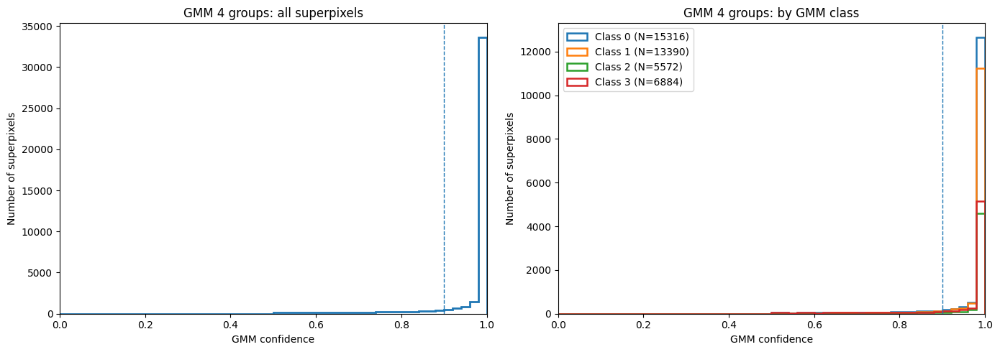

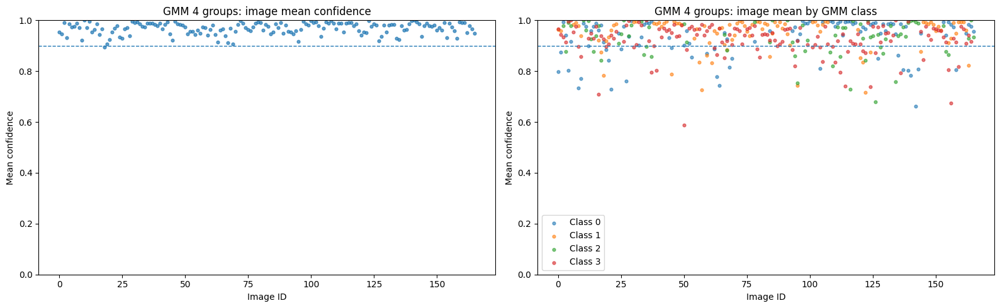


----------------------------------------------------------------------
GMM groups = 5
mean      = 0.955
median    = 0.999
std       = 0.104
p90       = 1.000
p75       = 1.000
>= 0.90   = 0.858
>= 0.80   = 0.912
>= 0.70   = 0.945
>= 0.50   = 0.997
cluster sizes = [ 6092 11013  2467 14500  7090]


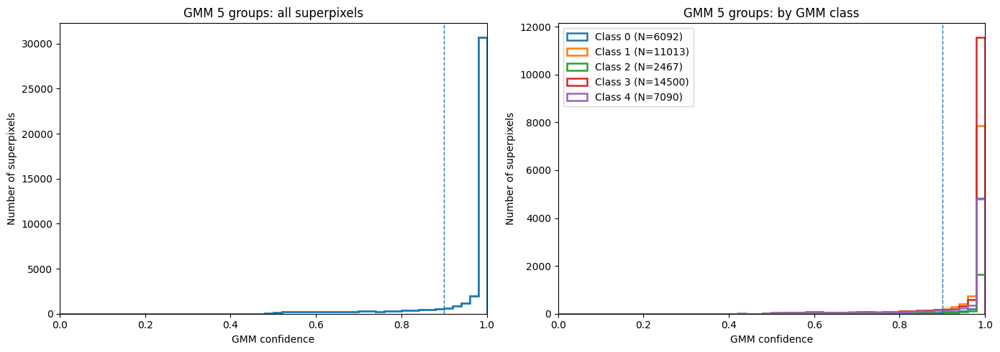

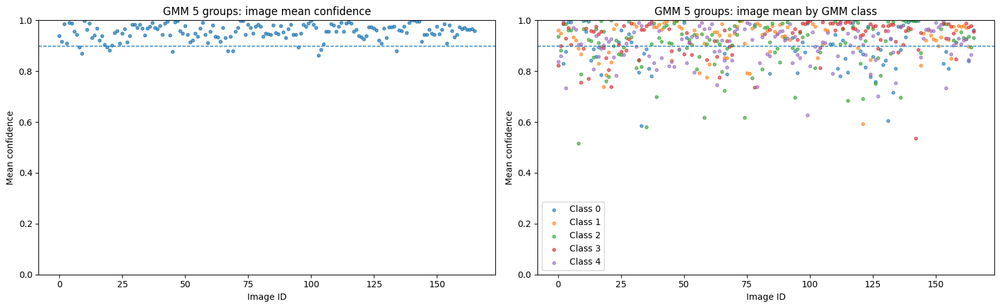


----------------------------------------------------------------------
GMM groups = 6
mean      = 0.937
median    = 0.996
std       = 0.118
p90       = 1.000
p75       = 1.000
>= 0.90   = 0.803
>= 0.80   = 0.874
>= 0.70   = 0.923
>= 0.50   = 0.997
cluster sizes = [ 5887  5234 11385  1733  7759  9164]


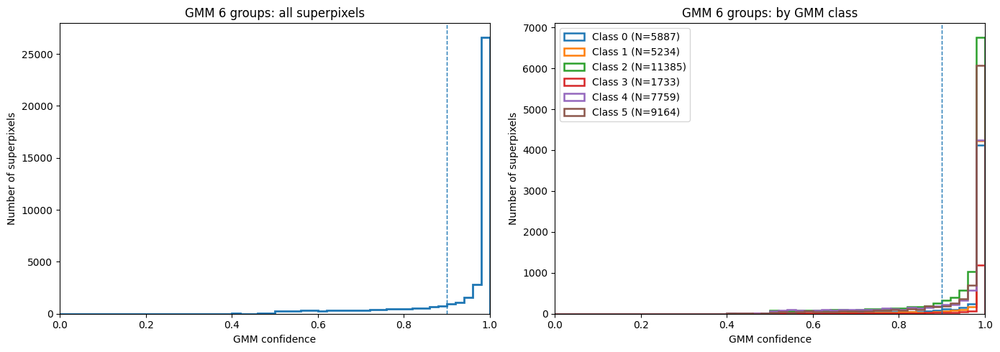

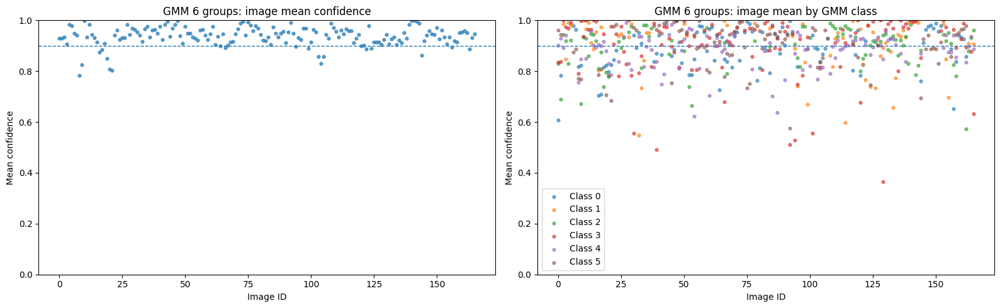


----------------------------------------------------------------------
GMM groups = 7
mean      = 0.926
median    = 0.993
std       = 0.126
p90       = 1.000
p75       = 1.000
>= 0.90   = 0.769
>= 0.80   = 0.852
>= 0.70   = 0.908
>= 0.50   = 0.994
cluster sizes = [ 5258  7242 10418  7487  1401  4708  4648]


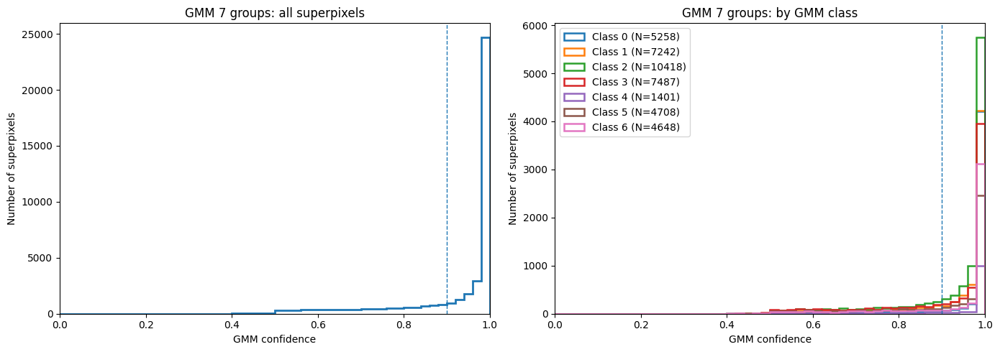

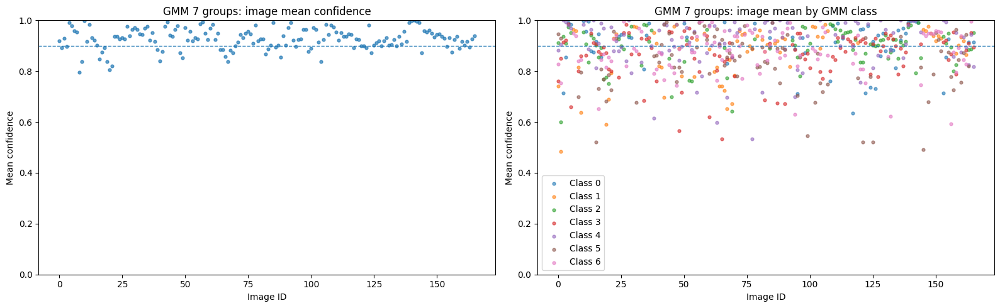


----------------------------------------------------------------------
GMM groups = 8
mean      = 0.919
median    = 0.990
std       = 0.133
p90       = 1.000
p75       = 1.000
>= 0.90   = 0.748
>= 0.80   = 0.834
>= 0.70   = 0.895
>= 0.50   = 0.992
cluster sizes = [7102 8943 4755 4575 2899 4752 1029 7107]


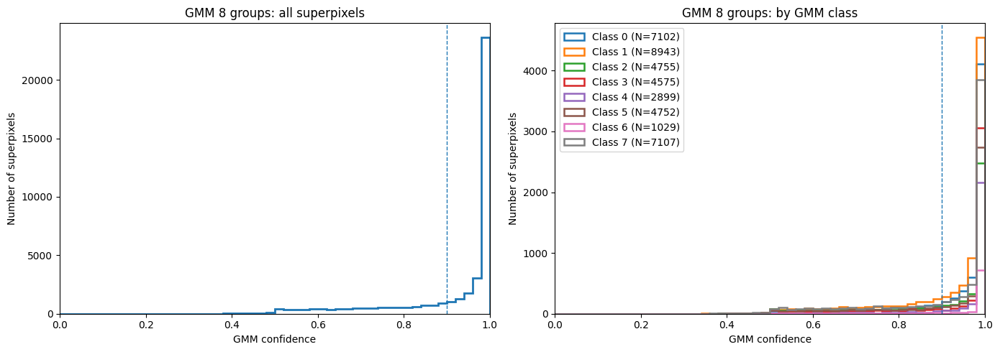

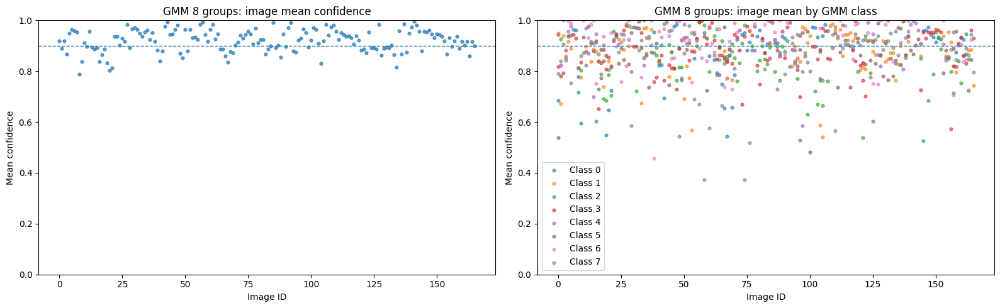


FINAL RESULTS
 n_gmm_groups  pca_components  explained_variance  n_superpixels  mean_confidence  median_confidence  std_confidence  p90_confidence  p75_confidence  fraction_conf_ge_0.90  fraction_conf_ge_0.80  fraction_conf_ge_0.70  fraction_conf_ge_0.50
            4              15             0.99904          41162         0.967963           0.999831        0.088736        1.000000        0.999990               0.900151               0.937418               0.961348               0.999150
            5              15             0.99904          41162         0.954902           0.999459        0.103609        1.000000        0.999993               0.858389               0.911593               0.945338               0.997425
            6              15             0.99904          41162         0.937009           0.995935        0.117842        0.999999        0.999908               0.802852               0.873913               0.922866               0.997182
            7        

0

In [ ]:
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

csv_path = "validation3/training3_low/stage1_GMM/data2_all/GMM_RF1_training.csv"

feature_names = ["Variance","Gradient","Entropy","Edge density","Coherence","L","a","b","Brightness range","LBP","Coherence std","Coherence p90","GLCM contrast","GLCM homogeneity","GLCM energy","GLCM correlation","Edge dominant angle","Edge angle entropy"]

pca_components = 15
gmm_groups_list = [4,5,6,7,8]
random_state = 0

image_id_candidates = ["image_id","image","image_path","path","filename","file","Image","Image ID"]

df = pd.read_csv(csv_path)
df = df.dropna(subset=feature_names+["manual_label"]).copy()
df["manual_label"] = df["manual_label"].astype(int)

image_col = None
for col in image_id_candidates:
    if col in df.columns:
        image_col = col
        break

if image_col is None:
    raise ValueError("画像IDの列が見つかりません。df.columns を確認してください。")

print("Data:",len(df),"superpixels")
print("Image column:",image_col)
print("PCA components:",pca_components)
print("GMM groups:",gmm_groups_list)

X = df[feature_names].values
X = StandardScaler().fit_transform(X)

pca = PCA(n_components=pca_components,random_state=random_state)
X_pca = pca.fit_transform(X)

explained = pca.explained_variance_ratio_.sum()

print("PCA explained variance =",f"{explained:.4f}")

all_results = []

for n_gmm in gmm_groups_list:
    print("\n"+"-"*70)
    print("GMM groups =",n_gmm)

    gmm = GaussianMixture(n_components=n_gmm,covariance_type="full",random_state=random_state,n_init=5)
    gmm.fit(X_pca)

    probabilities = gmm.predict_proba(X_pca)
    labels = np.argmax(probabilities,axis=1)
    confidence = probabilities[np.arange(len(probabilities)),labels]

    mean_conf = confidence.mean()
    median_conf = np.median(confidence)
    std_conf = confidence.std()
    p90_conf = np.percentile(confidence,90)
    p75_conf = np.percentile(confidence,75)

    high_90 = np.mean(confidence >= 0.90)
    high_80 = np.mean(confidence >= 0.80)
    high_70 = np.mean(confidence >= 0.70)
    high_50 = np.mean(confidence >= 0.50)

    cluster_sizes = np.bincount(labels,minlength=n_gmm)

    print("mean      =",f"{mean_conf:.3f}")
    print("median    =",f"{median_conf:.3f}")
    print("std       =",f"{std_conf:.3f}")
    print("p90       =",f"{p90_conf:.3f}")
    print("p75       =",f"{p75_conf:.3f}")
    print(">= 0.90   =",f"{high_90:.3f}")
    print(">= 0.80   =",f"{high_80:.3f}")
    print(">= 0.70   =",f"{high_70:.3f}")
    print(">= 0.50   =",f"{high_50:.3f}")
    print("cluster sizes =",cluster_sizes)

    all_results.append({
        "n_gmm_groups":n_gmm,
        "pca_components":pca_components,
        "explained_variance":explained,
        "n_superpixels":len(df),
        "mean_confidence":mean_conf,
        "median_confidence":median_conf,
        "std_confidence":std_conf,
        "p90_confidence":p90_conf,
        "p75_confidence":p75_conf,
        "fraction_conf_ge_0.90":high_90,
        "fraction_conf_ge_0.80":high_80,
        "fraction_conf_ge_0.70":high_70,
        "fraction_conf_ge_0.50":high_50
    })

    df_plot = df[[image_col]].copy()
    df_plot["confidence"] = confidence
    df_plot["gmm_class"] = labels

    image_mean = df_plot.groupby(image_col)["confidence"].mean()

    image_class_mean = df_plot.groupby([image_col,"gmm_class"])["confidence"].mean().unstack()

    fig,axes = plt.subplots(1,2,figsize=(14,5))

    bins = np.linspace(0,1,51)

    axes[0].hist(confidence,bins=bins,histtype="step",linewidth=2)
    axes[0].axvline(0.9,linestyle="--",linewidth=1)
    axes[0].set_xlabel("GMM confidence")
    axes[0].set_ylabel("Number of superpixels")
    axes[0].set_title(f"GMM {n_gmm} groups: all superpixels")
    axes[0].set_xlim(0,1)

    for k in range(n_gmm):
        values = confidence[labels == k]
        axes[1].hist(values,bins=bins,histtype="step",linewidth=1.8,label=f"Class {k} (N={len(values)})")

    axes[1].axvline(0.9,linestyle="--",linewidth=1)
    axes[1].set_xlabel("GMM confidence")
    axes[1].set_ylabel("Number of superpixels")
    axes[1].set_title(f"GMM {n_gmm} groups: by GMM class")
    axes[1].set_xlim(0,1)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    fig,axes = plt.subplots(1,2,figsize=(16,5))

    image_ids = image_mean.index.astype(str)
    x = np.arange(len(image_ids))

    axes[0].scatter(x,image_mean.values,s=12,alpha=0.7)
    axes[0].axhline(0.9,linestyle="--",linewidth=1)
    axes[0].set_xlabel("Image ID")
    axes[0].set_ylabel("Mean confidence")
    axes[0].set_title(f"GMM {n_gmm} groups: image mean confidence")
    axes[0].set_ylim(0,1)

    for k in range(n_gmm):
        if k in image_class_mean.columns:
            values = image_class_mean[k]
            mask = values.notna()
            axes[1].scatter(x[mask.values],values[mask].values,s=12,alpha=0.6,label=f"Class {k}")

    axes[1].axhline(0.9,linestyle="--",linewidth=1)
    axes[1].set_xlabel("Image ID")
    axes[1].set_ylabel("Mean confidence")
    axes[1].set_title(f"GMM {n_gmm} groups: image mean by GMM class")
    axes[1].set_ylim(0,1)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    del gmm,probabilities,labels,confidence,df_plot,image_mean,image_class_mean
    gc.collect()

results_df = pd.DataFrame(all_results)

print("\nFINAL RESULTS")
print(results_df.to_string(index=False))

print("\nMEAN CONFIDENCE")
print(results_df[["n_gmm_groups","mean_confidence"]].round(3).to_string(index=False))

print("\nFRACTION WITH CONFIDENCE >= 0.90")
print(results_df[["n_gmm_groups","fraction_conf_ge_0.90"]].round(3).to_string(index=False))

print("\nFRACTION WITH CONFIDENCE >= 0.80")
print(results_df[["n_gmm_groups","fraction_conf_ge_0.80"]].round(3).to_string(index=False))

del X,X_pca,pca,df
gc.collect()

In [ ]:
import os
import gc
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

old_csv_path = "validation3/training3_low/stage1_GMM/data1/GMM_RF1_training_2.csv"
new_csv_path = "validation3/training3_low/stage1_GMM/data21/GMM_RF1_training.csv"
output_dir = "validation3/training3_low/stage1_GMM/data2_all/gmm_results"
os.makedirs(output_dir,exist_ok=True)

pca_components = 15
gmm_groups_list = [6]
small_class_max_size = 10
small_class_keep_confidence = 0.9
random_state = 0

feature_names = ["Variance","Gradient","Entropy","Edge density","Coherence","L","a","b","Brightness range","LBP","Coherence std","Coherence p90","GLCM contrast","GLCM homogeneity","GLCM energy","GLCM correlation","Edge dominant angle","Edge angle entropy"]

old_df = pd.read_csv(old_csv_path)
new_df = pd.read_csv(new_csv_path)
old_df = old_df.dropna(subset=feature_names).copy()
new_df = new_df.dropna(subset=feature_names).copy()
old_df["dataset_type"] = "old"
new_df["dataset_type"] = "new"
df = pd.concat([old_df,new_df],ignore_index=True)

print("Total superpixels:",len(df))
print("Old:",len(old_df))
print("New:",len(new_df))

X = StandardScaler().fit_transform(df[feature_names].values)
pca = PCA(n_components=pca_components,random_state=random_state)
X_pca = pca.fit_transform(X)
print("PCA explained variance:",pca.explained_variance_ratio_.sum())

for n_gmm in gmm_groups_list:
    print(f"\nGMM = {n_gmm}")

    gmm = GaussianMixture(n_components=n_gmm,covariance_type="full",random_state=random_state,n_init=5)
    gmm.fit(X_pca)

    probabilities = gmm.predict_proba(X_pca)
    raw_labels = np.argmax(probabilities,axis=1)
    confidence = probabilities[np.arange(len(raw_labels)),raw_labels]
    final_labels = raw_labels.copy()

    df_work = df[["image_id"]].copy()
    df_work["raw_class"] = raw_labels
    df_work["confidence"] = confidence

    total_merged = 0
    total_kept_small = 0

    print("\nImage-by-image merging:")

    for image_id,image_group in df_work.groupby("image_id"):
        image_indices = image_group.index.to_numpy()
        image_labels = raw_labels[image_indices]
        image_confidence = confidence[image_indices]
        image_probabilities = probabilities[image_indices]

        class_counts = pd.Series(image_labels).value_counts().to_dict()
        image_small_classes = [k for k,n in class_counts.items() if n <= small_class_max_size]
        image_large_classes = [k for k,n in class_counts.items() if n >= small_class_max_size]

        for k in image_small_classes:
            k_indices = image_indices[image_labels == k]
            k_confidence = confidence[k_indices]
            mean_conf = float(k_confidence.mean())
            n = len(k_indices)

            if mean_conf >= small_class_keep_confidence:
                total_kept_small += 1
                print(f"  image={image_id}: Class {k} N={n} KEEP (mean conf={mean_conf:.4f})")
                continue

            candidates = [c for c in image_large_classes if c != k]

            if len(candidates) == 0:
                total_kept_small += 1
                print(f"  image={image_id}: Class {k} N={n} KEEP (no N>=10 target)")
                continue

            candidate_scores = {}
            for c in candidates:
                candidate_scores[c] = float(probabilities[k_indices,c].mean())

            merge_target = max(candidate_scores,key=candidate_scores.get)
            final_labels[k_indices] = merge_target
            total_merged += 1

            score_text = ", ".join([f"C{c}={s:.4f}" for c,s in candidate_scores.items()])
            print(f"  image={image_id}: Class {k} N={n} -> Class {merge_target} (mean conf={mean_conf:.4f}; {score_text})")

    print("\nMerging summary")
    print("Merged small classes:",total_merged)
    print("Kept small classes:",total_kept_small)

    print("\nFinal class counts per image:")
    final_count_df = pd.DataFrame({"image_id":df["image_id"].values,"final_class":final_labels})
    final_counts = final_count_df.groupby(["image_id","final_class"]).size().reset_index(name="N")
    print(final_counts["N"].describe().round(2).to_string())

    print("\nRemaining N<10 classes:")
    remaining_small = final_counts[final_counts["N"] < 10]
    print("Number:",len(remaining_small))
    if len(remaining_small) > 0:
        print(remaining_small.to_string(index=False))

    df_result = df.copy()
    df_result[f"gmm{n_gmm}_raw_class"] = raw_labels
    df_result[f"gmm{n_gmm}_probability"] = confidence
    df_result[f"gmm{n_gmm}_class"] = final_labels

    output_csv = os.path.join(output_dir,f"GMM{n_gmm}_result.csv")
    np.save(os.path.join(output_dir,f"gmm{n_gmm}_class.npy"),final_labels)
    np.save(os.path.join(output_dir,f"gmm{n_gmm}_probability.npy"),confidence)
    df_result.to_csv(output_csv,index=False)

    print("\nSaved:",output_csv)

    del gmm,probabilities,raw_labels,confidence,final_labels,df_result,df_work,final_count_df,final_counts
    gc.collect()

del old_df,new_df,df,X,X_pca,pca
gc.collect()

Total superpixels: 41162
Old: 18360
New: 22802
PCA explained variance: 0.9990395431513075

GMM = 6

Image-by-image merging:
  image=0: Class 3 N=8 -> Class 4 (mean conf=0.8521; C5=0.0000, C0=0.0047, C4=0.1431)
  image=0: Class 2 N=1 -> Class 4 (mean conf=0.8299; C5=0.0000, C0=0.0000, C4=0.1701)
  image=1: Class 3 N=5 -> Class 4 (mean conf=0.8374; C0=0.0276, C4=0.0975, C5=0.0376)
  image=1: Class 2 N=1 -> Class 4 (mean conf=0.6904; C0=0.0000, C4=0.3093, C5=0.0000)
  image=2: Class 3 N=5 KEEP (mean conf=0.9939)
  image=2: Class 5 N=5 -> Class 0 (mean conf=0.7517; C0=0.2483, C2=0.0000, C4=0.0000)
  image=2: Class 1 N=1 KEEP (mean conf=0.9850)
  image=3: Class 3 N=7 -> Class 0 (mean conf=0.8737; C2=0.0007, C5=0.0000, C0=0.1107, C1=0.0000, C4=0.0149)
  image=5: Class 0 N=10 -> Class 5 (mean conf=0.7634; C1=0.0000, C5=0.2362, C2=0.0000)
  image=5: Class 3 N=4 KEEP (mean conf=0.9918)
  image=7: Class 3 N=4 -> Class 0 (mean conf=0.8057; C0=0.1938, C5=0.0005)
  image=8: Class 3 N=10 KEEP (mean 

0

GMM result: 41162 superpixels
GMM classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

old image 25 (id=24)
  Class 0: N=0, mean confidence=nan
  Class 1: N=121, mean confidence=0.935
  Class 2: N=179, mean confidence=0.917
  Class 3: N=0, mean confidence=nan
  Class 4: N=0, mean confidence=nan
  Class 5: N=0, mean confidence=nan


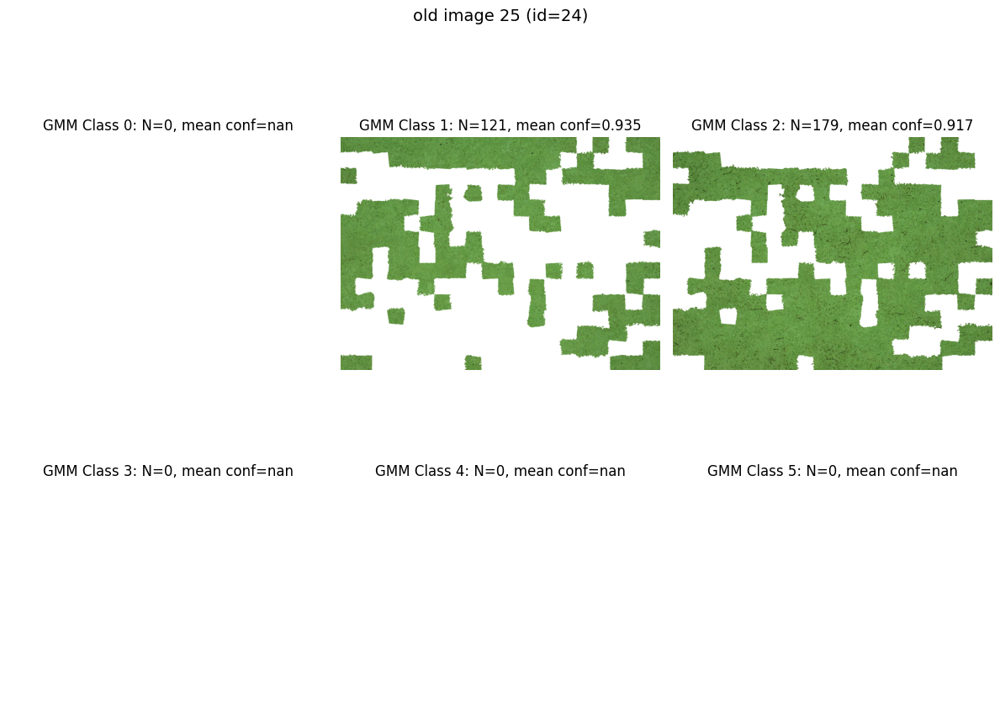


old image 26 (id=25)
  Class 0: N=0, mean confidence=nan
  Class 1: N=219, mean confidence=0.945
  Class 2: N=75, mean confidence=0.892
  Class 3: N=6, mean confidence=0.975
  Class 4: N=0, mean confidence=nan
  Class 5: N=0, mean confidence=nan


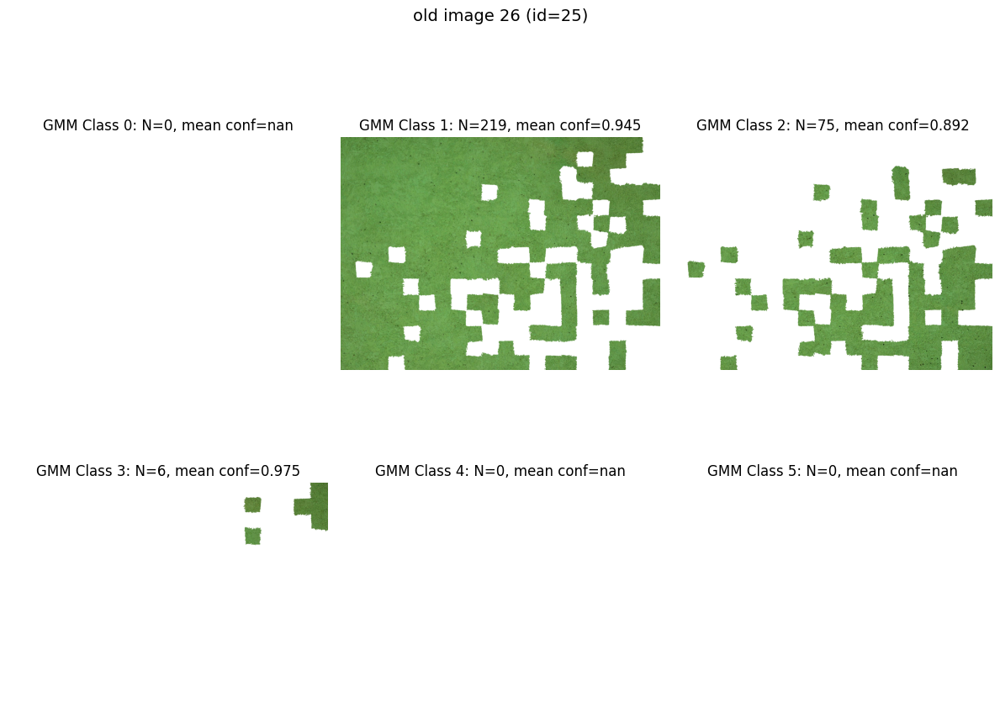


old image 27 (id=26)
  Class 0: N=0, mean confidence=nan
  Class 1: N=0, mean confidence=nan
  Class 2: N=137, mean confidence=0.932
  Class 3: N=13, mean confidence=0.876
  Class 4: N=129, mean confidence=0.938
  Class 5: N=0, mean confidence=nan


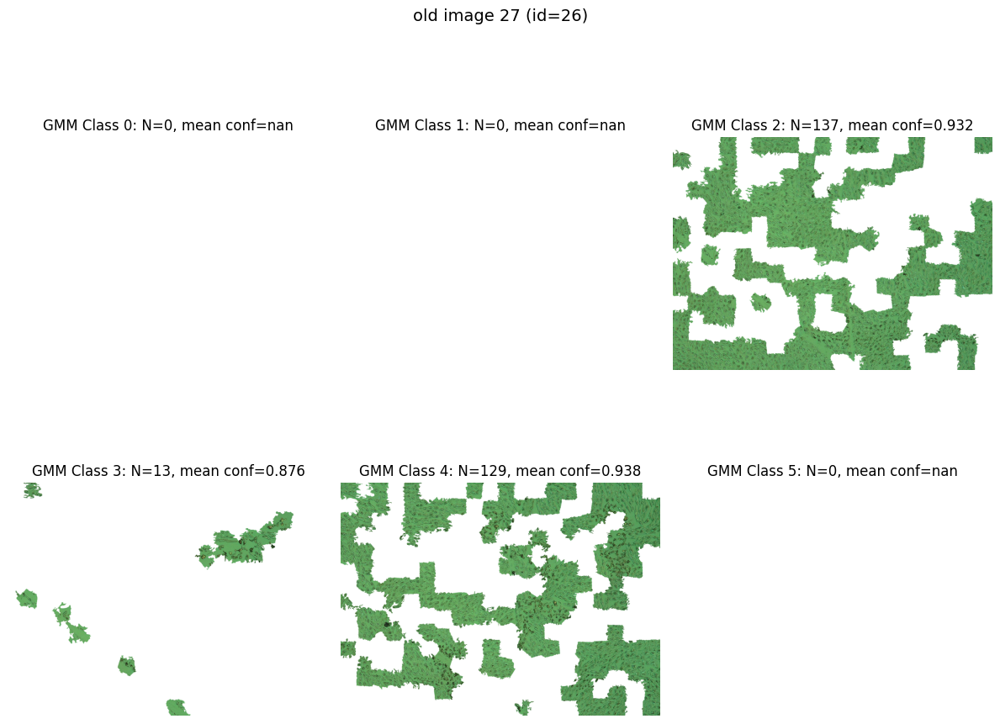


old image 28 (id=27)
  Class 0: N=0, mean confidence=nan
  Class 1: N=0, mean confidence=nan
  Class 2: N=0, mean confidence=nan
  Class 3: N=11, mean confidence=0.826
  Class 4: N=206, mean confidence=0.991
  Class 5: N=0, mean confidence=nan


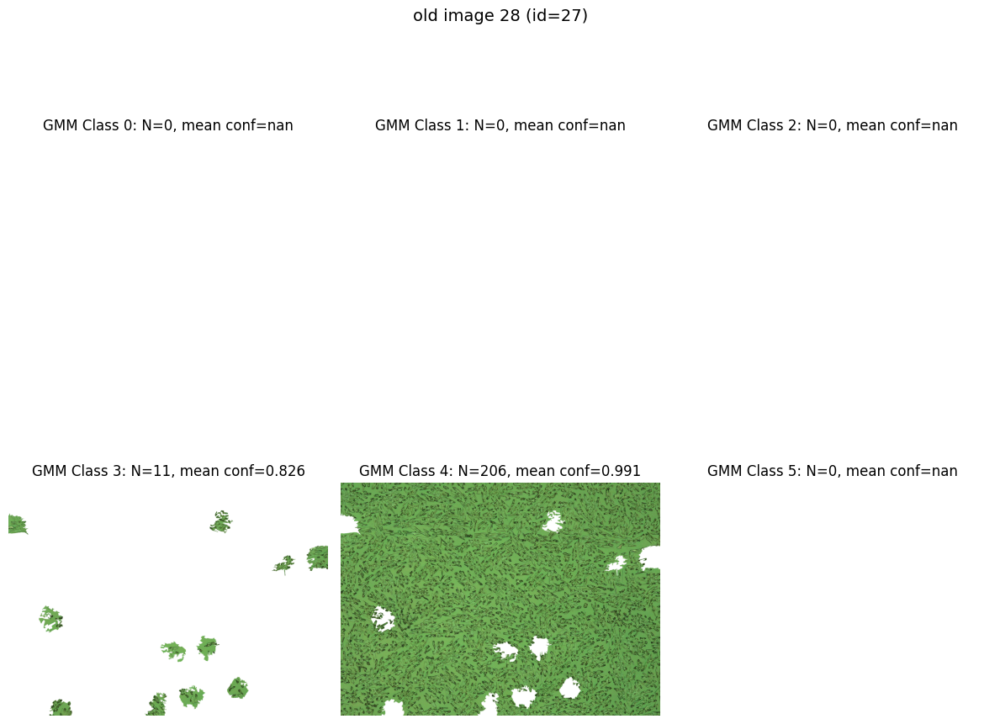


old image 29 (id=28)
  Class 0: N=0, mean confidence=nan
  Class 1: N=132, mean confidence=0.935
  Class 2: N=157, mean confidence=0.949
  Class 3: N=5, mean confidence=1.000
  Class 4: N=0, mean confidence=nan
  Class 5: N=0, mean confidence=nan


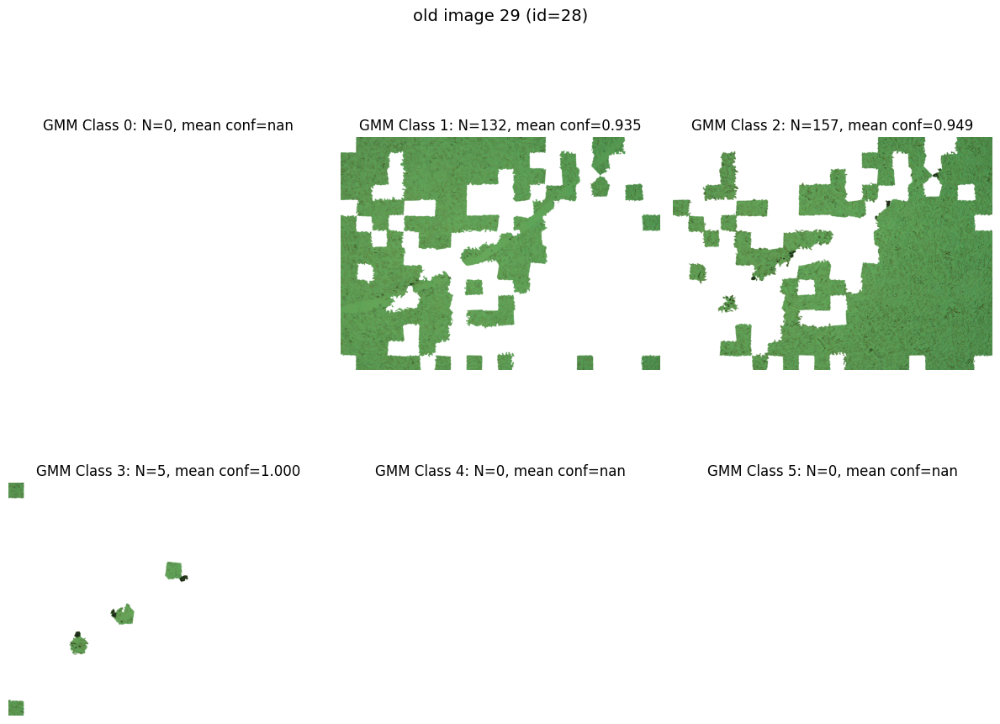


old image 30 (id=29)
  Class 0: N=0, mean confidence=nan
  Class 1: N=22, mean confidence=0.959
  Class 2: N=257, mean confidence=0.977
  Class 3: N=0, mean confidence=nan
  Class 4: N=11, mean confidence=0.807
  Class 5: N=0, mean confidence=nan


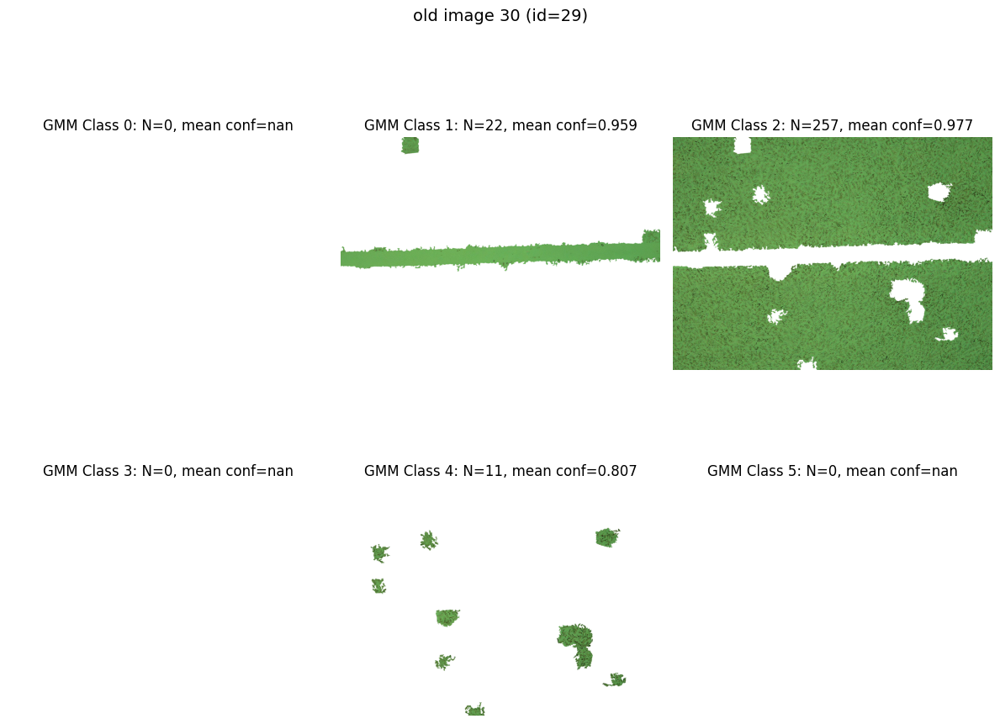


old image 31 (id=30)
  Class 0: N=27, mean confidence=0.927
  Class 1: N=0, mean confidence=nan
  Class 2: N=0, mean confidence=nan
  Class 3: N=0, mean confidence=nan
  Class 4: N=0, mean confidence=nan
  Class 5: N=150, mean confidence=0.971


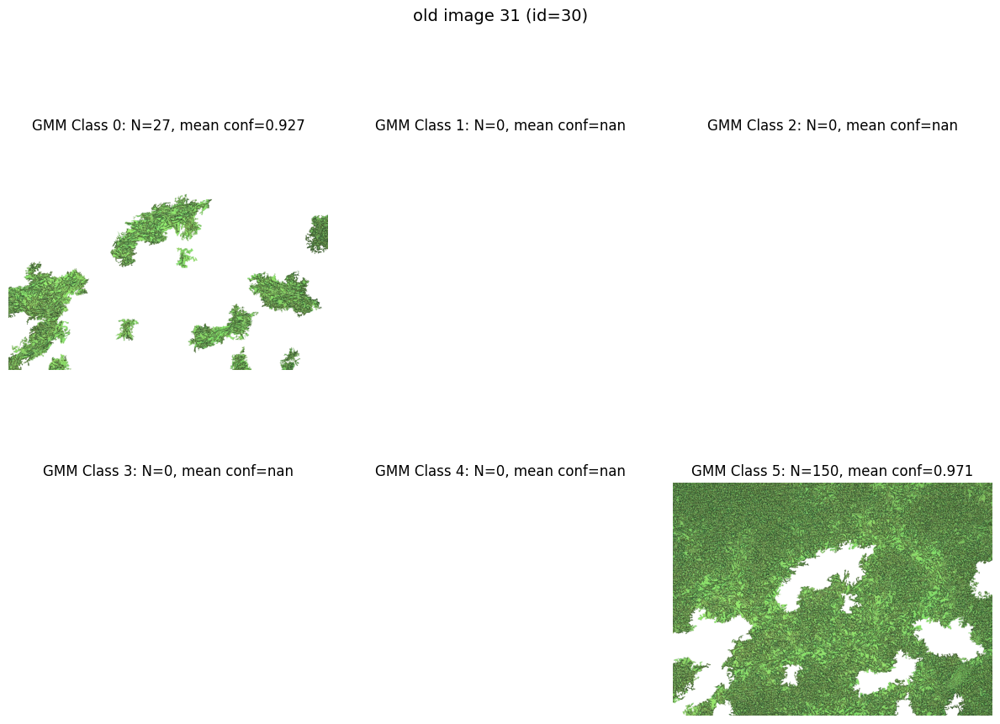


old image 32 (id=31)
  Class 0: N=25, mean confidence=0.892
  Class 1: N=0, mean confidence=nan
  Class 2: N=0, mean confidence=nan
  Class 3: N=0, mean confidence=nan
  Class 4: N=0, mean confidence=nan
  Class 5: N=172, mean confidence=0.962


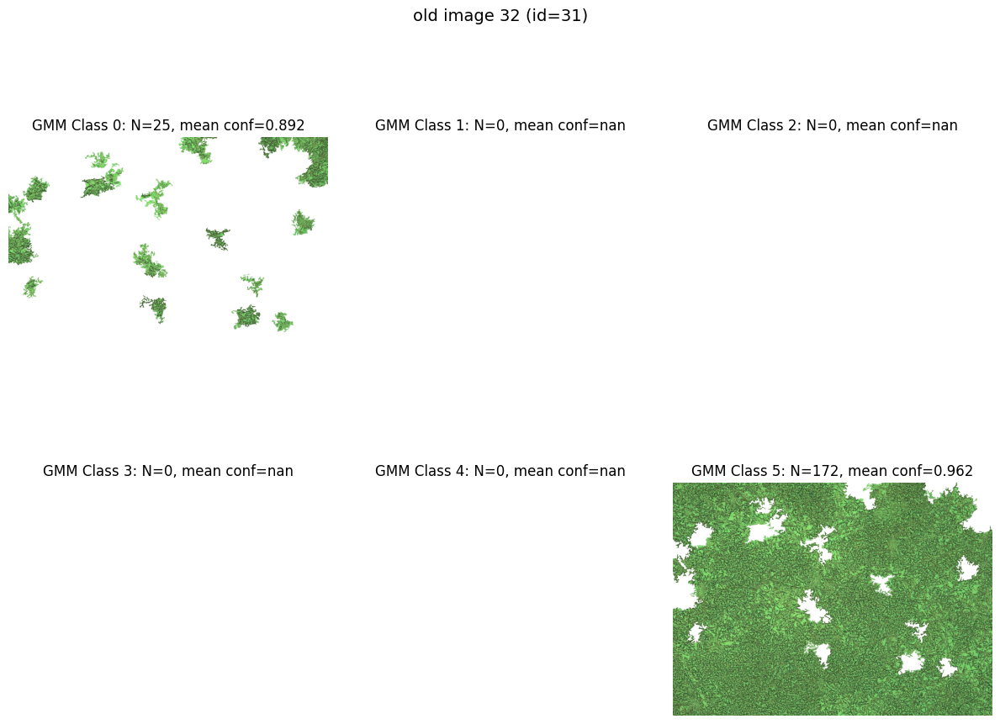


old image 33 (id=32)
  Class 0: N=126, mean confidence=0.947
  Class 1: N=0, mean confidence=nan
  Class 2: N=0, mean confidence=nan
  Class 3: N=0, mean confidence=nan
  Class 4: N=83, mean confidence=0.932
  Class 5: N=0, mean confidence=nan


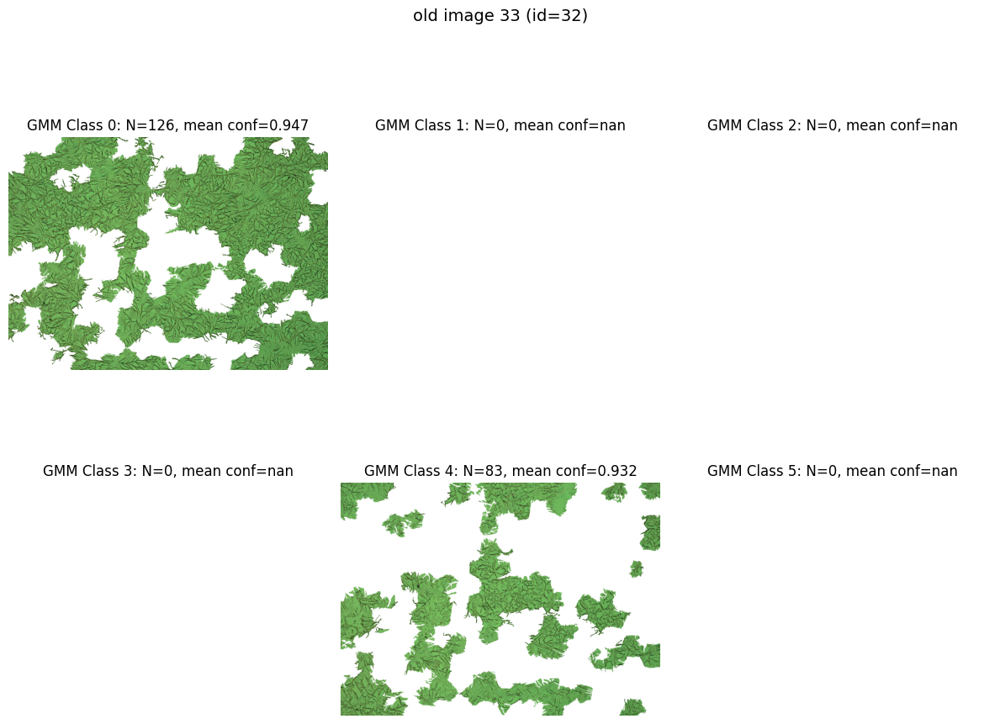


old image 34 (id=33)
  Class 0: N=90, mean confidence=0.908
  Class 1: N=0, mean confidence=nan
  Class 2: N=0, mean confidence=nan
  Class 3: N=22, mean confidence=0.855
  Class 4: N=107, mean confidence=0.934
  Class 5: N=0, mean confidence=nan


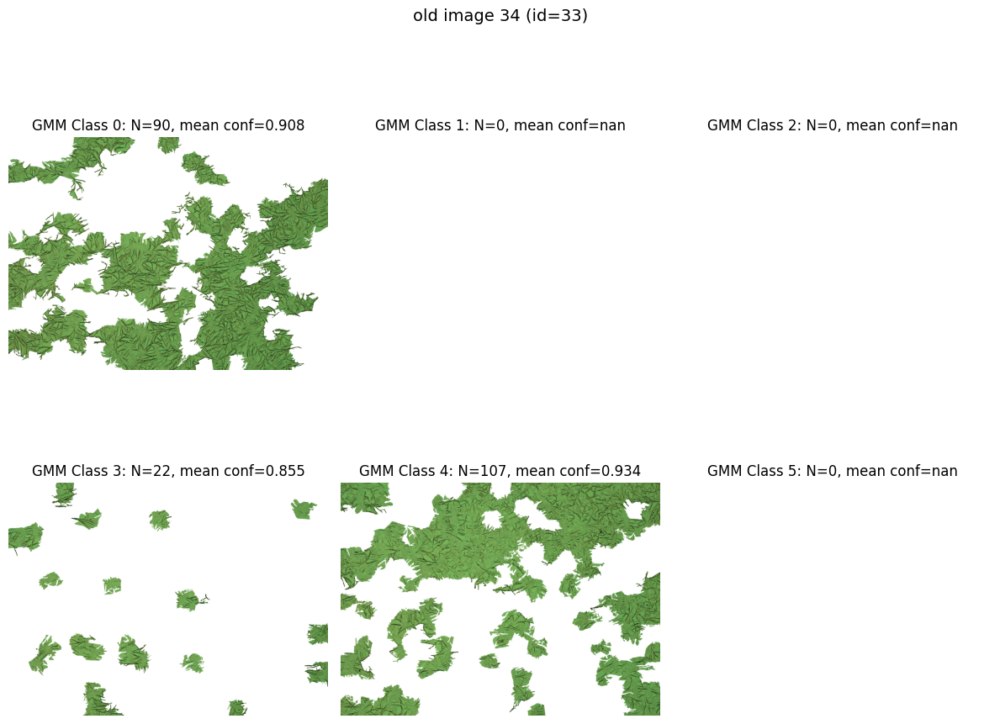


old image 35 (id=34)
  Class 0: N=0, mean confidence=nan
  Class 1: N=27, mean confidence=0.843
  Class 2: N=266, mean confidence=0.979
  Class 3: N=0, mean confidence=nan
  Class 4: N=0, mean confidence=nan
  Class 5: N=0, mean confidence=nan


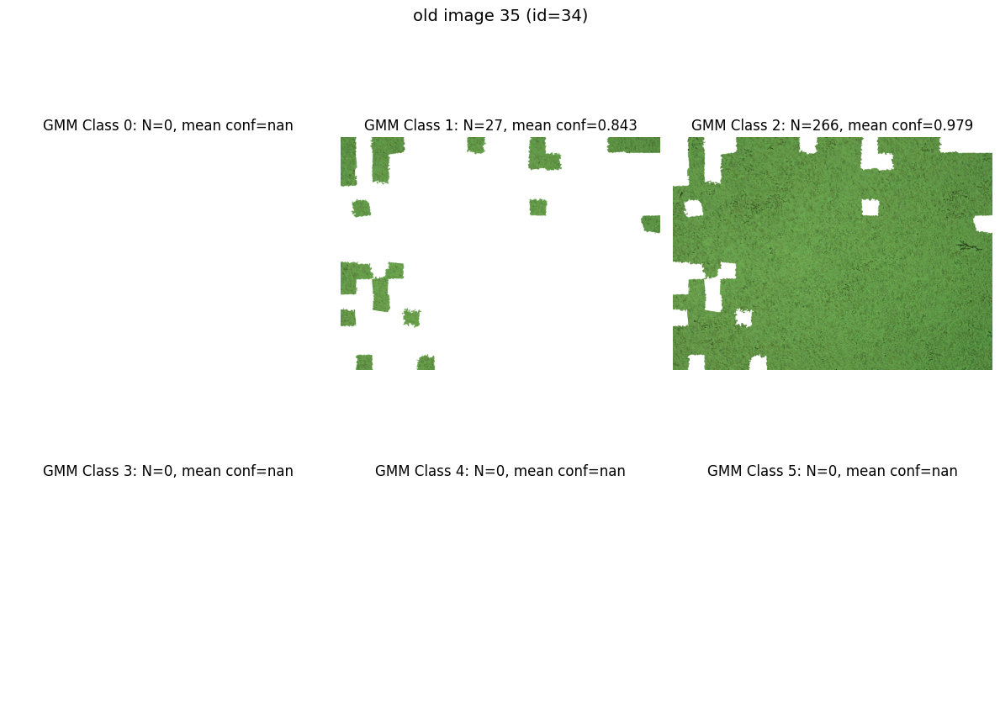


old image 36 (id=35)
  Class 0: N=0, mean confidence=nan
  Class 1: N=13, mean confidence=0.953
  Class 2: N=248, mean confidence=0.982
  Class 3: N=0, mean confidence=nan
  Class 4: N=17, mean confidence=0.898
  Class 5: N=0, mean confidence=nan


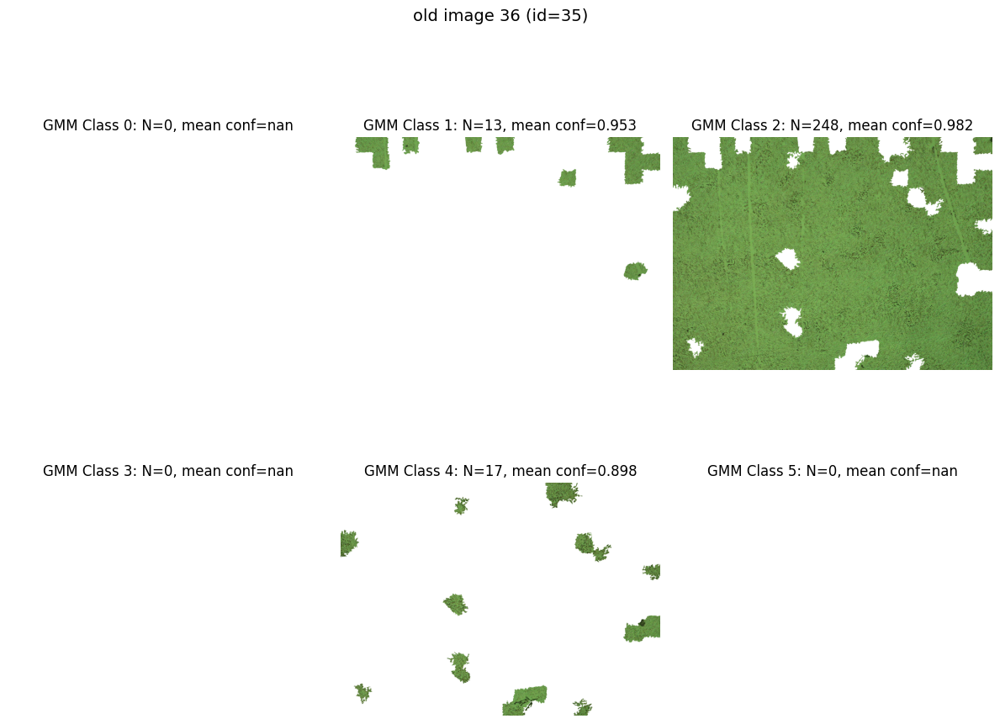


old image 37 (id=36)
  Class 0: N=0, mean confidence=nan
  Class 1: N=2, mean confidence=0.951
  Class 2: N=210, mean confidence=0.937
  Class 3: N=0, mean confidence=nan
  Class 4: N=64, mean confidence=0.921
  Class 5: N=0, mean confidence=nan


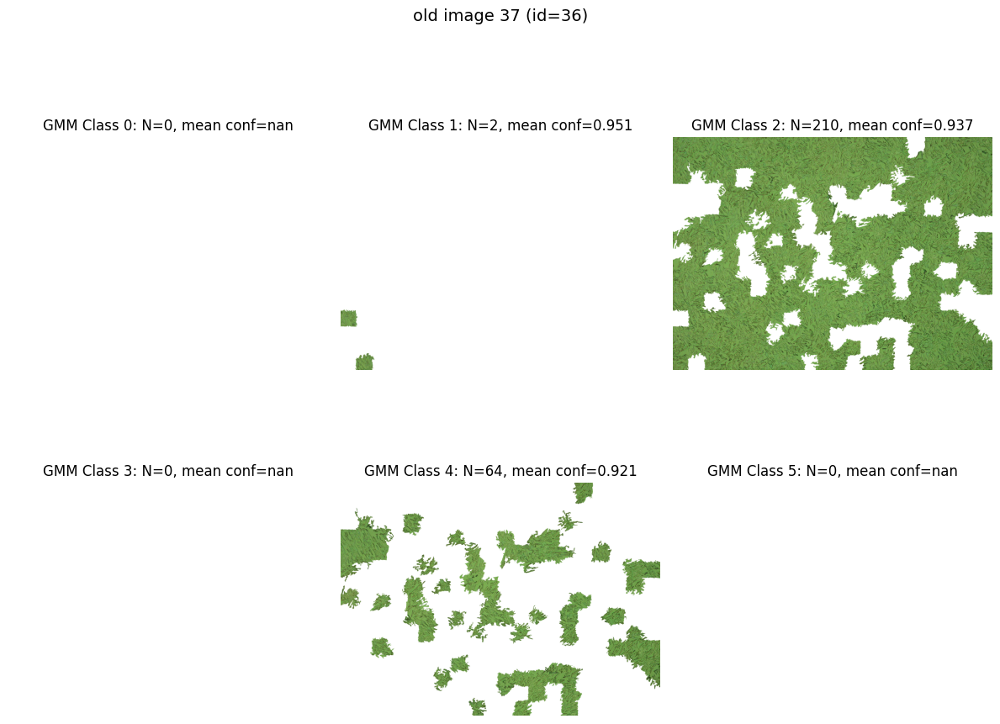


old image 38 (id=37)
  Class 0: N=0, mean confidence=nan
  Class 1: N=0, mean confidence=nan
  Class 2: N=257, mean confidence=0.968
  Class 3: N=0, mean confidence=nan
  Class 4: N=25, mean confidence=0.884
  Class 5: N=0, mean confidence=nan


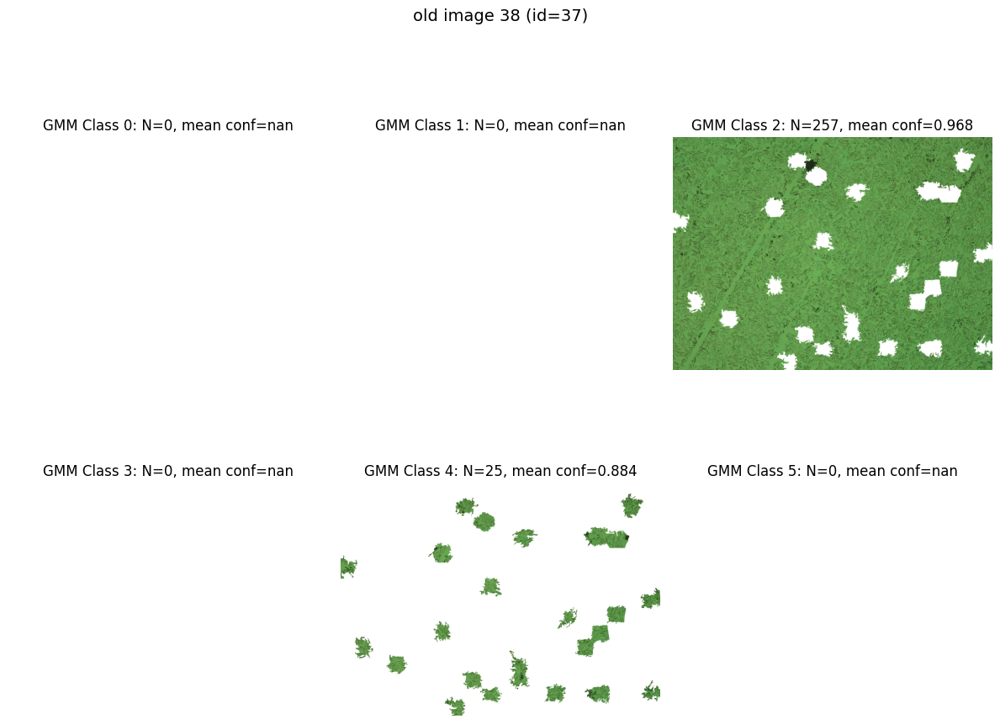


old image 39 (id=38)
  Class 0: N=23, mean confidence=0.837
  Class 1: N=0, mean confidence=nan
  Class 2: N=0, mean confidence=nan
  Class 3: N=4, mean confidence=0.988
  Class 4: N=1, mean confidence=0.815
  Class 5: N=183, mean confidence=0.979


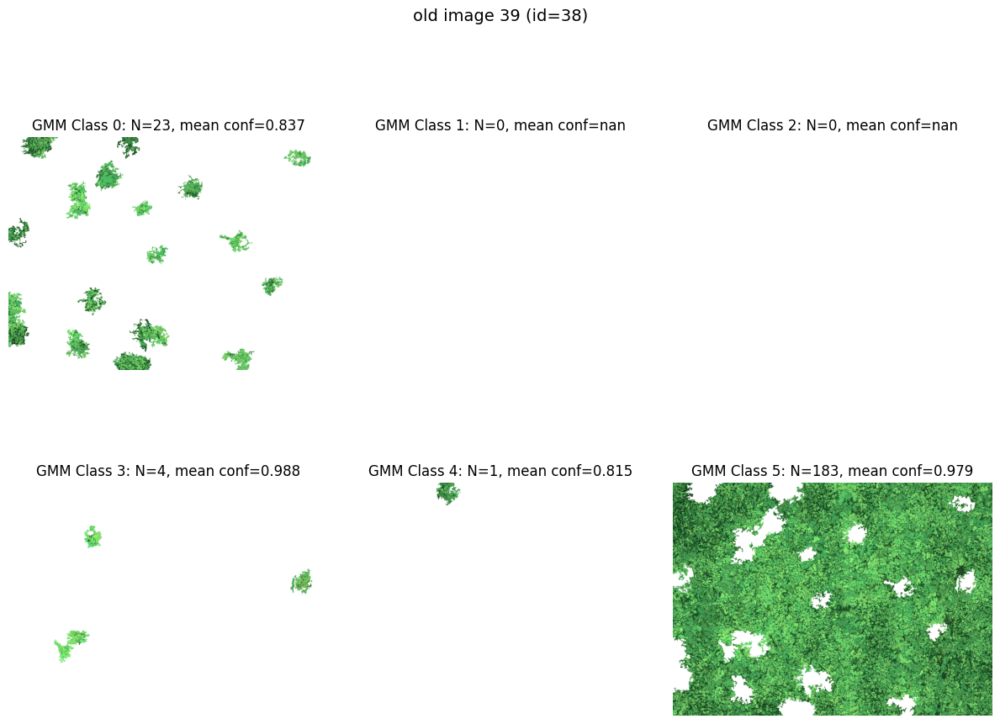


old image 40 (id=39)
  Class 0: N=15, mean confidence=0.870
  Class 1: N=0, mean confidence=nan
  Class 2: N=0, mean confidence=nan
  Class 3: N=1, mean confidence=0.492
  Class 4: N=9, mean confidence=0.837
  Class 5: N=182, mean confidence=0.963


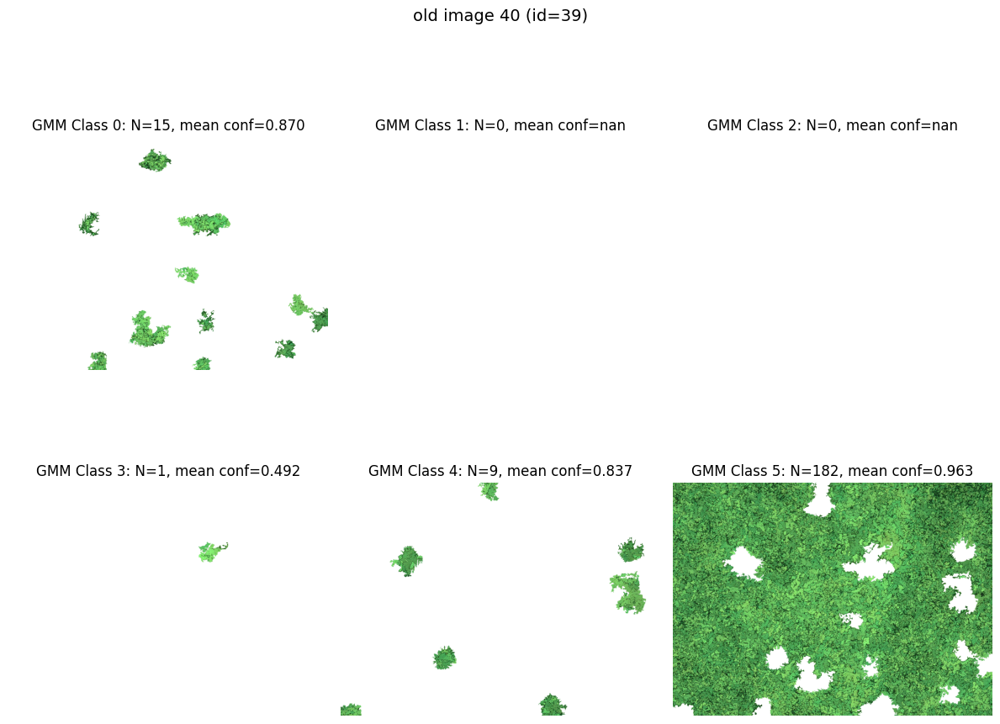


old image 41 (id=40)
  Class 0: N=12, mean confidence=0.942
  Class 1: N=0, mean confidence=nan
  Class 2: N=0, mean confidence=nan
  Class 3: N=24, mean confidence=0.955
  Class 4: N=0, mean confidence=nan
  Class 5: N=212, mean confidence=0.981


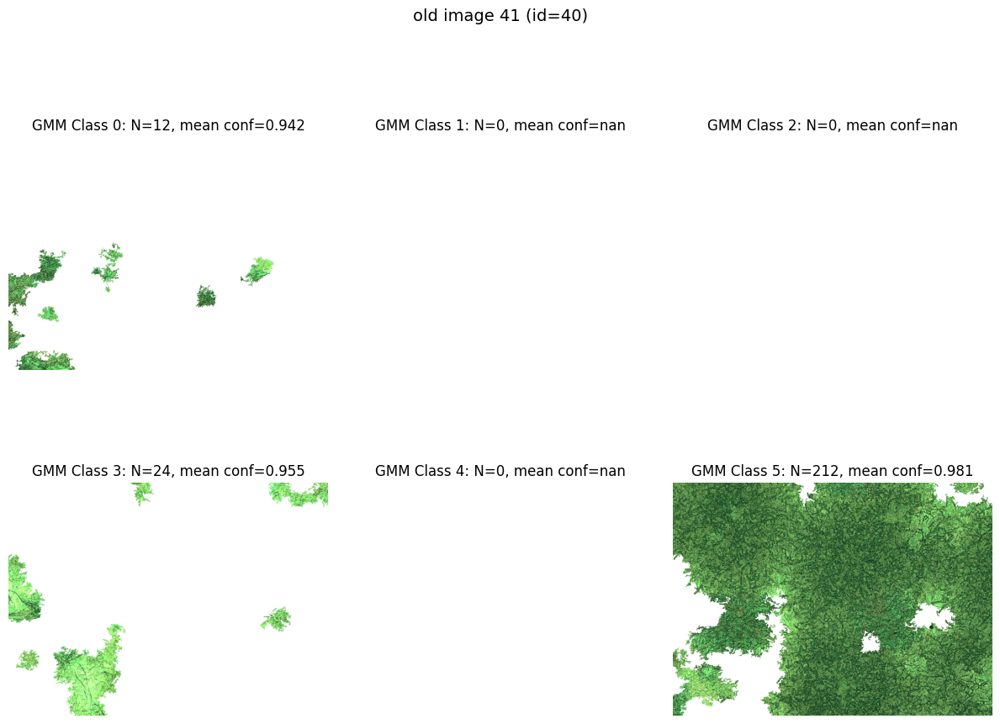


old image 42 (id=41)
  Class 0: N=48, mean confidence=0.865
  Class 1: N=0, mean confidence=nan
  Class 2: N=0, mean confidence=nan
  Class 3: N=33, mean confidence=0.906
  Class 4: N=3, mean confidence=0.749
  Class 5: N=158, mean confidence=0.948


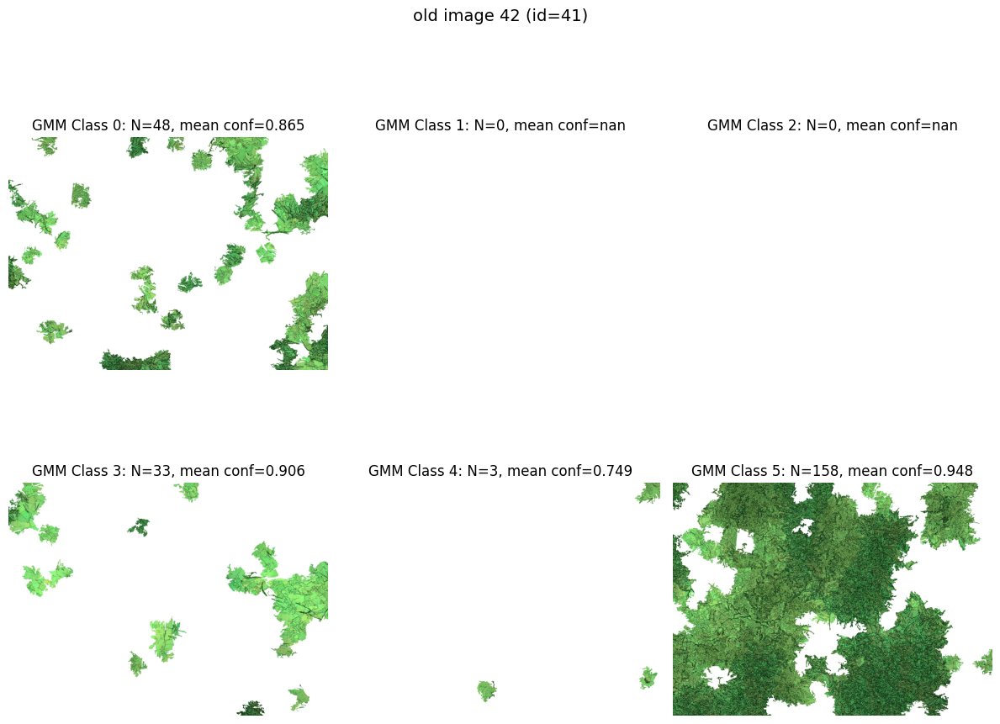


old image 43 (id=42)
  Class 0: N=0, mean confidence=nan
  Class 1: N=0, mean confidence=nan
  Class 2: N=0, mean confidence=nan
  Class 3: N=46, mean confidence=0.977
  Class 4: N=5, mean confidence=0.788
  Class 5: N=215, mean confidence=0.988


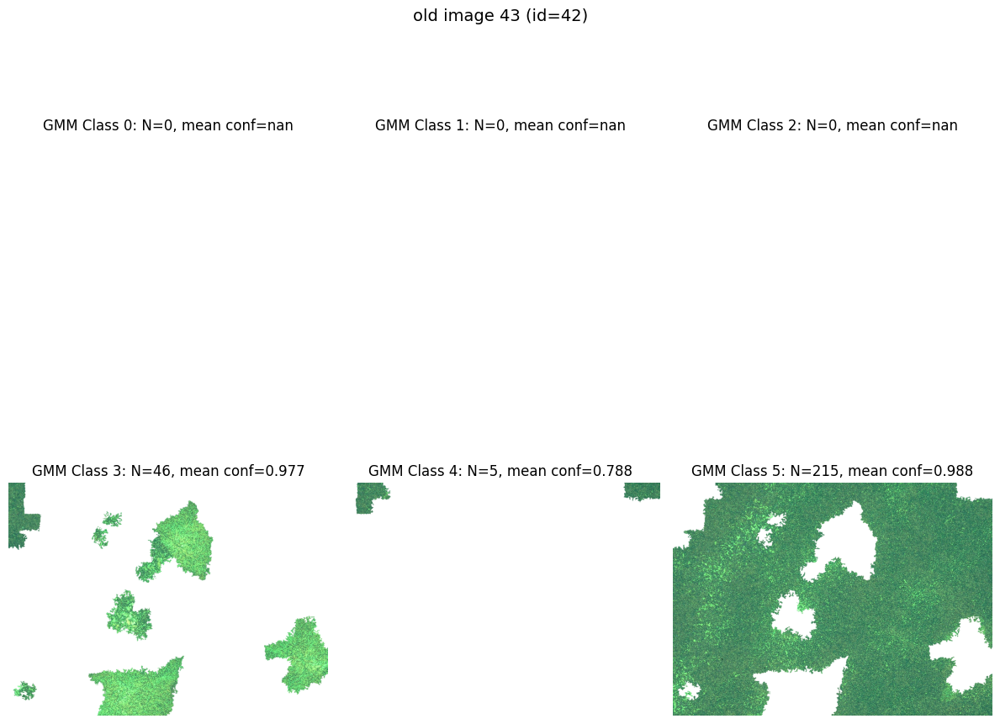


old image 44 (id=43)
  Class 0: N=0, mean confidence=nan
  Class 1: N=0, mean confidence=nan
  Class 2: N=0, mean confidence=nan
  Class 3: N=20, mean confidence=0.974
  Class 4: N=1, mean confidence=0.985
  Class 5: N=262, mean confidence=0.997


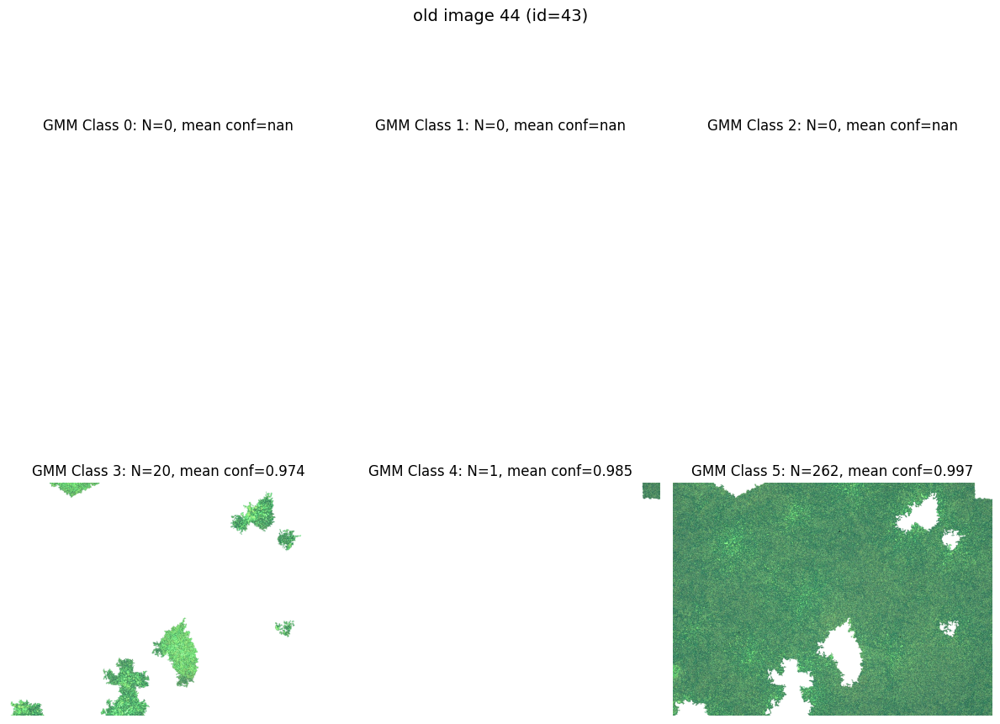

0

In [ ]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

old_data_path = "validation3/training3_low/stage1_GMM/data1"
new_data_path = "validation3/training3_low/stage1_GMM/data21"
gmm_result_path = "validation3/training3_low/stage1_GMM/data2_all/gmm_results/GMM6_result.csv"

start_image_num = 25
n_images_to_show = 20

df = pd.read_csv(gmm_result_path)

old_image_ids = np.load(os.path.join(old_data_path,"all_image_ids.npy"))
new_image_ids = np.load(os.path.join(new_data_path,"all_image_ids.npy"))

print("GMM result:",len(df),"superpixels")
print("GMM classes:",sorted(df["gmm6_class"].unique()))

for image_num in range(start_image_num,start_image_num+n_images_to_show):

    if image_num <= 74:
        dataset_type = "old"
        image_id = image_num - 1
        data_path = old_data_path
        all_image_ids = old_image_ids
    else:
        dataset_type = "new"
        image_id = image_num - 74
        data_path = new_data_path
        all_image_ids = new_image_ids

    images_dir = os.path.join(data_path,"superpixel_data","images")
    segments_dir = os.path.join(data_path,"superpixel_data","segments")

    image_path = os.path.join(images_dir,f"image_{image_id:03d}.npy")
    segment_path = os.path.join(segments_dir,f"segments_{image_id:03d}.npy")

    if not os.path.exists(image_path) or not os.path.exists(segment_path):
        print(f"[WARNING] image {image_num}: file not found")
        continue

    image = np.load(image_path)
    segments = np.load(segment_path)

    image_df = df[(df["dataset_type"]==dataset_type)&(df["image_id"]==image_id)].copy()

    global_indices = np.where(all_image_ids==image_id)[0]
    global_to_local = {int(g):i+1 for i,g in enumerate(global_indices)}

    if image.dtype.kind == "f" and image.max() <= 1:
        image_disp = np.clip(image*255,0,255).astype(np.uint8)
    else:
        image_disp = np.clip(image,0,255).astype(np.uint8)

    fig,axes = plt.subplots(2,3,figsize=(12,10))
    axes = axes.ravel()

    print(f"\n{dataset_type} image {image_num} (id={image_id})")

    for k,ax in enumerate(axes):
        # if k==3:
        #     ax.axis("off")
        #     continue
        class_df = image_df[image_df["gmm6_class"]==k]
        sp_indices = class_df["superpixel_index"].astype(int).values

        local_segments = np.array([global_to_local[sp] for sp in sp_indices if sp in global_to_local],dtype=int)
        mask = np.isin(segments,local_segments)

        if image_disp.ndim == 2:
            display_image = np.full((*image_disp.shape,3),255,dtype=np.uint8)
            display_image[mask] = np.stack([image_disp[mask]]*3,axis=-1)
        else:
            display_image = np.full(image_disp[:,:,:3].shape,255,dtype=np.uint8)
            display_image[mask] = image_disp[:,:,:3][mask]

        mean_conf = class_df["gmm6_probability"].mean() if len(class_df) else np.nan

        print(f"  Class {k}: N={len(class_df)}, mean confidence={mean_conf:.3f}")

        ax.imshow(display_image)
        ax.axis("off")
        ax.set_title(f"GMM Class {k}: N={len(class_df)}, mean conf={mean_conf:.3f}")

    plt.suptitle(f"{dataset_type} image {image_num} (id={image_id})",fontsize=14)
    plt.tight_layout()
    plt.show()

    del image,segments,image_df,global_indices,global_to_local,image_disp,fig,axes
    gc.collect()

del df,old_image_ids,new_image_ids
gc.collect()

In [ ]:
#

In [ ]:
#

In [ ]:
# RF testのいろいろ #

In [ ]:
# group 1,2,3,4
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# csv_path = os.path.join(path_for_data, "GMM_RF1_training.csv")
csv_path = "/home/kmanabe2403/document/dune/superpixel/validation3/training3_low/stage1_GMM/data2_all/GMM_RF1_training.csv"

probability_cut = 0.90
# feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b"]
feature_names = [
    "Variance", "Gradient", "Entropy", "Edge density", "Coherence",
    "L", "a", "b", "Brightness range", "LBP",
    "Coherence std", "Coherence p90",
    "GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation",
    "Edge dominant angle", "Edge angle entropy"
]

df = pd.read_csv(csv_path)
df = df.dropna(subset=feature_names + ["manual_label", "gmm_probability"]).reset_index(drop=True)
df["manual_label"] = df["manual_label"].astype(int)

print("=== Before GMM probability cut ===")
print(df["manual_label"].value_counts().sort_index())

df = df[(df["gmm_probability"] >= probability_cut) & (df["manual_label"] != 0)].reset_index(drop=True)

print("=== After GMM probability cut ===")
print(df["manual_label"].value_counts().sort_index())


# 評価するグループ
groups = {
    "1+2+4": [1, 2, 4],
    "11+7": [11, 7],
    "3+12+13": [3, 12, 13],
    "5+6+9+8+10": [5, 6, 9, 8, 10]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

for group_name, group_classes in groups.items():

    print("\n" + "=" * 70)
    print(f"GROUP: {group_name}")
    print("=" * 70)

    # このグループだけ抽出
    data = df[df["manual_label"].isin(group_classes)].copy()

    X = data[feature_names].values
    y = data["manual_label"].values
    classes = np.sort(np.unique(y))

    print(f"Training data: {len(data)}")
    print("Class distribution:")
    print(data["manual_label"].value_counts().sort_index())

    # RF
    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=0,
        class_weight="balanced",
        n_jobs=-1
    )

    # 5-fold CV
    cv_scores = cross_val_score(
        rf, X, y,
        cv=cv,
        scoring="balanced_accuracy",
        n_jobs=-1
    )

    print("\n=== 5-fold Cross Validation ===")
    print("CV balanced accuracy:", cv_scores)
    print(f"Mean CV balanced accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

    # CV prediction
    y_pred = cross_val_predict(
        rf, X, y,
        cv=cv,
        n_jobs=-1
    )

    # Classification report
    print("\n=== Classification Report ===")
    print(classification_report(
        y, y_pred,
        labels=classes,
        digits=3,
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(y, y_pred, labels=classes)

    print("Confusion matrix:")
    print(pd.DataFrame(
        cm,
        index=[f"True {c}" for c in classes],
        columns=[f"Pred {c}" for c in classes]
    ))

    plt.figure(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=classes
    )
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"RF confusion matrix: {group_name}")
    plt.tight_layout()
    plt.show()

    # CV confidence
    cv_confidence = np.zeros(len(y))

    for train_idx, test_idx in cv.split(X, y):
        rf_cv = RandomForestClassifier(
            n_estimators=100,
            random_state=0,
            class_weight="balanced",
            n_jobs=-1
        )
        rf_cv.fit(X[train_idx], y[train_idx])

        probabilities = rf_cv.predict_proba(X[test_idx])
        cv_confidence[test_idx] = np.max(probabilities, axis=1)

    print("\n=== CV Confidence ===")
    print(f"Mean CV confidence: {np.mean(cv_confidence):.3f}")
    print(f"Median CV confidence: {np.median(cv_confidence):.3f}")

    plt.figure(figsize=(7, 4))
    plt.hist(cv_confidence, bins=30, range=(0, 1))
    plt.xlabel("Random Forest confidence")
    plt.ylabel("Number")
    plt.title(f"RF confidence: {group_name}")
    plt.xlim(0, 1)
    plt.grid()
    plt.tight_layout()
    plt.show()

In [ ]:
# group 5
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# =========================
# Settings
# =========================
csv_path = os.path.join(path_for_data, "GMM_RF1_training.csv")
probability_cut = 0.90

# feature_names = [
#     "Variance", "Gradient", "Entropy", "Edge density",
#     "Coherence", "L", "a", "b"
# ]
feature_names = [
    "Variance", "Gradient", "Entropy", "Edge density", "Coherence",
    "L", "a", "b", "Brightness range", "LBP",
    "Coherence std", "Coherence p90",
    "GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation",
    "Edge dominant angle", "Edge angle entropy"
]


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# =========================
# Load data
# =========================
df = pd.read_csv(csv_path)

df = df.dropna(
    subset=feature_names + ["manual_label", "gmm_probability"]
).reset_index(drop=True)

df["manual_label"] = df["manual_label"].astype(int)

df = df[
    (df["gmm_probability"] >= probability_cut) &
    (df["manual_label"] != 0)
].reset_index(drop=True)

# ============================================================
# 1. 5 vs (6+8+9+10)
# ============================================================

print("\n" + "=" * 70)
print("STEP 1: 5 vs (6+8+9+10)")
print("=" * 70)

data = df[df["manual_label"].isin([5, 6, 8, 9, 10])].copy()

# 5 → "5"
# 6,8,9,10 → "6+8+9+10"
data["rf_label"] = np.where(
    data["manual_label"] == 5,
    "5",
    "6+8+9+10"
)

X = data[feature_names].values
y = data["rf_label"].values
classes = np.unique(y)

print(f"Training data: {len(data)}")
print("Class distribution:")
print(data["rf_label"].value_counts())

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=0,
    class_weight="balanced",
    n_jobs=-1
)

# 5-fold CV
cv_scores = cross_val_score(
    rf,
    X,
    y,
    cv=cv,
    scoring="balanced_accuracy",
    n_jobs=-1
)

print("\n=== 5-fold Cross Validation ===")
print("CV balanced accuracy:", cv_scores)
print(
    f"Mean CV balanced accuracy: "
    f"{cv_scores.mean():.3f} ± {cv_scores.std():.3f}"
)

# CV prediction
y_pred = cross_val_predict(
    rf,
    X,
    y,
    cv=cv,
    n_jobs=-1
)

print("\n=== Classification Report ===")
print(
    classification_report(
        y,
        y_pred,
        labels=classes,
        digits=3,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y, y_pred, labels=classes)

print("Confusion matrix:")
print(
    pd.DataFrame(
        cm,
        index=[f"True {c}" for c in classes],
        columns=[f"Pred {c}" for c in classes]
    )
)

fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("RF confusion matrix: 5 vs (6+8+9+10)")
plt.tight_layout()
plt.show()

# CV confidence
cv_confidence = np.zeros(len(y))

for train_idx, test_idx in cv.split(X, y):

    rf_cv = RandomForestClassifier(
        n_estimators=100,
        random_state=0,
        class_weight="balanced",
        n_jobs=-1
    )

    rf_cv.fit(X[train_idx], y[train_idx])

    probabilities = rf_cv.predict_proba(X[test_idx])
    cv_confidence[test_idx] = np.max(
        probabilities,
        axis=1
    )

print("\n=== CV Confidence ===")
print(f"Mean CV confidence: {np.mean(cv_confidence):.3f}")
print(f"Median CV confidence: {np.median(cv_confidence):.3f}")

plt.figure(figsize=(7, 4))
plt.hist(
    cv_confidence,
    bins=30,
    range=(0, 1)
)
plt.xlabel("Random Forest confidence")
plt.ylabel("Number")
plt.title("RF confidence: 5 vs (6+8+9+10)")
plt.xlim(0, 1)
plt.grid()
plt.tight_layout()
plt.show()


# ============================================================
# 2. 6+8+9+10 の4クラス評価
# ============================================================

print("\n" + "=" * 70)
print("STEP 2: 6 vs 8 vs 9 vs 10")
print("=" * 70)

data = df[
    df["manual_label"].isin([6, 8, 9, 10])
].copy()

X = data[feature_names].values
y = data["manual_label"].values
classes = np.sort(np.unique(y))

print(f"Training data: {len(data)}")
print("Class distribution:")
print(data["manual_label"].value_counts().sort_index())

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=0,
    class_weight="balanced",
    n_jobs=-1
)

# 5-fold CV
cv_scores = cross_val_score(
    rf,
    X,
    y,
    cv=cv,
    scoring="balanced_accuracy",
    n_jobs=-1
)

print("\n=== 5-fold Cross Validation ===")
print("CV balanced accuracy:", cv_scores)
print(
    f"Mean CV balanced accuracy: "
    f"{cv_scores.mean():.3f} ± {cv_scores.std():.3f}"
)

# CV prediction
y_pred = cross_val_predict(
    rf,
    X,
    y,
    cv=cv,
    n_jobs=-1
)

print("\n=== Classification Report ===")
print(
    classification_report(
        y,
        y_pred,
        labels=classes,
        digits=3,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y,
    y_pred,
    labels=classes
)

print("Confusion matrix:")
print(
    pd.DataFrame(
        cm,
        index=[f"True {c}" for c in classes],
        columns=[f"Pred {c}" for c in classes]
    )
)

fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("RF confusion matrix: 6 vs 8 vs 9 vs 10")
plt.tight_layout()
plt.show()

# CV confidence
cv_confidence = np.zeros(len(y))

for train_idx, test_idx in cv.split(X, y):

    rf_cv = RandomForestClassifier(
        n_estimators=100,
        random_state=0,
        class_weight="balanced",
        n_jobs=-1
    )

    rf_cv.fit(X[train_idx], y[train_idx])

    probabilities = rf_cv.predict_proba(X[test_idx])

    cv_confidence[test_idx] = np.max(
        probabilities,
        axis=1
    )

print("\n=== CV Confidence ===")
print(f"Mean CV confidence: {np.mean(cv_confidence):.3f}")
print(f"Median CV confidence: {np.median(cv_confidence):.3f}")

plt.figure(figsize=(7, 4))
plt.hist(
    cv_confidence,
    bins=30,
    range=(0, 1)
)
plt.xlabel("Random Forest confidence")
plt.ylabel("Number")
plt.title("RF confidence: 6 vs 8 vs 9 vs 10")
plt.xlim(0, 1)
plt.grid()
plt.tight_layout()
plt.show()

In [ ]:
# group 6
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

csv_path = os.path.join(path_for_data, "GMM_RF1_training.csv")
probability_cut = 0.90
feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b"]

df = pd.read_csv(csv_path)
df = df.dropna(subset=feature_names + ["manual_label", "gmm_probability"]).reset_index(drop=True)
df["manual_label"] = df["manual_label"].astype(int)
df = df[(df["gmm_probability"] >= probability_cut) & (df["manual_label"].isin([6, 8, 9, 10]))].reset_index(drop=True)

X = df[feature_names].values
y = df["manual_label"].values
classes = np.array([6, 8, 9, 10])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

print("=" * 70)
print("6 vs 8 vs 9 vs 10")
print("=" * 70)
print(f"Training data: {len(df)}")
print("Class distribution:")
print(df["manual_label"].value_counts().sort_index())

rf = RandomForestClassifier(n_estimators=100, random_state=0, class_weight="balanced", n_jobs=-1)

# 5-fold CV
cv_scores = cross_val_score(rf, X, y, cv=cv, scoring="balanced_accuracy", n_jobs=-1)
print("\n=== 5-fold Cross Validation ===")
print("CV balanced accuracy:", cv_scores)
print(f"Mean CV balanced accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

# CV prediction
y_pred = cross_val_predict(rf, X, y, cv=cv, n_jobs=-1)
print("\n=== Classification Report ===")
print(classification_report(y, y_pred, labels=classes, digits=3, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y, y_pred, labels=classes)
print("Confusion matrix:")
print(pd.DataFrame(cm, index=[f"True {c}" for c in classes], columns=[f"Pred {c}" for c in classes]))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("RF confusion matrix: 6 vs 8 vs 9 vs 10")
plt.tight_layout()
plt.show()

# CV confidence
cv_confidence = np.zeros(len(y))
for train_idx, test_idx in cv.split(X, y):
    rf_cv = RandomForestClassifier(n_estimators=100, random_state=0, class_weight="balanced", n_jobs=-1)
    rf_cv.fit(X[train_idx], y[train_idx])
    cv_confidence[test_idx] = np.max(rf_cv.predict_proba(X[test_idx]), axis=1)

print("\n=== CV Confidence ===")
print(f"Mean CV confidence: {np.mean(cv_confidence):.3f}")
print(f"Median CV confidence: {np.median(cv_confidence):.3f}")

plt.figure(figsize=(7, 4))
plt.hist(cv_confidence, bins=30, range=(0, 1))
plt.xlabel("Random Forest confidence")
plt.ylabel("Number")
plt.title("RF confidence: 6 vs 8 vs 9 vs 10")
plt.xlim(0, 1)
plt.grid()
plt.tight_layout()
plt.show()

# Classごとのconfidence
print("\n=== Confidence by Class ===")
for c in classes:
    mask = y == c
    print(f"Class {c}: N={mask.sum()}, mean={cv_confidence[mask].mean():.3f}, median={np.median(cv_confidence[mask]):.3f}")

# Feature importance
rf.fit(X, y)
importance_df = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
print("\n=== Feature Importance ===")
print(importance_df)

In [ ]:
# group 6, 1on1
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

csv_path = os.path.join(path_for_data, "GMM_RF1_training.csv")
probability_cut = 0.90
# feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b"]
feature_names = [
    "Variance", "Gradient", "Entropy", "Edge density", "Coherence",
    "L", "a", "b", "Brightness range", "LBP",
    "Coherence std", "Coherence p90",
    "GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation",
    "Edge dominant angle", "Edge angle entropy"
]

target_classes = [5, 6, 8, 9, 10]

df = pd.read_csv(csv_path)
df = df.dropna(subset=feature_names + ["manual_label", "gmm_probability"]).reset_index(drop=True)
df["manual_label"] = df["manual_label"].astype(int)
df = df[(df["gmm_probability"] >= probability_cut) & (df["manual_label"].isin(target_classes))].reset_index(drop=True)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

results = []

for i, c1 in enumerate(target_classes):
    for c2 in target_classes[i + 1:]:

        print("\n" + "=" * 70)
        print(f"PAIR: {c1} vs {c2}")
        print("=" * 70)

        data = df[df["manual_label"].isin([c1, c2])].copy()
        X = data[feature_names].values
        y = data["manual_label"].values

        print(f"Training data: {len(data)}")
        print("Class distribution:")
        print(data["manual_label"].value_counts().sort_index())

        rf = RandomForestClassifier(
            n_estimators=100,
            random_state=0,
            class_weight="balanced",
            n_jobs=-1
        )

        # 5-fold CV
        cv_scores = cross_val_score(
            rf, X, y,
            cv=cv,
            scoring="balanced_accuracy",
            n_jobs=-1
        )

        print("\n=== 5-fold Cross Validation ===")
        print("CV balanced accuracy:", cv_scores)
        print(f"Mean CV balanced accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

        # CV prediction
        y_pred = cross_val_predict(
            rf, X, y,
            cv=cv,
            n_jobs=-1
        )

        print("\n=== Classification Report ===")
        print(classification_report(
            y, y_pred,
            labels=[c1, c2],
            digits=3,
            zero_division=0
        ))

        # Confusion matrix
        cm = confusion_matrix(y, y_pred, labels=[c1, c2])

        print("Confusion matrix:")
        print(pd.DataFrame(
            cm,
            index=[f"True {c1}", f"True {c2}"],
            columns=[f"Pred {c1}", f"Pred {c2}"]
        ))

        fig, ax = plt.subplots(figsize=(5, 4))
        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=[c1, c2]
        ).plot(ax=ax, cmap="Blues", values_format="d")
        ax.set_title(f"RF confusion matrix: {c1} vs {c2}")
        plt.tight_layout()
        plt.show()

        # CV confidence
        cv_confidence = np.zeros(len(y))

        for train_idx, test_idx in cv.split(X, y):
            rf_cv = RandomForestClassifier(
                n_estimators=100,
                random_state=0,
                class_weight="balanced",
                n_jobs=-1
            )
            rf_cv.fit(X[train_idx], y[train_idx])

            probabilities = rf_cv.predict_proba(X[test_idx])
            cv_confidence[test_idx] = np.max(probabilities, axis=1)

        print("\n=== CV Confidence ===")
        print(f"Mean CV confidence: {np.mean(cv_confidence):.3f}")
        print(f"Median CV confidence: {np.median(cv_confidence):.3f}")

        # Confidence by class
        print("\nConfidence by class:")
        for c in [c1, c2]:
            mask = y == c
            print(
                f"Class {c}: N={mask.sum()}, "
                f"mean={cv_confidence[mask].mean():.3f}, "
                f"median={np.median(cv_confidence[mask]):.3f}"
            )

        plt.figure(figsize=(7, 4))
        for c in [c1, c2]:
            mask = y == c
            plt.hist(
                cv_confidence[mask],
                bins=30,
                range=(0, 1),
                alpha=0.5,
                label=f"Class {c}"
            )
        plt.xlabel("Random Forest confidence")
        plt.ylabel("Number")
        plt.title(f"RF confidence: {c1} vs {c2}")
        plt.xlim(0, 1)
        plt.legend()
        plt.grid()
        plt.tight_layout()
        plt.show()

        # Feature importance
        rf.fit(X, y)
        importance_df = pd.Series(
            rf.feature_importances_,
            index=feature_names
        ).sort_values(ascending=False)

        print("\n=== Feature Importance ===")
        print(importance_df)

        # Save summary
        results.append({
            "Pair": f"{c1} vs {c2}",
            "Balanced accuracy": cv_scores.mean(),
            "CV std": cv_scores.std(),
            "Accuracy": np.mean(y == y_pred),
            "Mean confidence": np.mean(cv_confidence),
            "Median confidence": np.median(cv_confidence)
        })


# ============================================================
# Summary
# ============================================================

results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("PAIRWISE SUMMARY")
print("=" * 70)
print(results_df.to_string(index=False))

print("\nSorted by balanced accuracy:")
print(
    results_df
    .sort_values("Balanced accuracy")
    .to_string(index=False)
)


In [ ]:
# group 5, 4type
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

csv_path = os.path.join(path_for_data, "GMM_RF1_training.csv")
probability_cut = 0.80

feature_names = [
    "Variance", "Gradient", "Entropy", "Edge density", "Coherence",
    "L", "a", "b", "Brightness range", "LBP",
    "Coherence std", "Coherence p90",
    "GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation",
    "Edge dominant angle", "Edge angle entropy"
]

df = pd.read_csv(csv_path)
df = df.dropna(subset=feature_names + ["manual_label", "gmm_probability"]).reset_index(drop=True)
df["manual_label"] = df["manual_label"].astype(int)
df = df[(df["gmm_probability"] >= probability_cut) & (df["manual_label"] != 0)].reset_index(drop=True)

# 5 / (6+9) / 8 / 10
label_map = {5: 0, 6: 1, 9: 1, 8: 2, 10: 2}
name_map = {0: "5", 1: "6+9", 2: "8+10"}

df = df[df["manual_label"].isin(label_map)].copy()
df["rf_label"] = df["manual_label"].map(label_map).astype(int)

print("Training data:", len(df))
print("Class distribution:")
print(df["rf_label"].map(name_map).value_counts().sort_index())

X = df[feature_names].values
y = df["rf_label"].values
classes = np.array([0, 1, 2])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=0,
    class_weight="balanced",
    n_jobs=-1
)

# 5-fold CV
print("\n=== 5-fold Cross Validation ===")
cv_scores = cross_val_score(
    rf, X, y, cv=cv,
    scoring="balanced_accuracy",
    n_jobs=-1
)
print("CV balanced accuracy:", cv_scores)
print(f"Mean CV balanced accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

# CV prediction
y_pred = cross_val_predict(
    rf, X, y, cv=cv, n_jobs=-1
)

print("\n=== Classification Report ===")
print(classification_report(
    y, y_pred,
    labels=classes,
    target_names=[name_map[c] for c in classes],
    digits=3,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y, y_pred, labels=classes)

print("Confusion matrix:")
print(pd.DataFrame(
    cm,
    index=[f"True {name_map[c]}" for c in classes],
    columns=[f"Pred {name_map[c]}" for c in classes]
))

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[name_map[c] for c in classes]
)
disp.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("RF confusion matrix: 5 / (6+9) / 8 / 10")
plt.tight_layout()
plt.show()

# CV confidence
cv_confidence = np.zeros(len(y))

for train_idx, test_idx in cv.split(X, y):
    rf_cv = RandomForestClassifier(
        n_estimators=100,
        random_state=0,
        class_weight="balanced",
        n_jobs=-1
    )
    rf_cv.fit(X[train_idx], y[train_idx])
    probabilities = rf_cv.predict_proba(X[test_idx])
    cv_confidence[test_idx] = np.max(probabilities, axis=1)

print("\n=== CV Confidence ===")
print(f"Mean CV confidence: {np.mean(cv_confidence):.3f}")
print(f"Median CV confidence: {np.median(cv_confidence):.3f}")

print("\n=== Confidence by Class ===")
for c in classes:
    mask = y == c
    print(
        f"Class {name_map[c]}: N={mask.sum()}, "
        f"mean={cv_confidence[mask].mean():.3f}, "
        f"median={np.median(cv_confidence[mask]):.3f}"
    )

plt.figure(figsize=(7, 4))
for c in classes:
    mask = y == c
    plt.hist(
        cv_confidence[mask],
        bins=30,
        range=(0, 1),
        alpha=0.45,
        label=f"Class {name_map[c]}"
    )

plt.xlabel("Random Forest confidence")
plt.ylabel("Number")
plt.title("RF confidence by class")
plt.xlim(0, 1)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# Feature importance
print("\n=== Feature Importance ===")
rf.fit(X, y)

importance_df = pd.Series(
    rf.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(importance_df)

plt.figure(figsize=(7, 5))
importance_df.sort_values().plot(kind="barh")
plt.xlabel("RF feature importance")
plt.title("Feature importance")
plt.tight_layout()
plt.show()

In [ ]:
# RF classification + pairwise
import os, itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

csv_path = os.path.join(path_for_data, "GMM_RF1_training.csv")
probability_cut = 0.80

# =========================
# ここだけ変更
# =========================
target_classes = [41, 42, 43, 44]

feature_names = [
    "Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b",
    "Brightness range", "LBP", "Coherence std", "Coherence p90",
    "GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation",
    "Edge dominant angle", "Edge angle entropy"
]

# =========================
# データ読み込み
# =========================
df = pd.read_csv(csv_path)
df["manual_label"] = df["manual_label"].astype(int)
df = df.dropna(subset=feature_names + ["manual_label", "gmm_probability"]).reset_index(drop=True)

print("=== Before GMM probability cut ===")
print(df["manual_label"].value_counts().sort_index())

df = df[(df["gmm_probability"] >= probability_cut) & (df["manual_label"].isin(target_classes))].reset_index(drop=True)

print("\n=== After GMM probability cut ===")
print(df["manual_label"].value_counts().sort_index())

print("\n=== Target classes ===")
print(" / ".join(map(str, target_classes)))
print("Training data:", len(df))
print(df["manual_label"].value_counts().reindex(target_classes))

X = df[feature_names].values
y = df["manual_label"].values
classes = np.array(target_classes)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# =========================
# 多クラス分類
# =========================
print("\n" + "="*70)
print("MULTI-CLASS RF: " + " vs ".join(map(str, target_classes)))
print("="*70)

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=0,
    class_weight="balanced",
    n_jobs=-1
)

print("\n=== 5-fold Cross Validation ===")
cv_scores = cross_val_score(rf, X, y, cv=cv, scoring="balanced_accuracy", n_jobs=-1)
print("CV balanced accuracy:", cv_scores)
print(f"Mean CV balanced accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

y_pred = cross_val_predict(rf, X, y, cv=cv, n_jobs=-1)

print("\n=== Classification Report ===")
print(classification_report(
    y, y_pred,
    labels=classes,
    target_names=[str(c) for c in classes],
    digits=3,
    zero_division=0
))

cm = confusion_matrix(y, y_pred, labels=classes)
print("\n=== Confusion Matrix ===")
print(pd.DataFrame(
    cm,
    index=[f"True {c}" for c in classes],
    columns=[f"Pred {c}" for c in classes]
))

cm_norm = confusion_matrix(y, y_pred, labels=classes, normalize="true")
print("\n=== Normalized Confusion Matrix ===")
print(pd.DataFrame(
    cm_norm,
    index=[f"True {c}" for c in classes],
    columns=[f"Pred {c}" for c in classes]
).round(3))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[str(c) for c in classes]
).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("RF confusion matrix: " + " vs ".join(map(str, classes)))
plt.tight_layout()
plt.show()

# =========================
# CV Confidence
# =========================
print("\n=== CV Confidence ===")

cv_confidence = np.zeros(len(y))

for train_idx, test_idx in cv.split(X, y):
    rf_cv = RandomForestClassifier(
        n_estimators=100,
        random_state=0,
        class_weight="balanced",
        n_jobs=-1
    )
    rf_cv.fit(X[train_idx], y[train_idx])
    probabilities = rf_cv.predict_proba(X[test_idx])
    cv_confidence[test_idx] = np.max(probabilities, axis=1)

print(f"Mean CV confidence: {cv_confidence.mean():.3f}")
print(f"Median CV confidence: {np.median(cv_confidence):.3f}")

print("\n=== Confidence by Class ===")
for c in classes:
    mask = y == c
    print(
        f"Class {c}: N={mask.sum()}, "
        f"mean={cv_confidence[mask].mean():.3f}, "
        f"median={np.median(cv_confidence[mask]):.3f}"
    )

plt.figure(figsize=(7, 4))
for c in classes:
    mask = y == c
    plt.hist(
        cv_confidence[mask],
        bins=30,
        range=(0, 1),
        alpha=0.45,
        label=f"Class {c}"
    )
plt.xlabel("Random Forest confidence")
plt.ylabel("Number")
plt.title("RF confidence: " + " vs ".join(map(str, classes)))
plt.xlim(0, 1)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# =========================
# Feature importance
# =========================
print("\n=== Feature Importance ===")

rf.fit(X, y)
importance_df = pd.Series(
    rf.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(importance_df)

plt.figure(figsize=(7, 6))
importance_df.sort_values().plot(kind="barh")
plt.xlabel("RF feature importance")
plt.title("Feature importance: " + " vs ".join(map(str, classes)))
plt.tight_layout()
plt.show()

# ============================================================
# Pairwise classification
# ============================================================
print("\n\n" + "#"*70)
print("PAIRWISE CLASSIFICATION")
print("#"*70)

for class_a, class_b in itertools.combinations(target_classes, 2):

    print("\n" + "="*70)
    print(f"PAIRWISE: {class_a} vs {class_b}")
    print("="*70)

    pair_mask = df["manual_label"].isin([class_a, class_b])

    df_pair = df[pair_mask].copy()
    X_pair = df_pair[feature_names].values
    y_pair = df_pair["manual_label"].values
    pair_classes = np.array([class_a, class_b])

    print("Training data:", len(df_pair))
    print(df_pair["manual_label"].value_counts().reindex(pair_classes))

    cv_pair = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=0
    )

    rf_pair = RandomForestClassifier(
        n_estimators=100,
        random_state=0,
        class_weight="balanced",
        n_jobs=-1
    )

    print("\n=== 5-fold Cross Validation ===")

    scores_pair = cross_val_score(
        rf_pair,
        X_pair,
        y_pair,
        cv=cv_pair,
        scoring="balanced_accuracy",
        n_jobs=-1
    )

    print("CV balanced accuracy:", scores_pair)
    print(
        f"Mean CV balanced accuracy: "
        f"{scores_pair.mean():.3f} ± {scores_pair.std():.3f}"
    )

    y_pred_pair = cross_val_predict(
        rf_pair,
        X_pair,
        y_pair,
        cv=cv_pair,
        n_jobs=-1
    )

    print("\n=== Classification Report ===")
    print(classification_report(
        y_pair,
        y_pred_pair,
        labels=pair_classes,
        target_names=[str(class_a), str(class_b)],
        digits=3,
        zero_division=0
    ))

    cm_pair = confusion_matrix(
        y_pair,
        y_pred_pair,
        labels=pair_classes
    )

    print("\n=== Confusion Matrix ===")
    print(pd.DataFrame(
        cm_pair,
        index=[f"True {class_a}", f"True {class_b}"],
        columns=[f"Pred {class_a}", f"Pred {class_b}"]
    ))

    cm_pair_norm = confusion_matrix(
        y_pair,
        y_pred_pair,
        labels=pair_classes,
        normalize="true"
    )

    print("\n=== Normalized Confusion Matrix ===")
    print(pd.DataFrame(
        cm_pair_norm,
        index=[f"True {class_a}", f"True {class_b}"],
        columns=[f"Pred {class_a}", f"Pred {class_b}"]
    ).round(3))

    # Pairwise confidence
    pair_confidence = np.zeros(len(y_pair))

    for train_idx, test_idx in cv_pair.split(X_pair, y_pair):
        rf_cv = RandomForestClassifier(
            n_estimators=100,
            random_state=0,
            class_weight="balanced",
            n_jobs=-1
        )
        rf_cv.fit(X_pair[train_idx], y_pair[train_idx])

        probabilities = rf_cv.predict_proba(X_pair[test_idx])
        pair_confidence[test_idx] = np.max(probabilities, axis=1)

    print("\n=== CV Confidence ===")
    print(f"Mean CV confidence: {pair_confidence.mean():.3f}")
    print(f"Median CV confidence: {np.median(pair_confidence):.3f}")

    print("\n=== Confidence by Class ===")
    for c in pair_classes:
        mask = y_pair == c
        print(
            f"Class {c}: N={mask.sum()}, "
            f"mean={pair_confidence[mask].mean():.3f}, "
            f"median={np.median(pair_confidence[mask]):.3f}"
        )

    # Pairwise confusion matrix plot
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(
        confusion_matrix=cm_pair,
        display_labels=[str(class_a), str(class_b)]
    ).plot(ax=ax, cmap="Blues", values_format="d")
    ax.set_title(f"RF confusion matrix: {class_a} vs {class_b}")
    plt.tight_layout()
    plt.show()

    # Pairwise confidence histogram
    plt.figure(figsize=(6, 4))
    for c in pair_classes:
        mask = y_pair == c
        plt.hist(
            pair_confidence[mask],
            bins=30,
            range=(0, 1),
            histtype="step",
            linewidth=1.5,
            label=f"Class {c}"
        )
    plt.xlabel("Random Forest confidence")
    plt.ylabel("Number")
    plt.title(f"RF confidence: {class_a} vs {class_b}")
    plt.xlim(0, 1)
    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()

print("\n=== All classifications finished ===")

In [ ]:
# pairwise: 7 vs 11 / 11 vs 3
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

csv_path = os.path.join(path_for_data, "GMM_RF1_training.csv")
probability_cut = 0.90
feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b", "Brightness range", "LBP", "Coherence std", "Coherence p90", "GLCM contrast", "GLCM homogeneity", "GLCM energy", "GLCM correlation", "Edge dominant angle", "Edge angle entropy"]

df = pd.read_csv(csv_path)
df["manual_label"] = df["manual_label"].astype(int)
df = df.dropna(subset=feature_names + ["manual_label", "gmm_probability"]).reset_index(drop=True)
df = df[df["gmm_probability"] >= probability_cut].reset_index(drop=True)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

pairwise_groups = {
    "7 vs 11": [7, 11],
    "11 vs 3": [11, 3]
}

for pair_name, pair_classes in pairwise_groups.items():
    print("\n" + "=" * 70)
    print(f"PAIRWISE: {pair_name}")
    print("=" * 70)

    data = df[df["manual_label"].isin(pair_classes)].copy().reset_index(drop=True)
    X = data[feature_names].values
    y = data["manual_label"].values
    classes = np.array(pair_classes)

    print(f"Training data: {len(data)}")
    print(data["manual_label"].value_counts().sort_index())

    rf = RandomForestClassifier(n_estimators=100, random_state=0, class_weight="balanced", n_jobs=-1)

    print("\n=== 5-fold Cross Validation ===")
    cv_scores = cross_val_score(rf, X, y, cv=cv, scoring="balanced_accuracy", n_jobs=-1)
    print("CV balanced accuracy:", cv_scores)
    print(f"Mean CV balanced accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

    y_pred = cross_val_predict(rf, X, y, cv=cv, n_jobs=-1)

    print("\n=== Classification Report ===")
    print(classification_report(y, y_pred, labels=classes, target_names=[str(c) for c in classes], digits=3, zero_division=0))

    cm = confusion_matrix(y, y_pred, labels=classes)
    print("\n=== Confusion Matrix ===")
    print(pd.DataFrame(cm, index=[f"True {c}" for c in classes], columns=[f"Pred {c}" for c in classes]))

    cm_norm = confusion_matrix(y, y_pred, labels=classes, normalize="true")
    print("\n=== Normalized Confusion Matrix ===")
    print(pd.DataFrame(cm_norm, index=[f"True {c}" for c in classes], columns=[f"Pred {c}" for c in classes]))

    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
    disp.plot(ax=ax, cmap="Blues", values_format="d")
    ax.set_title(f"RF confusion matrix: {pair_name}")
    plt.tight_layout()
    plt.show()

    print("\n=== CV Confidence ===")
    cv_confidence = np.zeros(len(y))

    for train_idx, test_idx in cv.split(X, y):
        rf_cv = RandomForestClassifier(n_estimators=100, random_state=0, class_weight="balanced", n_jobs=-1)
        rf_cv.fit(X[train_idx], y[train_idx])
        probabilities = rf_cv.predict_proba(X[test_idx])
        cv_confidence[test_idx] = np.max(probabilities, axis=1)

    print(f"Mean CV confidence: {np.mean(cv_confidence):.3f}")
    print(f"Median CV confidence: {np.median(cv_confidence):.3f}")

    print("\n=== Confidence by Class ===")
    for c in classes:
        mask = y == c
        print(f"Class {c}: N={mask.sum()}, mean={cv_confidence[mask].mean():.3f}, median={np.median(cv_confidence[mask]):.3f}")

    plt.figure(figsize=(7, 4))
    for c in classes:
        mask = y == c
        plt.hist(cv_confidence[mask], bins=30, range=(0, 1), alpha=0.45, label=f"Class {c}")
    plt.xlabel("Random Forest confidence")
    plt.ylabel("Number")
    plt.title(f"RF confidence: {pair_name}")
    plt.xlim(0, 1)
    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()

    print("\n=== Feature Importance ===")
    rf.fit(X, y)
    importance_df = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
    print(importance_df)

    plt.figure(figsize=(7, 6))
    importance_df.sort_values().plot(kind="barh")
    plt.xlabel("RF feature importance")
    plt.title(f"Feature importance: {pair_name}")
    plt.tight_layout()
    plt.show()

In [ ]:
# model confirmation, heavy
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

csv_path = os.path.join(path_for_data, "GMM_RF1_training.csv")
probability_cut = 0.90

feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b"]

df = pd.read_csv(csv_path)
print("Original shape:", df.shape)

df = df.dropna(subset=feature_names + ["manual_label", "gmm_probability"]).reset_index(drop=True)
df["manual_label"] = df["manual_label"].astype(int)

# print("After NaN removal:", df.shape)
# print("\nOriginal class distribution:")
# print(df["manual_label"].value_counts().sort_index())

df = df[df["gmm_probability"] >= probability_cut].reset_index(drop=True)

# print("\n" + "=" * 80)
# print(f"GMM probability cut: {probability_cut}")
# print(f"Training samples: {len(df)}")
# print(f"Selected ratio: {len(df) / (len(pd.read_csv(csv_path))):.3f}")
# print("\nClass distribution after GMM cut:")
# print(df["manual_label"].value_counts().sort_index())

classes = sorted(df["manual_label"].astype(str).unique())
# print("\nClasses:", classes)
# print("Number of classes:", len(classes))

for feature in feature_names:
    plt.figure(figsize=(7, 4))
    for c in classes:
        values = df.loc[df["manual_label"].astype(str) == c, feature].dropna()
        plt.hist(values, bins=30, alpha=0.45, label=f"Class {c}")
    plt.xlabel(feature)
    plt.ylabel("Number")
    plt.title(f"{feature}: feature distribution")
    plt.legend()
    plt.tight_layout()
    plt.show()

# print("\n" + "=" * 80)
# print("PAIRWISE FEATURE SEPARATION")
# print("=" * 80)

pairwise_results = []

for c1, c2 in combinations(classes, 2):
    df1 = df[df["manual_label"].astype(str) == c1]
    df2 = df[df["manual_label"].astype(str) == c2]
    # print(f"\nClass {c1} vs Class {c2}")

    for feature in feature_names:
        x1 = df1[feature].dropna().values
        x2 = df2[feature].dropna().values

        if len(x1) < 2 or len(x2) < 2:
            d = np.nan
        else:
            pooled_std = np.sqrt((np.var(x1, ddof=1) + np.var(x2, ddof=1)) / 2)
            d = abs(np.mean(x1) - np.mean(x2)) / pooled_std if pooled_std > 0 else 0

        pairwise_results.append({"Class 1": c1, "Class 2": c2, "Feature": feature, "Cohen_d": d})

    tmp = pd.DataFrame([x for x in pairwise_results if x["Class 1"] == c1 and x["Class 2"] == c2]).sort_values("Cohen_d", ascending=False)
    # print(tmp[["Feature", "Cohen_d"]].to_string(index=False))

pairwise_df = pd.DataFrame(pairwise_results)

X_all = df[feature_names].values
y_all = df["manual_label"].astype(str).values

# print("\nX shape:", X_all.shape)
# print("y shape:", y_all.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# print("\n" + "=" * 80)
# print("PAIRWISE RANDOM FOREST CLASSIFICATION")
# print("=" * 80)

pairwise_rf_results = []

for c1, c2 in combinations(classes, 2):
    mask = np.isin(y_all, [c1, c2])
    X_pair = X_all[mask]
    y_pair = y_all[mask]

    rf_pair = RandomForestClassifier(n_estimators=300, random_state=0, class_weight="balanced")
    scores = cross_val_score(rf_pair, X_pair, y_pair, cv=cv, scoring="balanced_accuracy")

    pairwise_rf_results.append({"Class 1": c1, "Class 2": c2, "Mean CV accuracy": scores.mean(), "Std": scores.std()})
    # print(f"Class {c1} vs Class {c2}: {scores.mean():.3f} ± {scores.std():.3f}")

pairwise_rf_df = pd.DataFrame(pairwise_rf_results)

accuracy_matrix = pd.DataFrame(np.nan, index=classes, columns=classes)

for _, row in pairwise_rf_df.iterrows():
    c1, c2 = row["Class 1"], row["Class 2"]
    accuracy_matrix.loc[c1, c2] = row["Mean CV accuracy"]
    accuracy_matrix.loc[c2, c1] = row["Mean CV accuracy"]

np.fill_diagonal(accuracy_matrix.values, 1.0)

plt.figure(figsize=(7, 6))
plt.imshow(accuracy_matrix.astype(float), vmin=0.5, vmax=1.0)
plt.colorbar(label="Pairwise CV balanced accuracy")
plt.xticks(range(len(classes)), classes)
plt.yticks(range(len(classes)), classes)
plt.xlabel("Class")
plt.ylabel("Class")
plt.title(f"Pairwise RF classification accuracy\nGMM probability ≥ {probability_cut}")

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, f"{accuracy_matrix.iloc[i, j]:.2f}", ha="center", va="center")

plt.tight_layout()
plt.show()

# print("\n" + "=" * 80)
# print("MULTI-CLASS RANDOM FOREST CROSS-VALIDATION")
# print("=" * 80)

rf = RandomForestClassifier(n_estimators=300, random_state=0, class_weight="balanced")
cv_scores = cross_val_score(rf, X_all, y_all, cv=cv, scoring="balanced_accuracy")

# print("CV balanced accuracy:", cv_scores)
# print(f"Mean CV balanced accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

y_pred_cv = cross_val_predict(rf, X_all, y_all, cv=cv)

# print("\n" + "=" * 80)
# print("CLASSIFICATION REPORT")
# print("=" * 80)
# print(classification_report(y_all, y_pred_cv, labels=classes, digits=3))

cm = confusion_matrix(y_all, y_pred_cv, labels=classes)

# print("\nConfusion matrix:")
# print(pd.DataFrame(cm, index=[f"True {c}" for c in classes], columns=[f"Pred {c}" for c in classes]))

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title(f"RF confusion matrix (5-fold CV)\nGMM probability ≥ {probability_cut}")
plt.tight_layout()
plt.show()

# print("\n" + "=" * 80)
# print("CROSS-VALIDATION CONFIDENCE")
# print("=" * 80)

cv_confidence = np.zeros(len(y_all))
cv_prediction = np.empty(len(y_all), dtype=object)

for train_idx, test_idx in cv.split(X_all, y_all):
    rf_cv = RandomForestClassifier(n_estimators=300, random_state=0, class_weight="balanced")
    rf_cv.fit(X_all[train_idx], y_all[train_idx])

    probabilities = rf_cv.predict_proba(X_all[test_idx])
    cv_prediction[test_idx] = rf_cv.predict(X_all[test_idx])
    cv_confidence[test_idx] = np.max(probabilities, axis=1)

print(f"Mean CV confidence: {np.mean(cv_confidence):.3f}")
print(f"Median CV confidence: {np.median(cv_confidence):.3f}")

plt.figure(figsize=(8, 5))
plt.hist(cv_confidence, bins=30, range=(0, 1), alpha=0.8)
plt.xlabel("Random Forest confidence")
plt.ylabel("Number of superpixels")
plt.title(f"RF confidence distribution (5-fold CV)\nGMM probability ≥ {probability_cut}")
plt.xlim(0, 1)
plt.grid()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
for c in classes:
    mask = y_all == c
    plt.hist(cv_confidence[mask], bins=30, range=(0, 1), alpha=0.45, label=f"Class {c}")

plt.xlabel("Random Forest confidence")
plt.ylabel("Number of superpixels")
plt.title(f"RF confidence by true class (5-fold CV)\nGMM probability ≥ {probability_cut}")
plt.xlim(0, 1)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

rf.fit(X_all, y_all)

importance_df = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)

# print("\n" + "=" * 80)
# print("FEATURE IMPORTANCE")
# print("=" * 80)
# print(importance_df)

plt.figure(figsize=(8, 7))
importance_df.sort_values().plot(kind="barh")
plt.xlabel("RF feature importance")
plt.title("Feature importance")
plt.tight_layout()
plt.show()


In [ ]:
# Pairwise RF classification, heavy
print("\n" + "="*80)
print("PAIRWISE RANDOM FOREST CLASSIFICATION")
print("="*80)

X_all = df[feature_names].values
y_all = df["manual_label"].astype(str).values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

pairwise_rf_results = []

for c1, c2 in combinations(classes, 2):
    mask = np.isin(y_all, [c1, c2])
    X_pair = X_all[mask]
    y_pair = y_all[mask]

    rf_pair = RandomForestClassifier(n_estimators=300, random_state=0, class_weight="balanced")
    scores = cross_val_score(rf_pair, X_pair, y_pair, cv=cv, scoring="balanced_accuracy")

    pairwise_rf_results.append({"Class 1": c1, "Class 2": c2, "Mean CV accuracy": scores.mean(), "Std": scores.std()})
    print(f"Class {c1} vs {c2}: {scores.mean():.3f} ± {scores.std():.3f}")

pairwise_rf_df = pd.DataFrame(pairwise_rf_results)


In [ ]:
# 

In [ ]:
# 

In [ ]:
# 適切なクラスタリング数を選ぶ #

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
import numpy as np
import pandas as pd
import os
import gc

gmm_feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b"]

# 試すGMMクラスタ数
k_values = [1, 2, 3, 4, 5]

# GMM設定
reg_covar = 1e-5
n_init = 5

# 結果保存先
gmm_eval_dir = os.path.join(path_for_data, "GMM_evaluation")
os.makedirs(gmm_eval_dir, exist_ok=True)

csv_path = os.path.join(gmm_eval_dir, "GMM_BIC_AIC_all_images.csv")

total_images = len(image_paths)
print(f"Total images: {total_images}")
print(f"Testing GMM k = {k_values}")

# 既存結果があれば読み込み、途中から再開
if os.path.exists(csv_path):
    results_df = pd.read_csv(csv_path)
    processed_images = set(results_df["image_id"].astype(int))
    print(f"Existing results found: {len(processed_images)} images")
else:
    results_df = pd.DataFrame(columns=["image_id", "n_samples", "k", "BIC", "AIC", "status"])
    processed_images = set()

for image_id in range(total_images):
    if image_id in processed_images:
        print(f"Image {image_id+1}: already processed → skip")
        continue

    print(f"\n{'='*60}")
    print(f"Processing Image {image_id+1}/{total_images}")
    print(f"{'='*60}")

    mask_image = (all_image_ids == image_id)
    feature_indices = np.where(mask_image)[0]
    n_samples = len(feature_indices)

    print(f"N superpixels = {n_samples}")

    if n_samples == 0:
        print("No superpixels → skip")
        continue

    # 8特徴量を作成
    X = np.column_stack([
        features[name][feature_indices]
        for name in gmm_feature_names
    ]).astype(np.float64)

    # NaN / inf をチェック
    finite_mask = np.all(np.isfinite(X), axis=1)
    X = X[finite_mask]

    n_samples_valid = len(X)

    if n_samples_valid == 0:
        print("No valid samples → skip")
        continue

    # 標準化
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X).astype(np.float64)

    image_results = []

    for k in k_values:
        # 少なすぎるデータではGMMを実行しない
        if n_samples_valid < max(10, k * 3):
            print(f"  k={k}: N={n_samples_valid} too small → skip")
            image_results.append({
                "image_id": image_id,
                "n_samples": n_samples_valid,
                "k": k,
                "BIC": np.nan,
                "AIC": np.nan,
                "status": "too_few_samples"
            })
            continue

        print(f"  k={k}: fitting GMM...", flush=True)

        try:
            gmm = GaussianMixture(
                n_components=k,
                covariance_type="full",
                random_state=0,
                n_init=n_init,
                reg_covar=reg_covar
            )

            gmm.fit(X_scaled)

            bic = gmm.bic(X_scaled)
            aic = gmm.aic(X_scaled)

            print(f"       BIC = {bic:.2f}, AIC = {aic:.2f}")

            image_results.append({
                "image_id": image_id,
                "n_samples": n_samples_valid,
                "k": k,
                "BIC": bic,
                "AIC": aic,
                "status": "success"
            })

            del gmm

        except Exception as e:
            print(f"       GMM failed: {type(e).__name__}: {e}")

            image_results.append({
                "image_id": image_id,
                "n_samples": n_samples_valid,
                "k": k,
                "BIC": np.nan,
                "AIC": np.nan,
                "status": "failed"
            })

    # この画像の結果をすぐCSVへ保存
    new_df = pd.DataFrame(image_results)
    results_df = pd.concat([results_df, new_df], ignore_index=True)
    results_df.to_csv(csv_path, index=False)

    print(f"Image {image_id+1} results saved.")

    # メモリ解放
    del mask_image, feature_indices, X, X_scaled, scaler, image_results, new_df
    gc.collect()

print("\n" + "="*60)
print("GMM evaluation finished")
print("="*60)
print(f"Saved: {csv_path}")

NameError: name 'path_for_data' is not defined

In [ ]:
import pandas as pd
import numpy as np

gmm_eval_df = pd.read_csv(csv_path)

best_k_rows = []

for image_id in sorted(gmm_eval_df["image_id"].unique()):
    df = gmm_eval_df[
        (gmm_eval_df["image_id"] == image_id) &
        (gmm_eval_df["status"] == "success")
    ].copy()

    if len(df) == 0:
        best_k_rows.append({
            "image_id": image_id,
            "best_k_BIC": np.nan,
            "best_BIC": np.nan,
            "best_k_AIC": np.nan,
            "best_AIC": np.nan
        })
        continue

    best_bic = df.loc[df["BIC"].idxmin()]
    best_aic = df.loc[df["AIC"].idxmin()]

    best_k_rows.append({
        "image_id": image_id,
        "best_k_BIC": int(best_bic["k"]),
        "best_BIC": best_bic["BIC"],
        "best_k_AIC": int(best_aic["k"]),
        "best_AIC": best_aic["AIC"]
    })

best_k_df = pd.DataFrame(best_k_rows)

print(best_k_df.to_string(index=False))

best_k_df.to_csv(
    os.path.join(gmm_eval_dir, "GMM_best_k_per_image.csv"),
    index=False
)

In [ ]:
import pandas as pd
import numpy as np

gmm_eval_df = pd.read_csv(csv_path)

best_k_rows = []

for image_id in sorted(gmm_eval_df["image_id"].unique()):
    df = gmm_eval_df[
        (gmm_eval_df["image_id"] == image_id) &
        (gmm_eval_df["status"] == "success")
    ].copy()

    if len(df) == 0:
        best_k_rows.append({
            "image_id": image_id,
            "best_k_BIC": np.nan,
            "best_BIC": np.nan,
            "best_k_AIC": np.nan,
            "best_AIC": np.nan
        })
        continue

    best_bic = df.loc[df["BIC"].idxmin()]
    best_aic = df.loc[df["AIC"].idxmin()]

    best_k_rows.append({
        "image_id": image_id,
        "best_k_BIC": int(best_bic["k"]),
        "best_BIC": best_bic["BIC"],
        "best_k_AIC": int(best_aic["k"]),
        "best_AIC": best_aic["AIC"]
    })

best_k_df = pd.DataFrame(best_k_rows)

print(best_k_df.to_string(index=False))

best_k_df.to_csv(
    os.path.join(gmm_eval_dir, "GMM_best_k_per_image.csv"),
    index=False
)

In [ ]:
# RF implement stage1
import joblib
import numpy as np
import matplotlib.pyplot as plt

model_package = joblib.load(model_paths_stage1)
rf = model_package["model"]
feature_names = model_package["feature_names"]
print("Model loaded.")


all_features = np.column_stack([features[name] for name in feature_names])
print("Feature shape:", all_features.shape)


rf_labels = rf.predict(all_features)
rf_probabilities = rf.predict_proba(all_features)
rf_confidence = np.max(rf_probabilities, axis=1)
print("Prediction shape:", rf_labels.shape)
print("Probability shape:", rf_probabilities.shape)

# # ======================
# # confidence確認
# # ======================
# for image_id in range(len(images)):
#     conf = rf_confidence[all_image_ids == image_id]
#     print(f"Image {image_id+1}: ", f"mean confidence = {np.mean(conf):.3f}")

# ======================
# confidence histogram
# ======================
plt.figure(figsize=(8,5))
plt.hist(rf_confidence, bins=30, range=(0,1))
plt.xlabel("Random Forest confidence")
plt.ylabel("Number of superpixels")
plt.title("Distribution of RF confidence")
plt.grid()
plt.show()

# ======================
# Imageごとのmean confidence
# ======================
image_mean_confidence = []
for image_id in range(len(images)):
    conf = rf_confidence[all_image_ids == image_id]
    mean_conf = np.mean(conf) if len(conf) > 0 else np.nan
    image_mean_confidence.append(mean_conf)
    # print(f"Image {image_id+1}: mean confidence = {mean_conf:.3f}" if len(conf) > 0 else f"Image {image_id+1}: N = 0")

# ======================
# confidence scatter plot
# ======================
plt.figure(figsize=(9,5))
plt.scatter(np.arange(1, len(images)+1), image_mean_confidence, s=50)
plt.xlabel("Image number")
plt.ylabel("Mean RF confidence")
plt.title("Mean RF confidence for each image")
plt.ylim(0, 1.1)
plt.xticks(np.arange(0, len(images)+1, 10))
plt.grid()
plt.show()

In [ ]:
# save result
import os
import numpy as np
save_dir = os.path.join(path_for_data, "superpixel_data")
os.makedirs(save_dir, exist_ok=True)
os.makedirs(os.path.join(save_dir, "images"), exist_ok=True)
os.makedirs(os.path.join(save_dir, "segments"), exist_ok=True)

# 画像ごとの image / segments
for image_id, (image, segments) in enumerate(zip(images, segments_list)):
    np.save(os.path.join(save_dir, "images", f"image_{image_id:03d}.npy"), image)
    np.save(os.path.join(save_dir, "segments", f"segments_{image_id:03d}.npy"), segments)

# 全画像共通の情報
np.save(os.path.join(save_dir, "all_sp_lab_means.npy"), all_sp_lab_means)
np.save(os.path.join(path_for_data, "all_image_ids.npy"), np.asarray(all_image_ids, dtype=np.int32))
np.save(os.path.join(path_for_data, "all_labels.npy"), np.asarray(all_labels, dtype=np.int32))
# np.save(os.path.join(path_for_data, "rf_labels.npy"), np.asarray(rf_labels, dtype=np.int32))
# np.save(os.path.join(path_for_data, "rf_probabilities.npy"), np.asarray(rf_probabilities, dtype=np.float32))
for name in features:
    np.save(os.path.join(path_for_data, f"features_{name}.npy"), np.asarray(features[name], dtype=np.float32))
print("SLIC, feature, RF results saved:", save_dir)

In [ ]:
# load result
save_dir = os.path.join(path_for_data, "superpixel_data")
n_images = len(image_paths)

images = [np.load(os.path.join(save_dir, "images", f"image_{i:03d}.npy")) for i in range(n_images)]
segments_list = [np.load(os.path.join(save_dir, "segments", f"segments_{i:03d}.npy")) for i in range(n_images)]

all_sp_lab_means = np.load(os.path.join(save_dir, "all_sp_lab_means.npy"))
all_image_ids = np.load(os.path.join(path_for_data, "all_image_ids.npy"))
all_labels = np.load(os.path.join(path_for_data, "all_labels.npy"))
rf_labels = np.load(os.path.join(path_for_data, "rf_labels.npy"))
rf_probabilities = np.load(os.path.join(path_for_data, "rf_probabilities.npy"))

feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b"]
features = {name: np.load(os.path.join(path_for_data, f"features_{name}.npy")) for name in feature_names}

print("Loaded:")
print("Images:", len(images))
print("Segments:", len(segments_list))
print("Superpixels:", len(all_image_ids))
print("RF labels:", rf_labels.shape)
print("RF probabilities:", rf_probabilities.shape)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import os
import gc

# すでにメモリに保持している画像・segmentsを解放
if "images" in globals(): del images
if "segments_list" in globals(): del segments_list
gc.collect()
print("images / segments_list released from memory")

n_classes = 2
display_order = [2, 3]
display_colors = plt.cm.tab10(np.arange(n_classes))
class_names = {1: "Long crystal", 2: "Fine crystal", 3: "Large crystal", 4: "Low density crystal", 5: "Ambiguous crystal"}
prob_indices = [0, 1]

save_dir = os.path.join(path_for_data, "superpixel_data")
output_dir = os.path.join(path_for_data, "pdf1_RF_stage1")
os.makedirs(output_dir, exist_ok=True)

pages_per_pdf = 10
total_images = len(image_paths)
n_pdfs = int(np.ceil(total_images / pages_per_pdf))

print(f"Total images: {total_images}")
print(f"Output PDFs: {n_pdfs}")
print("RF classes:", rf.classes_)

for pdf_number in range(n_pdfs):
    start_image = pdf_number * pages_per_pdf
    end_image = min((pdf_number + 1) * pages_per_pdf, total_images)
    pdf_path = os.path.join(output_dir, f"stage1_RF_results_{start_image+1:03d}-{end_image:03d}.pdf")

    if os.path.exists(pdf_path) and os.path.getsize(pdf_path) > 0:
        print(f"\nAlready exists, skip: {pdf_path}")
        continue

    print(f"\nCreating: {pdf_path}")
    print(f"Images {start_image+1} - {end_image}")

    with PdfPages(pdf_path) as pdf:
        for image_id in range(start_image, end_image):
            # print(f"  Processing image {image_id+1}/{total_images} ...", flush=True)

            # 画像とsegmentsを1枚だけロード
            image = np.load(os.path.join(save_dir, "images", f"image_{image_id:03d}.npy"))
            segments = np.load(os.path.join(save_dir, "segments", f"segments_{image_id:03d}.npy"))

            mask_image = all_image_ids == image_id
            labels_this_image = all_labels[mask_image]
            predictions_this_image = rf_labels[mask_image].astype(int)
            probabilities_this_image = rf_probabilities[mask_image]

            if len(labels_this_image) == 0:
                print(f"  Image {image_id+1}: N = 0")
                del image, segments, mask_image, labels_this_image, predictions_this_image, probabilities_this_image
                gc.collect()
                continue

            probabilities_high = probabilities_this_image[:, prob_indices]
            max_probability_high = np.max(probabilities_high, axis=1)
            predictions_high = predictions_this_image
            labels_high = labels_this_image
            total_pixels = image.shape[0] * image.shape[1]
            class_area_ratio = []

            fig, axes = plt.subplots(2, 2, figsize=(10, 8), dpi=300)

            for plot_idx, class_id in enumerate(display_order):
                class_mask = predictions_high == class_id
                class_labels = labels_high[class_mask]
                pixel_mask = np.isin(segments, class_labels)
                class_image = np.full_like(image, 255)
                class_image[pixel_mask] = image[pixel_mask]
                area = np.sum(pixel_mask)
                ratio = area / total_pixels * 100
                class_area_ratio.append(ratio)

                ax = axes[0, plot_idx]
                ax.imshow(class_image, interpolation="nearest")
                ax.set_title(f"{class_names[class_id]}\nArea = {ratio:.1f}%")
                ax.axis("off")

                del class_mask, class_labels, pixel_mask, class_image

            ax = axes[1, 0]
            ax.bar(np.arange(n_classes), class_area_ratio, color=display_colors, alpha=0.8)
            ax.set_xticks(np.arange(n_classes))
            ax.set_xticklabels([class_names[i] for i in display_order], rotation=45, ha="right")
            ax.set_ylabel("Area (%)")
            ax.set_title("Class Area Ratio")

            ax = axes[1, 1]
            bins = np.linspace(0, 1, 41)
            hist_data = [max_probability_high[predictions_high == c] for c in display_order]
            ax.hist(hist_data, bins=bins, stacked=True, color=display_colors, alpha=0.7, label=[class_names[c] for c in display_order])
            ax.set_xlim(0, 1)
            ax.set_xlabel("Maximum classification probability")
            ax.set_ylabel("Number of superpixels")
            ax.set_title("Distribution of RF Confidence")
            ax.legend(fontsize=8)

            fig.suptitle(f"Stage1 RF classification - Image {image_id+1}", fontsize=14)
            plt.tight_layout(rect=[0, 0, 1, 0.95])
            pdf.savefig(fig, dpi=300)
            plt.close(fig)

            del fig, axes, image, segments, mask_image, labels_this_image, predictions_this_image
            del probabilities_this_image, probabilities_high, max_probability_high, predictions_high
            del labels_high, class_area_ratio, hist_data
            gc.collect()

            # print(f"  Finished image {image_id+1}", flush=True)

    print(f"Saved: {pdf_path}", flush=True)
    gc.collect()

print("ALL PDF FILES SAVED")

In [ ]:
# pdf2：GMM, for manual labeling
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from matplotlib.backends.backend_pdf import PdfPages
import numpy as np
import matplotlib.pyplot as plt
import os
import gc

# すでにメモリに保持している画像・segmentsを解放
if "images" in globals(): del images
if "segments_list" in globals(): del segments_list
gc.collect()
print("images / segments_list released from memory")

stage1_classes = [2, 3]
class_names_stage1 = {2: "Stage1 Class 2", 3: "Stage1 Class 3"}

# Imageごとに [Class 2のGMM数, Class 3のGMM数] を指定
gmm_n_components = [
    [3,2], [3,2], [1,1], [0,1], [0,1], [0,1], [1,1], [1,1], [1,1], [1,1],
    [0,1], [1,2], [0,1], [0,1], [0,1], [0,2], [1,2], [1,2], [1,3], [0,2],
    [1,1], [1,1], [1,1], [1,1], [0,1], [0,1], [0,1], [1,1], [0,1], [0,1],
    [2,1], [2,1], [0,2], [0,2], [0,1], [0,1], [0,1], [0,1], [1,1], [1,1],
    [2,2], [2,3], [2,1], [2,1], [0,2], [1,2], [1,1], [2,3], [2,2], [3,2],
    [0,1], [0,2], [0,1], [0,1], [1,2], [1,2], [1,1], [0,1], [1,1], [1,2],
    [1,2], [1,1], [1,1], [1,1], [1,2], [2,2], [1,2], [1,1], [2,2], [2,2],
    [2,1], [2,1], [2,1], [2,1]
]

gmm_feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b"]

save_dir = os.path.join(path_for_data, "superpixel_data")
output_dir = os.path.join(path_for_data, "pdf2_GMM")
os.makedirs(output_dir, exist_ok=True)

pages_per_pdf = 10
total_images = len(image_paths)

if len(gmm_n_components) != total_images:
    raise ValueError(f"gmm_n_componentsの数 ({len(gmm_n_components)}) と画像数 ({total_images}) が一致していません。")

n_pdfs = int(np.ceil(total_images / pages_per_pdf))
print(f"Total images: {total_images}, PDF files: {n_pdfs}")

for pdf_number in range(n_pdfs):
    start_image = pdf_number * pages_per_pdf
    end_image = min(start_image + pages_per_pdf, total_images)
    pdf_path = os.path.join(output_dir, f"GMM_image_clustering_{start_image+1:03d}-{end_image:03d}.pdf")

    if os.path.exists(pdf_path) and os.path.getsize(pdf_path) > 0:
        print(f"\nAlready exists, skip: {pdf_path}")
        continue

    print(f"\nCreating PDF: {pdf_path}  (Image {start_image+1} - {end_image})")

    with PdfPages(pdf_path) as pdf:
        for image_id in range(start_image, end_image):
            print(f"  Processing Image {image_id+1}/{total_images} ...", flush=True)

            # 画像・segmentsは1枚だけロード
            image = np.load(os.path.join(save_dir, "images", f"image_{image_id:03d}.npy"))
            segments = np.load(os.path.join(save_dir, "segments", f"segments_{image_id:03d}.npy"))

            n_gmm_class2 = gmm_n_components[image_id][0]
            n_gmm_class3 = gmm_n_components[image_id][1]
            n_gmm = {2: n_gmm_class2, 3: n_gmm_class3}
            max_clusters = max(n_gmm.values())

            print(f"    Class 2 → {n_gmm_class2}, Class 3 → {n_gmm_class3}")

            fig, axes = plt.subplots(2, max_clusters, figsize=(5*max_clusters, 10), squeeze=False, dpi=200)

            mask_image = all_image_ids == image_id

            for row, stage1_class in enumerate(stage1_classes):
                n_clusters = n_gmm[stage1_class]
                mask_class = mask_image & (rf_labels.astype(int) == stage1_class)
                feature_indices = np.where(mask_class)[0]

                if n_clusters == 0 or len(feature_indices) < max(n_clusters, 2):
                    print(f"    Class {stage1_class}: N = {len(feature_indices)}, GMM clusters = {n_clusters} → GMM skipped")
                    for col in range(max_clusters):
                        axes[row, col].axis("off")
                    del mask_class, feature_indices
                    continue

                X_class = np.column_stack([features[name][feature_indices] for name in gmm_feature_names])
                scaler = StandardScaler()
                X_scaled = scaler.fit_transform(X_class)
                pca = PCA(n_components=2, random_state=0)
                X_pca = pca.fit_transform(X_scaled)

                gmm = GaussianMixture(n_components=n_clusters, covariance_type="full", random_state=0, n_init=10)
                gmm_labels = gmm.fit_predict(X_pca)

                print(f"    Class {stage1_class}: N = {len(feature_indices)}, GMM clusters = {n_clusters}")

                for cluster_id in range(n_clusters):
                    ax = axes[row, cluster_id]
                    class_image = np.full_like(image, 255)
                    cluster_indices = feature_indices[gmm_labels == cluster_id]

                    for global_idx in cluster_indices:
                        label = all_labels[global_idx]
                        class_image[segments == label] = image[segments == label]

                    cluster_count = np.sum(gmm_labels == cluster_id)
                    ax.imshow(class_image, interpolation="none")
                    ax.set_title(f"{class_names_stage1[stage1_class]}\nGMM Cluster {cluster_id+1}\nN = {cluster_count}", fontsize=12)
                    ax.axis("off")
                    del class_image, cluster_indices

                for col in range(n_clusters, max_clusters):
                    axes[row, col].axis("off")

                del mask_class, feature_indices, X_class, X_scaled, X_pca
                del scaler, pca, gmm, gmm_labels

            del mask_image

            plt.suptitle(f"Image {image_id+1}: GMM clustering", fontsize=18)
            plt.tight_layout(rect=[0, 0, 1, 0.96])

            # bbox_inches="tight" は使わない
            pdf.savefig(fig, dpi=300)
            plt.close(fig)

            # 画像・segments・Figure関連を解放
            del fig, axes
            del image, segments
            gc.collect()

            print(f"  Finished Image {image_id+1}", flush=True)

    print(f"Saved: {pdf_path}", flush=True)
    gc.collect()

print("\nAll GMM PDFs saved.")

In [ ]:
# make csv1
import os
import gc
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

stage1_classes = [2, 3]
gmm_feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b"]

save_dir = os.path.join(path_for_data, "superpixel_data")
output_csv = os.path.join(path_for_data, "GMM_labels.csv")

total_images = len(image_paths)
gmm_results = []

for image_id in range(total_images):
    print(f"Processing Image {image_id+1}/{total_images}", flush=True)

    # 必要な画像だけロード
    image = np.load(os.path.join(save_dir, "images", f"image_{image_id:03d}.npy"))
    segments = np.load(os.path.join(save_dir, "segments", f"segments_{image_id:03d}.npy"))

    mask_image = all_image_ids == image_id

    for row, stage1_class in enumerate(stage1_classes):
        n_clusters = gmm_n_components[image_id][row]

        mask_class = mask_image & (rf_labels.astype(int) == stage1_class)
        feature_indices = np.where(mask_class)[0]

        if len(feature_indices) < n_clusters:
            print(f"  Class {stage1_class}: N = {len(feature_indices)} → GMM skipped")
            continue

        X_class = np.column_stack([features[name][feature_indices] for name in gmm_feature_names])
        X_scaled = StandardScaler().fit_transform(X_class)
        X_pca = PCA(n_components=2, random_state=0).fit_transform(X_scaled)

        gmm = GaussianMixture(n_components=n_clusters, covariance_type="full", random_state=0, n_init=10)
        gmm_labels = gmm.fit_predict(X_pca)

        print(f"  Class {stage1_class}: N = {len(feature_indices)}, GMM clusters = {n_clusters}")

        for global_idx, cluster_id in zip(feature_indices, gmm_labels):
            gmm_results.append({
                "image_id": image_id,
                "stage1_class": stage1_class,
                "gmm_cluster": cluster_id + 1,
                "superpixel_index": global_idx
            })

        # クラスごとの一時データを解放
        del mask_class, feature_indices, X_class, X_scaled, X_pca, gmm, gmm_labels

    # 画像ごとのデータを解放
    del image, segments, mask_image
    gc.collect()

# DataFrame化して保存
gmm_df = pd.DataFrame(gmm_results)
gmm_df.to_csv(output_csv, index=False)

print(f"\nGMM labels saved: {output_csv}")
print(f"Total rows: {len(gmm_df)}")
print(gmm_df.head())

In [ ]:
# make csv2：GMM manual labeling
GMM_manual_label = [
    [[1,2,3], [1,2,2]],  # Image 1: Class 2, Class 3
    [[1,2,3], [1,2,2]],  # Image 2
    # [[...], [...]],    # Image 3
]

gmm_df["manual_label"] = np.nan

for image_id in range(len(GMM_manual_label)):
    for row, stage1_class in enumerate(stage1_classes):
        labels = GMM_manual_label[image_id][row]
        mask = (gmm_df["image_id"] == image_id) & (gmm_df["stage1_class"] == stage1_class)
        for cluster_id, manual_label in enumerate(labels, start=1):
            gmm_df.loc[mask & (gmm_df["gmm_cluster"] == cluster_id), "manual_label"] = manual_label

gmm_df["manual_label"] = gmm_df["manual_label"].astype("Int64")

gmm_df.to_csv(os.path.join(path_for_data, "GMM_labels_manual.csv"), index=False)

print(gmm_df)

In [ ]:
# make csv3：superpixel
import numpy as np
import pandas as pd
import os

stage1_classes = [2, 3]
GMM_manual_label = [
    [[1,2,3], [1,2,2]], [[1,2,3], [1,2,2]],
]

rf_feature_names = [
    "Variance",
    "Gradient",
    "Entropy",
    "Edge density",
    "Coherence",
    "L",
    "a",
    "b"
]

output_dir = path_for_data
os.makedirs(output_dir, exist_ok=True)

gmm_df["manual_label"] = np.nan
for i, row in gmm_df.iterrows():
    image_id = int(row["image_id"])
    stage1_class = int(row["stage1_class"])
    gmm_cluster = int(row["gmm_cluster"])

    class_index = stage1_classes.index(stage1_class)
    gmm_df.loc[i, "manual_label"] = GMM_manual_label[image_id][class_index][gmm_cluster - 1]

gmm_df["manual_label"] = gmm_df["manual_label"].astype(int)


for feature_name in rf_feature_names:
    gmm_df[feature_name] = gmm_df["superpixel_index"].map(dict(enumerate(features[feature_name])))


for stage1_class in stage1_classes:
    df_class = gmm_df[gmm_df["stage1_class"] == stage1_class].copy()

    df_class["stage2"] = df_class["manual_label"]

    output_columns = [
        "image_id",
        "superpixel_index",
        "stage1_class",
        "gmm_cluster",
        "manual_label",
        "stage2"
    ] + rf_feature_names

    df_class = df_class[output_columns]

    output_path = os.path.join(
        output_dir,
        f"stage2_class{stage1_class}_training.csv"
    )

    df_class.to_csv(output_path, index=False)

    print("=" * 70)
    print(f"Stage1 Class {stage1_class}")
    print(f"Saved: {output_path}")
    print(f"Shape: {df_class.shape}")
    print("Stage2 label distribution:")
    print(df_class["stage2"].value_counts().sort_index())

In [ ]:
# RF training：stage2
import os
import numpy as np
import pandas as pd
import joblib
from sklearn.ensemble import RandomForestClassifier

# feature_set = "C3"
# feature_names = ["L", "a", "b"]

# feature_set = "T3"
# feature_names = ["Variance", "Edge density", "Coherence"]

# feature_set = "T5"
# feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence"]

# feature_set = "C3T3"
# feature_names = ["Variance", "Edge density", "Coherence", "L", "a", "b"]

feature_set = "C3T5"
feature_names = ["Variance", "Gradient", "Entropy", "Edge density", "Coherence", "L", "a", "b"]



reference_mean = np.load(os.path.join(path_for_data, "reference_mean.npy"))
print("Loaded reference_mean:", reference_mean)

def train_rf_model(df_train, feature_names, feature_set, save_dir, save_name):

    X_train = df_train[feature_names].values
    y_train = df_train["stage2"].values

    print("=" * 70)
    print(f"Training model : {save_name}")
    print("Training data:", X_train.shape)
    print("Target:", y_train.shape)
    print("Class distribution:")
    print(pd.Series(y_train).value_counts().sort_index())

    rf = RandomForestClassifier(
        n_estimators=300,
        random_state=0,
        class_weight="balanced"
    )

    rf.fit(X_train, y_train)

    print("Training accuracy:", rf.score(X_train, y_train))

    model_package = {
        "model": rf,
        "feature_set": feature_set,
        "feature_names": feature_names,
        "n_estimators": 300,
        "random_state": 0,
        "class_weight": "balanced",
        "edge_threshold": 0.05,
        "n_segments": param_n_segments,
        "compactness": param_compactness,
        "reference_mean": reference_mean,
        "lab_corrections": lab_corrections
    }

    os.makedirs(save_dir, exist_ok=True)

    model_path = os.path.join(save_dir, save_name)
    joblib.dump(model_package, model_path)

    print("Model saved:", model_path)
    print()

    return rf


# Stage2 Class 2 RF
path_for_model2 = os.path.join(path_for_data, "RFmodel2")
csv_path2 = os.path_join(path_for_data, "stage2_class2_training.csv")

df2 = pd.read_csv(csv_path2)
df2 = df2.dropna(subset=feature_names + ["stage2"]).reset_index(drop=True)
df2["stage2"] = df2["stage2"].astype(int)

rf2 = train_rf_model(
    df2,
    feature_names,
    feature_set,
    path_for_model2,
    f"rf_vali3_stage2_class2_{feature_set}.pkl"
)


# Stage2 Class 3 RF
path_for_model3 = os.path.join(path_for_data, "RFmodel3")
csv_path3 = os.path_join(path_for_data, "stage2_class3_training.csv")

df3 = pd.read_csv(csv_path3)
df3 = df3.dropna(subset=feature_names + ["stage2"]).reset_index(drop=True)
df3["stage2"] = df3["stage2"].astype(int)

rf3 = train_rf_model(
    df3,
    feature_names,
    feature_set,
    path_for_model3,
    f"rf_vali3_stage2_class3_{feature_set}.pkl"
)

In [ ]:
# model confirmation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score
import pandas as pd

csv_path2 = os.path.join(path_for_data, "stage2_class2_training.csv")
csv_path3 = os.path.join(path_for_data, "stage2_class3_training.csv")
df = pd.read_csv(csv_path2)
df = df[df["manual_label"] != 0].reset_index(drop=True)

print(df.shape)
print(df["manual_label"].value_counts().sort_index())


# classes = sorted(df["stage1"].astype(str).unique())
# feature_names = [
#     "Variance", "Gradient", "Entropy", "Edge density",
#     "GLCM contrast", "GLCM homogeneity", "GLCM energy",
#     "GLCM correlation", "LBP", "Coherence", "Coherence std",
#     "Coherence p90", "Edge dominant angle", "Edge angle entropy",
#     "L", "a", "b", "Brightness range"
# ]
feature_names = [
    "Variance", "Gradient", "Entropy", "Edge density", "Coherence",
    "L", "a", "b"
]

print("Classes:", classes)
print("Number of samples:", len(df))
print("\nClass distribution:")
print(df["stage1"].astype(str).value_counts().sort_index())


# 1. Feature distributions
for feature in feature_names:
    plt.figure(figsize=(7,4))
    for c in classes:
        values = df.loc[df["stage1"].astype(str) == c, feature].dropna()
        plt.hist(values, bins=30, alpha=0.45, label=f"Class {c}")
    plt.xlabel(feature)
    plt.ylabel("Number")
    plt.title(f"{feature}: feature distribution")
    plt.legend()
    plt.tight_layout()
    plt.show()

# 2. Pairwise feature separation
#    → standardized mean difference (Cohen's d)
print("\n" + "="*80)
print("PAIRWISE FEATURE SEPARATION")
print("="*80)

pairwise_results = []
for c1, c2 in combinations(classes, 2):
    df1 = df[df["stage1"].astype(str) == c1]
    df2 = df[df["stage1"].astype(str) == c2]
    print(f"\nClass {c1} vs Class {c2}")

    for feature in feature_names:
        x1 = df1[feature].dropna().values
        x2 = df2[feature].dropna().values
        pooled_std = np.sqrt((np.var(x1, ddof=1) + np.var(x2, ddof=1)) / 2)
        d = abs(np.mean(x1) - np.mean(x2)) / pooled_std if pooled_std > 0 else 0
        pairwise_results.append({"Class 1": c1, "Class 2": c2, "Feature": feature, "Cohen_d": d})

    tmp = pd.DataFrame([x for x in pairwise_results if x["Class 1"] == c1 and x["Class 2"] == c2]).sort_values("Cohen_d", ascending=False)
    print(tmp[["Feature", "Cohen_d"]].to_string(index=False))

pairwise_df = pd.DataFrame(pairwise_results)


# 3. Pairwise RF classification
print("\n" + "="*80)
print("PAIRWISE RANDOM FOREST CLASSIFICATION")
print("="*80)

X_all = df[feature_names].values
y_all = df["manual_label"].astype(str).values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

pairwise_rf_results = []
for c1, c2 in combinations(classes, 2):
    mask = np.isin(y_all, [c1, c2])
    X_pair = X_all[mask]
    y_pair = y_all[mask]

    rf_pair = RandomForestClassifier(n_estimators=300, random_state=0, class_weight="balanced")
    scores = cross_val_score(rf_pair, X_pair, y_pair, cv=cv, scoring="balanced_accuracy")

    pairwise_rf_results.append({"Class 1": c1, "Class 2": c2, "Mean CV accuracy": scores.mean(), "Std": scores.std()})
    print(f"Class {c1} vs {c2}: {scores.mean():.3f} ± {scores.std():.3f}")

pairwise_rf_df = pd.DataFrame(pairwise_rf_results)


# 4. Pairwise RF accuracy heatmap
accuracy_matrix = pd.DataFrame(np.nan, index=classes, columns=classes)

for _, row in pairwise_rf_df.iterrows():
    c1, c2 = row["Class 1"], row["Class 2"]
    accuracy_matrix.loc[c1, c2] = row["Mean CV accuracy"]
    accuracy_matrix.loc[c2, c1] = row["Mean CV accuracy"]

np.fill_diagonal(accuracy_matrix.values, 1.0)

plt.figure(figsize=(7,6))
plt.imshow(accuracy_matrix.astype(float), vmin=0.5, vmax=1.0)
plt.colorbar(label="Pairwise CV balanced accuracy")
plt.xticks(range(len(classes)), classes)
plt.yticks(range(len(classes)), classes)
plt.xlabel("Class")
plt.ylabel("Class")
plt.title("Pairwise RF classification accuracy")

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, f"{accuracy_matrix.iloc[i,j]:.2f}", ha="center", va="center")

plt.tight_layout()
plt.show()


# 5. Five-class RF cross-validation
print("\n" + "="*80)
print("5-CLASS RANDOM FOREST CROSS-VALIDATION")
print("="*80)

rf = RandomForestClassifier(n_estimators=300, random_state=0, class_weight="balanced")

cv_scores = cross_val_score(rf, X_all, y_all, cv=cv, scoring="balanced_accuracy")
print("CV balanced accuracy:", cv_scores)
print(f"Mean CV balanced accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")


# 6. Confusion matrix + CV confidence
# Cross-validation prediction
y_pred_cv = cross_val_predict(rf, X_all, y_all, cv=cv)

# Classification report
from sklearn.metrics import classification_report
print("\n" + "="*80)
print("CLASSIFICATION REPORT")
print("="*80)
print(classification_report(y_all, y_pred_cv, labels=classes, digits=3))


# Confusion matrix
cm = confusion_matrix(y_all, y_pred_cv, labels=classes)
print("\nConfusion matrix:")
print(
    pd.DataFrame(
        cm,
        index=[f"True {c}" for c in classes],
        columns=[f"Pred {c}" for c in classes]
    )
)

fig, ax = plt.subplots(figsize=(7,6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
disp.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("5-class RF confusion matrix (5-fold CV)")
plt.tight_layout()
plt.show()



# CV confidence
print("\n" + "="*80)
print("CROSS-VALIDATION CONFIDENCE")
print("="*80)

# 各foldで「学習に使っていないデータ」に対する
# predict_proba を取得
cv_confidence = np.zeros(len(y_all))
for train_idx, test_idx in cv.split(X_all, y_all):
    rf_cv = RandomForestClassifier(n_estimators=300, random_state=0, class_weight="balanced")
    rf_cv.fit(X_all[train_idx], y_all[train_idx])
    probabilities = rf_cv.predict_proba(X_all[test_idx])

    # 最大確率 = confidence
    cv_confidence[test_idx] = np.max(probabilities, axis=1)
print(f"Mean CV confidence: {np.mean(cv_confidence):.3f}")
print(f"Median CV confidence: {np.median(cv_confidence):.3f}")


# Confidence histogram
plt.figure(figsize=(8,5))
plt.hist(cv_confidence, bins=30, range=(0,1), alpha=0.8)
plt.xlabel("Random Forest confidence")
plt.ylabel("Number of superpixels")
plt.title("RF confidence distribution (5-fold CV)")
plt.xlim(0, 1)
plt.grid()
plt.tight_layout()
plt.show()


# Confidence histogram by true class
plt.figure(figsize=(8,5))
for c in classes:
    mask = y_all == c
    plt.hist(cv_confidence[mask], bins=30, range=(0,1), alpha=0.45, label=f"Class {c}")
plt.xlabel("Random Forest confidence")
plt.ylabel("Number of superpixels")
plt.title("RF confidence distribution by true class (5-fold CV)")
plt.xlim(0, 1)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()


# 7. Feature importance
rf.fit(X_all, y_all)
importance_df = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
print("\n" + "="*80)
print("FEATURE IMPORTANCE")
print("="*80)
print(importance_df)
plt.figure(figsize=(8,7))
importance_df.sort_values().plot(kind="barh")
plt.xlabel("RF feature importance")
plt.title("Feature importance")
plt.tight_layout()
plt.show()

In [ ]:
# Pairwise RF classification
print("\n" + "="*80)
print("PAIRWISE RANDOM FOREST CLASSIFICATION")
print("="*80)

X_all = df[feature_names].values
y_all = df["manual_label"].astype(str).values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

pairwise_rf_results = []

for c1, c2 in combinations(classes, 2):
    mask = np.isin(y_all, [c1, c2])
    X_pair = X_all[mask]
    y_pair = y_all[mask]

    rf_pair = RandomForestClassifier(n_estimators=300, random_state=0, class_weight="balanced")
    scores = cross_val_score(rf_pair, X_pair, y_pair, cv=cv, scoring="balanced_accuracy")

    pairwise_rf_results.append({"Class 1": c1, "Class 2": c2, "Mean CV accuracy": scores.mean(), "Std": scores.std()})
    print(f"Class {c1} vs {c2}: {scores.mean():.3f} ± {scores.std():.3f}")

pairwise_rf_df = pd.DataFrame(pairwise_rf_results)


In [ ]:
# 

In [ ]:
# 

In [ ]:
# なんだったか忘れた #

In [ ]:
# RF implement stage2
model_path_stage2_class2 = "validation3/training3_low/stage2/RFmodel2_8/rf_vali3_stage2_C3T5.pkl"
model_package_2 = joblib.load(model_path_stage2_class2)
rf_2 = model_package_2["model"]
feature_names_2 = model_package_2["feature_names"]
print("Stage2 Class 2 model loaded.")
print("Features:", feature_names_2)

# model_path_stage2_class3 = "validation3/training3_low/RFmodel4/rf_vali3_stage2_class3_C3T5.pkl"
# model_package_3 = joblib.load(model_path_stage2_class3)
# rf_3 = model_package_3["model"]
# feature_names_3 = model_package_3["feature_names"]
# print("Stage2 Class 3 model loaded.")
# print("Features:", feature_names_3)



# Stage 1 prediction == 2 → Stage2 Class 2 RF
X_stage2_2 = np.column_stack([features[name] for name in feature_names_2])
mask_stage1_2 = rf_labels == '2'

stage2_labels_2 = rf_2.predict(X_stage2_2[mask_stage1_2])
stage2_probabilities_2 = rf_2.predict_proba(X_stage2_2[mask_stage1_2])

print("\nStage1 Class 2 → Stage2")
print("Number of superpixels:", np.sum(mask_stage1_2))
print("Stage2 labels:", np.unique(stage2_labels_2, return_counts=True))


# Stage 1 prediction == 3 → Stage2 Class 3 RF
# X_stage2_3 = np.column_stack([features[name] for name in feature_names_3])
# mask_stage1_3 = rf_labels == 3

# stage2_labels_3 = rf_3.predict(X_stage2_3[mask_stage1_3])
# stage2_probabilities_3 = rf_3.predict_proba(X_stage2_3[mask_stage1_3])

# print("\nStage1 Class 3 → Stage2")
# print("Number of superpixels:", np.sum(mask_stage1_3))
# print("Stage2 labels:", np.unique(stage2_labels_3, return_counts=True))


# ==========================================================
# Stage2 confidence確認
# ==========================================================
stage1_2_image_ids = all_image_ids[mask_stage1_2]
stage2_confidence_2 = np.max(stage2_probabilities_2, axis=1)
for image_id in range(len(images)):
    conf = stage2_confidence_2[stage1_2_image_ids == image_id]
    if len(conf) == 0:
        print(f"Image {image_id+1}: N = 0")
    else:
        print(f"Image {image_id+1}: N = {len(conf)}, mean confidence = {np.mean(conf):.3f}")

# ==========================================================
# Stage2 confidence histogram
# ==========================================================
plt.figure(figsize=(8,5))
plt.hist(stage2_confidence_2, bins=30, range=(0,1))
plt.xlabel("Random Forest confidence")
plt.ylabel("Number of superpixels")
plt.title("Stage2 Class 2 - Distribution of RF confidence")
plt.grid()
plt.show()

# ======================
# Stage2: Imageごとのmean confidence
# ======================
image_mean_confidence = []
for image_id in range(len(images)):
    conf = stage2_confidence_2[stage1_2_image_ids == image_id]
    mean_conf = np.mean(conf) if len(conf) > 0 else np.nan
    image_mean_confidence.append(mean_conf)

# ======================
# Stage2 confidence scatter plot
# ======================
plt.figure(figsize=(9,5))
plt.scatter(np.arange(1, len(images)+1), image_mean_confidence, s=50)
plt.xlabel("Image number")
plt.ylabel("Mean RF confidence")
plt.title("Stage2 Class 2 - Mean RF confidence for each image")
plt.ylim(0, 1.1)
plt.xticks(np.arange(1, len(images)+1, 10))
plt.grid()
plt.show()

In [ ]:
# import pandas as pd
# importance = pd.Series(rf_2.feature_importances_, index=feature_names_2).sort_values(ascending=False)
# print(importance)

In [ ]:
# pic：RF result stage2
threshold2 = 0.0
n_clasters = 4
display_order2 = [1, 2, 4, 5]
class_names2 = {1: "fine & elongated", 2: "plate", 3: "", 4: "needle", 5:"grain, low density"}

mask_stage1_2 = rf_labels == '2'
stage2_labels_2 = rf_2.predict(X_stage2_2[mask_stage1_2])
stage2_probabilities_2 = rf_2.predict_proba(X_stage2_2[mask_stage1_2])
stage1_2_image_ids = all_image_ids[mask_stage1_2]
stage1_2_labels = all_labels[mask_stage1_2]

from matplotlib.backends.backend_pdf import PdfPages
pdf_path = "validation3/training3_low/stage2/stage2_class2_results_RFmodel2_7.pdf"
with PdfPages(pdf_path) as pdf:
    image_count = 0
    for image_id, (image, segments) in enumerate(zip(images, segments_list)):
        if image_count >= 20: break
        mask_image = stage1_2_image_ids == image_id
        labels_this_image = stage1_2_labels[mask_image]
        predictions_this_image = stage2_labels_2[mask_image].astype(int)
        probabilities_this_image = stage2_probabilities_2[mask_image]

        if len(labels_this_image) <= 20:
            print(f"Stage2 Class 2 - Image {image_id+1}: N = {len(labels_this_image)}")
            continue

        image_count += 1
        max_probability = np.max(probabilities_this_image, axis=1)
        high_mask = max_probability >= threshold2
        labels_high = labels_this_image[high_mask]
        predictions_high = predictions_this_image[high_mask]
        labels_low = labels_this_image[~high_mask]
        probabilities_high = probabilities_this_image[high_mask]
        max_probability_high = max_probability[high_mask]
        total_pixels = image.shape[0] * image.shape[1]
        class_area_ratio = []

        fig, axes = plt.subplots(2, n_clasters, figsize=(n_clasters*5, 12), dpi=200)

        for plot_idx, class_id in enumerate(display_order2):
            class_mask = predictions_high == class_id
            class_image = np.full_like(image, 255)
            area = 0
            for idx, label in enumerate(labels_high):
                if predictions_high[idx] == class_id:
                    mask = segments == label
                    class_image[mask] = image[mask]
                    area += np.sum(mask)

            ratio = area / total_pixels * 100
            class_area_ratio.append(ratio)
            ax = axes[0, plot_idx]
            ax.imshow(class_image, interpolation="nearest")
            ax.set_title(f"{class_names2[class_id]}\nHigh confidence Area = {ratio:.1f}%")
            ax.axis("off")

            if np.any(class_mask):
                mean_probabilities = np.mean(probabilities_high[class_mask], axis=0)
                # print(f"Image {image_id+1} - Class {class_id}: N = {np.sum(class_mask)}")
                # print("  Average probability:", mean_probabilities)

        ax = axes[1, 0]
        ax.bar(np.arange(n_clasters), class_area_ratio, alpha=0.8)
        ax.set_xticks(np.arange(n_clasters))
        ax.set_xticklabels([class_names2[i] for i in display_order2], rotation=45, ha="right")
        ax.set_ylabel("Area (%)")
        ax.set_title("Class Area Ratio")

        ax = axes[1, 1]
        bins = np.linspace(0, 1, 41)
        hist_data = [max_probability_high[predictions_high == c] for c in display_order2]
        ax.hist(hist_data, bins=bins, stacked=True, alpha=0.7, label=[class_names2[c] for c in display_order2])
        ax.set_xlim(0, 1)
        ax.set_xlabel("Maximum classification probability")
        ax.set_ylabel("Number of superpixels")
        ax.set_title("Distribution of RF Confidence")
        ax.legend(fontsize=8)

        uncertain_image = np.full_like(image, 255)
        for label in labels_low:
            uncertain_image[segments == label] = image[segments == label]

        ax = axes[1, 2]
        ax.imshow(uncertain_image, interpolation="nearest")
        ax.set_title(f"Low confidence\nP < {threshold2}\nN = {len(labels_low)}")
        ax.axis("off")

        for i in range(3, n_clasters):
            axes[1, i].axis("off")

        plt.suptitle(f"Stage2 Class 2 classification - Image {image_id+1}")
        plt.tight_layout()
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

print(f"PDF saved: {pdf_path}")

In [ ]:
# import matplotlib.pyplot as plt
# import numpy as np

# class_names = [
#     "Large crystal",
#     "Long crystal",
#     "Fine crystal",
# ]

# n_classes = 3


# for class_id in range(n_classes):

#     fig, axes = plt.subplots(
#         2, 3,
#         figsize=(12, 8)
#     )

#     axes = axes.ravel()

#     import os

#     print("Image ID and file name:")
#     for i, path in enumerate(image_paths):
#         print(f"Image {i}: {os.path.basename(path)}")

#     for image_id, (image, segments) in enumerate(
#         zip(images, segments_list)
#     ):

#         classified_image = np.full_like(
#             image,
#             255
#         )

#         # この画像のsuperpixelだけ取得
#         mask_image = all_image_ids == image_id

#         labels_this_image = all_labels[mask_image]
#         predictions_this_image = rf_labels[mask_image]


#         for label, pred in zip(
#             labels_this_image,
#             predictions_this_image
#         ):

#             if pred == class_id:
#                 classified_image[
#                     segments == label
#                 ] = image[
#                     segments == label
#                 ]


#         axes[image_id].imshow(
#             classified_image
#         )

#         axes[image_id].set_title(
#             f"Image {image_id+1}"
#         )

#         axes[image_id].axis("off")


#     plt.suptitle(
#         f"Random Forest : {class_names[class_id]}",
#         fontsize=16
#     )

#     plt.tight_layout()
#     plt.show()

In [ ]:
#
# # ======================
# # RF cluster area ratio
# # ======================

# # 表示したいクラス順（ここを変更）
# # 例: Class 0 → 下, Class 1 → 中, Class 2 → 上
# class_order = [2, 1, 0]

# # 色指定（class_orderと対応）
# class_colors = [
#     "green", 
#     "blue",
#     "red",
# ]

# n_classes = len(np.unique(rf_labels))
# n_images = len(images)


# # 各画像・各クラスの割合
# rf_area_ratio = np.zeros(
#     (n_images, n_classes)
# )


# for image_id in range(n_images):

#     mask = all_image_ids == image_id

#     labels_this_image = rf_labels[mask]

#     total = np.sum(mask)

#     for c in range(n_classes):

#         count = np.sum(
#             labels_this_image == c
#         )

#         rf_area_ratio[image_id, c] = (
#             count / total * 100
#         )


# # ======================
# # 積み上げ棒グラフ
# # ======================

# plt.figure(figsize=(8,6))

# bottom = np.zeros(n_images)

# for idx, c in enumerate(class_order):

#     ratios = rf_area_ratio[:, c]

#     bars = plt.bar(
#         np.arange(n_images),
#         ratios,
#         bottom=bottom,
#         color=class_colors[idx],
#         alpha=0.6,
#         label=f"Class {c}"
#     )


#     # 5%以上だけ表示
#     for i, (bar, ratio) in enumerate(zip(bars, ratios)):

#         if ratio >= 5:

#             y = bottom[i] + ratio/2

#             plt.text(
#                 bar.get_x()+bar.get_width()/2,
#                 y,
#                 f"{ratio:.1f}%",
#                 ha="center",
#                 va="center",
#                 fontsize=9,
#                 fontweight="bold"
#             )

#     bottom += ratios



# plt.xticks(
#     np.arange(n_images),
#     [f"Image {i+1}" for i in range(n_images)]
# )

# plt.ylabel("Area proportion (%)")
# plt.xlabel("Image")
# plt.ylim(0,100)

# plt.title(
#     "RF classification area proportion"
# )

# plt.legend(
#     title="Class",
#     bbox_to_anchor=(1.02,1),
#     loc="upper left"
# )

# plt.tight_layout()
# plt.show()

In [ ]:
#
# from sklearn.tree import plot_tree

# plt.figure(figsize=(13,10))

# plot_tree(
#     rf.estimators_[0],
#     feature_names=feature_names,
#     class_names=True,
#     filled=True,
#     max_depth=4
# )

# plt.show()

In [ ]:
#
# from sklearn.decomposition import PCA
# import matplotlib.pyplot as plt

# pca_vis = PCA(n_components=2)

# X_pca_vis = pca_vis.fit_transform(
#     all_features
# )


# plt.figure(figsize=(7,7))

# plt.scatter(
#     X_pca_vis[:,0],
#     X_pca_vis[:,1],
#     c=rf_labels,
#     cmap="tab10",
#     s=20
# )

# plt.xlabel(
#     f"PC1 ({pca_vis.explained_variance_ratio_[0]*100:.1f}%)"
# )

# plt.ylabel(
#     f"PC2 ({pca_vis.explained_variance_ratio_[1]*100:.1f}%)"
# )

# plt.title(
#     "Random Forest classification in PCA space"
# )

# plt.grid()
# plt.show()


# import pandas as pd
# import matplotlib.pyplot as plt


# importance = rf.feature_importances_

# feature_names = [
#     "Variance",
#     "Gradient",
#     "Entropy",
#     "Edge density",
#     "Coherence",
#     "L",
#     "a",
#     "b"
# ]


# plt.figure(figsize=(8,5))

# plt.barh(
#     feature_names,
#     importance
# )

# plt.xlabel("Feature importance")
# plt.title("Random Forest feature importance")

# plt.grid()

# plt.show()